<div align="center">

# **Previsão do Tempo de Permanência em UCI (MIMIC-III)**

### **Ano Acadêmico: 2025 / 2026**

---

### **Group Members**

| Nome | Numero de Estudante |
|------|----------------|
| João Pedro Nunes Rocha | up202306599 |
| Paulo Diogo Lopes Pinto | up202306412 |
| Rui Filipe Rocha Alvarilhão | up202209989 |

---

_Faculdade de Ciências da Universidade do Porto (FCUP)_  
_Licenciatura em Inteligência Artificial e Ciência de Dados (IACD)_

</div>


## 1. Introdução

O ambiente de uma Unidade de Cuidados Intensivos (UCI) é caracterizado pela geração contínua, complexa e massiva de dados clínicos. A monitorização constante dos pacientes produz séries temporais heterogéneas que contêm informações vitais para a tomada de decisão médica em tempo real. No entanto, o verdadeiro potencial desses dados frequentemente esbarra no desafio tecnológico de processá-los e analisá-los em larga escala.

A previsão do tempo de internação (Length of Stay) em UCIs é um desafio crucial na gestão hospitalar. Uma estimativa precisa do LOS pode auxiliar na alocação de recursos, no planeamento de altas e na melhoria da qualidade do atendimento ao paciente. A capacidade de prever o tempo de permanência com base em informações das primeiras 24 horas de internamento pode impactar significativamente a eficiência operacional e o cuidado ao paciente, permitindo que os gestores hospitalares:

- **Otimizem a alocação de leitos:** Planear admissões e altas com maior precisão.
- **Melhorem o planeamento de recursos:** Adequar equipas médicas, equipamentos e medicamentos à demanda prevista.
- **Identifiquem pacientes de alto risco:** Pacientes com previsão de longa permanência podem necessitar de intervenções e cuidados diferenciados.
- **Reduzam custos:** Uma gestão mais eficiente dos leitos de UCI pode levar a uma redução significativa dos custos operacionais.

A relevância deste trabalho reside na interseção entre a Ciência de Dados Aplicada à Saúde e a Engenharia de Big Data. A tabela principal do dataset (CHARTEVENTS) contém 330 milhões de linhas e ocupa 4.2GB comprimida. Processar um volume desta magnitude exige a superação de limitações de memória (RAM) e processamento através do uso estratégico de ferramentas de computação distribuída e paralela.

---

## 2. O Dataset MIMIC-III

O **MIMIC-III (Medical Information Mart for Intensive Care III)** é um banco de dados grande, de acesso livre, que contém informações de saúde anónimas associadas a mais de 40.000 pacientes que permaneceram em unidades de cuidados intensivos no Beth Israel Deaconess Medical Center entre 2001 e 2012.

**Nota importante sobre datas:** As datas no MIMIC-III estão anonimizadas. Foram deslocadas aleatoriamente para o futuro para proteger a identidade dos pacientes. As diferenças temporais entre eventos são preservadas, mas os anos absolutos não têm significado real. Adicionalmente, pacientes com mais de 89 anos na primeira admissão tiveram a data de nascimento deslocada 300 anos para trás, resultando em idades aparentes superiores a 200 anos, estes casos são tratados com uma idade fixa de 91 anos, conforme convenção da literatura.

**Nota importante sobre múltiplas admissões:** Um mesmo paciente (SUBJECT_ID) pode ter múltiplas hospitalizações (HADM_ID), e dentro de cada hospitalização pode ter múltiplas estadias na UCI (ICUSTAY_ID). Esta hierarquia é tratada ao longo de todo o pipeline, nomeadamente garantindo que o mesmo paciente não aparece simultaneamente nos conjuntos de treino e teste.

### 2.1 Tabelas Utilizadas e Justificação

A construção do pipeline preditivo exige a integração de múltiplas fontes de informação. A seleção de cada tabela foi criteriosamente justificada com base no seu papel no pipeline de Machine Learning.

**Tabelas de Definição do Escopo e Variável Alvo:**

- **ICUSTAYS**: Define o identificador único de cada internamento na UCI (ICUSTAY_ID) e contém a variável alvo do modelo: a coluna LOS (Length of Stay). Fornece também o INTIME que define o início da janela temporal de 24 horas para extração de features.
- **ADMISSIONS**: Mapeia o identificador hospitalar (HADM_ID) e fornece variáveis categóricas como o tipo de admissão (urgência, eletiva) e o flag de mortalidade hospitalar.
- **PATIENTS**: Define o SUBJECT_ID e contém o género e a data de nascimento (DOB), permitindo calcular a idade na admissão.

**Tabelas de Características Clínicas (Features):**

- **CHARTEVENTS**: Maior tabela do dataset (330M linhas), processada integralmente no BigQuery. Armazena as séries temporais de sinais vitais e suporte de vida. Inclui dados de dois sistemas de monitorização (CareVue e Metavision) que operaram em períodos diferentes no hospital, exigindo a harmonização dos ITEMIDs.
- **LABEVENTS**: Fornece os resultados dos exames laboratoriais (sangue, análises clínicas) realizados nas primeiras 24 horas mais 6 horas antes da admissão na UCI, complementando os sinais vitais com uma perspetiva fisiológica interna.

**Tabelas de Dicionário e Suporte Analítico:**

- **D_ITEMS**: Traduz os códigos numéricos (ITEMID) da tabela CHARTEVENTS em descrições textuais. Essencial para a filtragem de variáveis e para os gráficos de visualização temporal.
- **D_LABITEMS**: Catálogo de metadados para a tabela LABEVENTS, permitindo identificar e isolar exames laboratoriais específicos.

---

## 3. Estratégia de Processamento e Ferramentas

O desafio central deste trabalho não é apenas a construção de modelos de ML, mas sim a gestão eficiente de dados em larga escala ao longo de todo o pipeline. A estratégia adotada divide o processamento em duas fases:

**Fase 1  BigQuery (Google Cloud Platform):** Toda a agregação pesada (GROUP BY, JOIN, CORR, COUNTIF sobre 330M de linhas) é executada no BigQuery, que utiliza uma arquitetura serverless e columnar que distribui o processamento automaticamente. O resultado é um dataset agregado de ~61K linhas (uma por estadia na UCI) que cabe facilmente em memória. Esta abordagem evita a necessidade de processamento local de 4.2GB de dados, que exigiria >32GB de RAM com pandas ou a configuração de um cluster Spark.

**Fase 2  Python local com paralelismo:** O dataset agregado é processado localmente com pandas e sklearn, utilizando paralelismo em múltiplas fases:
- **joblib (threading):** Para operações pandas/numpy que libertam o GIL (EDA, análises estatísticas).
- **joblib (multiprocessing/loky):** Para operações CPU-bound independentes (imputação por chunks, clustering, interpolação de séries DTW).
- **sklearn n_jobs=-1:** Para paralelismo interno em RandomForest, XGBoost, RandomizedSearchCV e cross-validation.

**Justificação da janela de 24 horas:** A escolha de uma janela de 24 horas representa um compromisso entre quantidade de informação disponível e utilidade clínica em deployment. Uma janela maior (48h, 72h) permitiria features mais ricas mas atrasaria decisões sobre pacientes. A análise da distribuição do LOS (mediana ≈ 2 dias) confirmou que 24h é uma janela razoável para captar o perfil clínico inicial.

**Janela de laboratórios:** Para os exames laboratoriais (LABEVENTS), a janela foi estendida para 6 horas antes do INTIME da UCI. Esta decisão é clinicamente
justificada pelo facto de os exames pedidos na urgência, antes da transferência formal para a UCI, serem frequentemente os primeiros indicadores de gravidade e
reflectirem o estado clínico de admissão do paciente.

# Fase 1 - Ingestão e Processamento de Dados (BigQuery)

## 1. Exploração dos Dados no BigQuery para Seleção de Features

Antes de construir o dataset final, é crucial entender quais variáveis são mais informativas e frequentemente registadas nas tabelas `CHARTEVENTS` (330 milhões de linhas) e `LABEVENTS` (27 milhões de linhas). Esta análise exploratória foi realizada diretamente no BigQuery por duas razões fundamentais:

1.  **Escalabilidade:** Tentar descarregar e processar 330 milhões de linhas em Python com `pandas` seria impraticável em termos de memória (exigiria dezenas de GB de RAM) e tempo. O BigQuery, com a sua arquitetura massivamente paralela, executa estas agregações em segundos.
2.  **Eficiência de Custo:** O BigQuery fatura com base no volume de dados lidos do disco (*bytes scanned*). As queries foram otimizadas para minimizar este custo:
    *   Filtros `WHERE` são aplicados **antes** de qualquer agregação, reduzindo drasticamente o volume de dados a ser processado.
    *   A seleção explícita de colunas (`SELECT ITEMID, VALUENUM...`) permite que o motor colunar do BigQuery leia apenas os dados necessários, ignorando as restantes colunas da tabela.
    *   `JOIN` com tabelas de dicionário (que são pequenas) é uma operação de baixo custo.

### 1.1 Análise de Frequência: CHARTEVENTS (Sinais Vitais e Monitorização)

A primeira query identifica os 50 eventos mais comuns na tabela `CHARTEVENTS`. O objetivo é encontrar os sinais vitais que são monitorizados de forma consistente em quase todos os pacientes, garantindo que teremos dados suficientes para o nosso modelo.

```sql
SELECT
  ce.ITEMID,
  di.LABEL,
  di.CATEGORY,
  COUNT(*) AS num_events,
  AVG(ce.VALUENUM) AS avg_value,
  STDDEV(ce.VALUENUM) AS std_value,
  MIN(ce.VALUENUM) AS min_value,
  MAX(ce.VALUENUM) AS max_value
FROM `fcup-vi-vii.mimic_fcup.chartevents` ce
JOIN `fcup-vi-vii.mimic_fcup.d_items` di
  ON ce.ITEMID = di.ITEMID
WHERE ce.ERROR = 0
  AND ce.VALUENUM IS NOT NULL
GROUP BY ce.ITEMID, di.LABEL, di.CATEGORY
ORDER BY num_events DESC
LIMIT 50
```

**Conclusões da Query:**
*   **Sinais Vitais Dominantes:** A execução desta query revela que sinais como Frequência Cardíaca (`Heart Rate`), Frequência Respiratória (`Respiratory Rate`), Pressão Arterial Não Invasiva (`Non Invasive Blood Pressure`) e Saturação de Oxigénio (`O2 saturation`) estão no topo da lista, com dezenas de milhões de registos cada. Isto confirma que são excelentes candidatos para features do nosso modelo.
*   **Relevância da Categoria:** A coluna `CATEGORY` ajuda a agrupar os itens. Observamos que as categorias "Routine Vital Signs", "Alarms" e "Respiratory" são as mais prevalentes.
*   **Identificação de Ruído:** A query também expõe itens que, embora frequentes, não são fisiologicamente informativos. Por exemplo, configurações de alarmes (`Heart Rate Alarm - High`) são registos sobre o equipamento e não sobre o paciente, devendo ser excluídos.

In [ ]:
import pandas as pd

df = pd.read_csv("chartevents_50.csv")
df.head(10)

,ITEMID,LABEL,CATEGORY,num_events,avg_value,std_value,min_value,max_value
0,220045,Heart Rate,Routine Vital Signs,2761967,91.040366,6017.353951,-88.0,9999999.00
1,220210,Respiratory Rate,Respiratory,2736495,20.923919,1423.963164,0.0,2355555.00
2,220277,O2 saturation pulseoxymetry,Respiratory,2670132,100.936795,4436.939840,0.0,6363333.00
3,220181,Non Invasive Blood Pressure mean,Routine Vital Signs,1291759,76.660295,174.477151,0.0,120130.03
4,220179,Non Invasive Blood Pressure systolic,Routine Vital Signs,1289150,120.392574,241.080983,-69.0,141146.04
5,220180,Non Invasive Blood Pressure diastolic,Routine Vital Signs,1288586,65.173832,389.527916,-2.0,114108.98
6,220052,Arterial Blood Pressure mean,Routine Vital Signs,1153245,81.354735,139.958671,-135.0,117112.98
7,220050,Arterial Blood Pressure systolic,Routine Vital Signs,1147386,121.805340,122.717041,-11.0,95119.04
8,220051,Arterial Blood Pressure diastolic,Routine Vital Signs,1147171,62.213895,351.080369,-16.0,114099.98
9,220739,GCS - Eye Opening,Neurological,567129,3.280564,1.052951,1.0,4.00


### 1.2 Análise de Frequência: LABEVENTS (Exames Laboratoriais)

De forma análoga, a segunda query investiga os 50 exames laboratoriais mais frequentes. O objetivo é identificar os testes que fazem parte do painel padrão de análise de um paciente na UTI, fornecendo uma visão sobre a sua função renal, hepática, hematológica e metabólica.

```sql
SELECT
  le.ITEMID,
  dl.LABEL,
  dl.FLUID,
  COUNT(*) AS num_events,
  AVG(le.VALUENUM) AS avg_value,
  MIN(le.VALUENUM) AS min_value,
  MAX(le.VALUENUM) AS max_value
FROM `fcup-vi-vii.mimic_fcup.labevents` le
JOIN `fcup-vi-vii.mimic_fcup.d_labitems` dl
  ON le.ITEMID = dl.ITEMID
WHERE le.VALUENUM IS NOT NULL
GROUP BY le.ITEMID, dl.LABEL, dl.FLUID
ORDER BY num_events DESC
LIMIT 50
```

**Conclusões da Query:**
*   **Painel Metabólico Básico:** A query mostra que exames como Glicose (`Glucose`), Potássio (`Potassium`), Sódio (`Sodium`), Creatinina (`Creatinine`) e Ureia (`Urea Nitrogen`) são extremamente comuns. Estes testes avaliam o equilíbrio eletrolítico, a função renal e o estado metabólico geral.
*   **Hemograma Completo:** Itens como Glóbulos Brancos (`WBC`), Hemoglobina (`Hemoglobin`), Hematócrito (`Hematocrit`) e Plaquetas (`Platelets`) também estão no topo, indicando que a avaliação hematológica é rotineira.
*   **Gases Sanguíneos:** A presença de pH, pCO2, e Bicarbonato (`Bicarbonate`) destaca a importância da monitorização do equilíbrio ácido-base em pacientes críticos.
*   **Tipo de Amostra (`FLUID`):** A coluna `FLUID` confirma que a maioria destes testes é realizada em amostras de Sangue (`Blood`), como esperado.

In [ ]:
import pandas as pd

df = pd.read_csv("labevents_50.csv")
df.head(10)

,ITEMID,LABEL,FLUID,num_events,avg_value,min_value,max_value
0,51221,Hematocrit,Blood,881653,31.219425,0.0,77.7
1,50971,Potassium,Blood,845365,4.154419,0.8,27.5
2,50983,Sodium,Blood,808328,138.555160,35.0,189.0
3,50912,Creatinine,Blood,797231,1.562981,0.0,808.0
4,50902,Chloride,Blood,795412,103.479292,22.0,155.0
5,51006,Urea Nitrogen,Blood,791793,29.256472,0.0,290.0
6,50882,Bicarbonate,Blood,780439,25.411553,2.0,90.0
7,51265,Platelet Count,Blood,778163,239.319049,4.0,4504.0
8,50868,Anion Gap,Blood,769803,13.882031,-21.0,118.0
9,51301,White Blood Cells,Blood,752813,10.504125,0.0,846.7


### 1.3 Critérios de Seleção das Features

A partir dos resultados das queries de frequência, foram selecionados os `ITEMID`s que satisfazem três critérios simultâneos para formar a base do nosso modelo:

1.  **Frequência Elevada:** Apenas `ITEMID`s com um volume de registos suficientemente alto foram considerados. Isto é crucial para minimizar a quantidade de valores ausentes (*missing values*) no dataset final. Features com muitos `NULL`s são menos informativas e podem comprometer a performance do modelo.
2.  **Relevância Clínica:** As variáveis selecionadas devem ter um impacto fisiológico direto e conhecido no estado de um paciente em cuidados intensivos. Foram escolhidos indicadores que cobrem os principais sistemas orgânicos: cardiovascular, respiratório, neurológico, renal, hematológico e metabólico.
3.  **Não Redundância:** Foram evitadas features que medem essencialmente a mesma coisa (alta colinearidade). Por exemplo, entre várias medições de pressão arterial, selecionamos as mais representativas (Sistólica e Média).

### 1.4 Seleção dos Sinais Vitais (CHARTEVENTS)

A partir dos resultados da Query 1.1, foram selecionadas as variáveis que cobrem os sistemas cardiovascular, respiratório, neurológico e metabólico:

| ITEMID | Nome da Variável | Categoria | Justificação |
|--------|-----------------|-----------|--------------|
| **220045** | Heart Rate | Cardiovascular | A variável nº 1 do dataset. A frequência cardíaca mede a estabilidade cardiovascular directa. Essencial para qualquer modelo de ICU. |
| **220210** | Respiratory Rate | Respiratório | A frequência respiratória é um dos indicadores mais sensíveis de paragem respiratória ou sépsis. |
| **220277** | O2 Saturation (SpO2) | Respiratório | Mede a oxigenação do sangue. Fundamental para detectar falência pulmonar. |
| **220181 / 220179** | NIBP Mean / Systolic | Cardiovascular | A Pressão Arterial Média (MAP) e a Sistólica são usadas em todos os scores de gravidade médica (como o SOFA) para detectar choque ou hipotensão. |
| **220052 / 220050** | ABP Mean / Systolic | Cardiovascular | Pressão arterial invasiva (cateter arterial). Apesar de >85% de NULLs, a sua ausência é clinicamente informativa — a flag `add_indicator=True` no imputer cria features binárias que indicam se o paciente tinha linha arterial, o que é um proxy de gravidade. |
| **223761** | Temperature (Fahrenheit) | Geral | Mede a temperatura corporal. Crucial para detectar febre (infeção) ou hipotermia. |
| **220739 / 223900 / 223901** | GCS Eye / Verbal / Motor | Neurologia | A Escala de Coma de Glasgow (GCS). Estes 3 itens juntos medem o estado de consciência do doente. Doentes neurológicos ou em coma têm scores baixos e internamentos longos. |
| **223835** | Inspired O2 Fraction (FiO2) | Respiratório | Apesar de >81% de NULLs, a sua ausência indica que o paciente não está ventilado mecanicamente. A flag de missingness é um proxy directo de suporte ventilatório. |

#### Features removidas

- **Alarms (224641, 224168):** São configurações das máquinas ("Alarme Ligado"), não dados fisiológicos do doente. Não servem para o modelo.
- **Escala de Braden (224054 a 224059):** Mede o risco de úlceras na pele. Embora útil para a enfermagem, polui o modelo com 6 colunas muito correlacionadas e menos dinâmicas.
- **Apoios/Restrições (227341 a 227346):** Itens como "Histórico de quedas" ou "Mental status" (versão enfermagem). A GCS e os sinais vitais já cobrem isto de forma mais robusta.
- **Parâmetros ventilatórios detalhados (PEEP, Tidal Volume, Peak Pressure, etc.):** Embora clinicamente relevantes, são exclusivos de pacientes ventilados (~30% da população). A FiO2 já captura a presença de ventilação mecânica, e os parâmetros detalhados adicionariam muitas colunas com elevada colinearidade.

### 1.5 Seleção dos Exames Laboratoriais (LABEVENTS)

Os exames de sangue do laboratório detectam falências de órgãos que são invisíveis nos monitores à cabeceira:

| ITEMID | Nome da Variável | Função Orgânica | Justificação |
|--------|-----------------|-----------------|--------------|
| **50912 / 51006** | Creatinine / Urea Nitrogen | Rins (Função Renal) | A Creatinina e o BUN medem a falência renal aguda. Se os rins param, o tempo de internamento dispara devido à necessidade de diálise. |
| **50813** | Lactate | Perfusão / Choque | O "Santo Graal" da gravidade na UCI. Níveis altos de lactato significam que os tecidos não estão a receber oxigénio (choque séptico ou hemorrágico). Altamente preditivo de LOS longo. |
| **51301** | White Blood Cells | Sistema Imunitário | São os Leucócitos (Glóbulos Brancos). Valores muito altos indicam infeções graves ou sépsis em curso. |
| **51222 / 51221** | Hemoglobin / Hematocrit | Sangue (Anemia) | Medem a quantidade de glóbulos vermelhos. Valores baixos indicam hemorragias, perdas de sangue cirúrgicas ou anemia severa. |
| **51265** | Platelet Count | Coagulação | É a contagem de plaquetas. Se estiverem muito baixas (Trombocitopénia), o doente corre risco de hemorragia interna. É um critério de falência orgânica no score SOFA. |
| **50971 / 50983** | Potassium / Sodium | Electrólitos | O Potássio e o Sódio controlam a electricidade do coração e o cérebro. Desequilíbrios severos causam arritmias fatais ou comas metabólicos. |
| **50820 / 50882** | pH / Bicarbonate | Equilíbrio Ácido-Base | Medem a acidez do sangue. Acidose severa (pH baixo) é comum em doentes críticos à beira da paragem cardiorrespiratória. |
| **50885** | Bilirubin, Total | Fígado (Função Hepática) | Completa o score SOFA, é o componente hepático. Valores elevados indicam insuficiência hepática ou colestase, ambas associadas a internamentos prolongados. |
| **50931** | Glucose | Metabolismo | Um dos exames mais frequentes (748K registos). A hiperglicémia de stress é comum em doentes críticos e está associada a pior prognóstico. |
| **50868** | Anion Gap | Acidose Metabólica | Complementa pH e bicarbonato. Um anion gap elevado indica acidose metabólica de causa específica (cetoacidose, acidose láctica, intoxicação). |
| **51237** | INR (PT) | Coagulação | Complementa plaquetas na avaliação do sistema de coagulação. Valores altos indicam risco hemorrágico ou disfunção hepática. |
| **50862** | Albumin | Nutrição / Fígado | Marcador nutricional e de função hepática. Hipoalbuminemia (<3.5 g/dL) está fortemente associada a maior LOS e mortalidade na UCI. A sua ausência (quando não medida) também é informativa — indica que os clínicos não suspeitaram de desnutrição. |

#### Features removidas

- **Índices de Glóbulos Vermelhos (MCHC, MCH, MCV, RDW):** Só servem para diagnosticar o tipo de anemia crónica. Para prever o estado crítico agudo na UCI, o nível geral de Hemoglobina é suficiente.
- **Duplicados de Gasometria (50809 Glucose da máquina de gases):** Já existe a Glucose geral do laboratório central. Ter a mesma variável medida por duas máquinas confundiria o modelo.
- **Análises à Urina (51491, 51498):** Contagem muito menor e muitos doentes na UCI não têm algália para colher urina, gerando quantidades enormes de valores nulos desnecessários.
- **Gasometria detalhada (pO2, pCO2, Base Excess):** Embora clinicamente importantes, são colhidos predominantemente em pacientes com linha arterial ou gasometria venosa. O pH e o Bicarbonato já captam a informação ácido-base essencial.


### 1.6 Harmonização CareVue vs Metavision

Um aspecto crítico do MIMIC-III é que os dados foram recolhidos por dois sistemas de monitorização diferentes que operaram em períodos distintos no mesmo hospital:

- **CareVue**: sistema mais antigo, utilizado até ~2008. ITEMIDs com números baixos (100-900).
- **Metavision**: sistema moderno, utilizado a partir de ~2008. ITEMIDs com números altos (200000+).

O mesmo sinal vital tem ITEMIDs diferentes em cada sistema. Utilizar apenas os ITEMIDs do Metavision resultava em ~62% de valores nulos, perdendo efectivamente metade da população do dataset. A solução foi combinar ambos os ITEMIDs na query final:

| Sinal Vital | CareVue ID | Metavision ID |
|-------------|-----------|---------------|
| Heart Rate | 211 | 220045 |
| Respiratory Rate | 618 | 220210 |
| SpO2 | 646 | 220277 |
| NIBP Mean | 456 | 220181 |
| NIBP Systolic | 455 | 220179 |
| Temperature | 678 | 223761 |
| GCS Eye | 184 | 220739 |
| GCS Verbal | 723 | 223900 |
| GCS Motor | 454 | 223901 |

Os LABEVENTS não são afectados por esta distinção porque os exames laboratoriais são registados por um sistema de laboratório único, independente do sistema de monitorização à cabeceira.

## 2. Construção do Dataset Final

### 2.1 Estratégia de Agregação

O dataset final é construído por uma única query que agrega ~330M de linhas do CHARTEVENTS e ~27M de linhas do LABEVENTS numa tabela com uma linha por estadia na UCI (ICUSTAY_ID). Para cada sinal vital e exame laboratorial, são extraídas múltiplas métricas estatísticas, cada uma com uma justificação clínica específica:

**Médias (AVG)**: Representam o estado clínico "típico" do paciente nas primeiras 24h. Um paciente com HR médio de 110 bpm está em taquicardia sustentada, enquanto um com HR médio de 75 bpm está estável. É a feature mais básica mas também a mais robusta a outliers pontuais.

**Mínimos e Máximos (MIN/MAX)**: Captam os extremos fisiológicos. Um paciente pode ter uma SpO2 média de 95% mas ter tido um episódio de dessaturação a 70% que a média esconde. O mínimo de SpO2 e o máximo de HR são clinicamente mais alarmantes que as suas médias e frequentemente mais preditivos de LOS.

**Desvio Padrão (STDDEV)**: Mede a instabilidade do sinal ao longo das 24h. Dois pacientes podem ter exatamente o mesmo HR médio de 80 bpm, mas um com std=3 (estável) e outro com std=25 (instável, possivelmente com arritmia) têm prognósticos completamente diferentes. Alta variabilidade dos sinais vitais é um marcador reconhecido de instabilidade hemodinâmica na literatura de cuidados intensivos.

**Amplitude (MAX - MIN)**: Complementa o desvio padrão como medida de instabilidade. É mais intuitiva clinicamente, um hr_range de 120 bpm significa que o coração do paciente oscilou entre bradicardia e taquicardia extrema nas primeiras 24h.

**Valores Iniciais e Finais (FIRST_VALUE / LAST_VALUE)**: Captam o estado na admissão e a evolução ao longo das 24h. Se o HR inicial é 120 bpm e o final é 80 bpm, o paciente está a responder ao tratamento. Se o inverso acontece, está a deteriorar. Esta informação não é captada pela média nem pelo desvio padrão.

**Spikes (COUNTIF)**: Contam o número de eventos que ultrapassaram limiares clínicos críticos durante as 24h. Por exemplo, quantas vezes o SpO2 caiu abaixo de 90% (hipoxémia grave) ou o HR ultrapassou 120 bpm (taquicardia). Um paciente com 15 episódios de dessaturação tem um perfil muito diferente de um com 0, mesmo que ambos tenham SpO2 médio de 95%. Os limiares foram definidos com base em critérios clínicos standard:

| Spike | Limiar | Significado Clínico |
|-------|--------|-------------------|
| hr_spikes_tachy | HR > 120 bpm | Taquicardia |
| hr_spikes_brady | HR < 50 bpm | Bradicardia |
| rr_spikes_high | RR > 25 rpm | Taquipneia |
| rr_spikes_low | RR < 8 rpm | Bradipneia / Apneia |
| spo2_spikes_low | SpO2 < 90% | Hipoxémia grave |
| spo2_below_95 | SpO2 < 95% | Hipoxémia moderada |
| nibp_spikes_hypo | Systolic < 90 mmHg | Hipotensão |
| nibp_spikes_hyper | Systolic > 180 mmHg | Crise hipertensiva |
| abp_spikes_hypo | MAP < 60 mmHg | Hipotensão severa (invasiva) |

**Tendências (CORR)**: Calculam a correlação de Pearson entre o tempo (horas desde admissão) e o valor do sinal. Um valor positivo indica que o sinal está a subir ao longo das 24h, um valor negativo indica que está a descer. Por exemplo, um spo2_trend negativo indica que a oxigenação está a deteriorar progressivamente, um sinal de alarme que a média e o desvio padrão não captam.

### 2.2 Eficiência da Query

Apesar da sua dimensão (~250 linhas de SQL), a query foi desenhada para ser eficiente no BigQuery:

**Arquitetura de CTEs (Common Table Expressions):** A query está organizada em 5 CTEs (`icu_base`, `demografia`, `primeiros_ultimos`, `vitais`, `labs`) que são executadas como subqueries materializadas. O BigQuery optimiza automaticamente a ordem de execução e a distribuição do trabalho entre nós de computação.

**Filtros aplicados antes da agregação:** As cláusulas `WHERE` (ERROR = 0, VALUENUM IS NOT NULL, janela temporal) são avaliadas antes do GROUP BY, reduzindo o volume de dados que entra na agregação. No CHARTEVENTS, isto elimina ~15% das linhas antes de qualquer cálculo.

**Processamento columnar:** O BigQuery armazena dados por coluna, não por linha. Como a query só acede às colunas necessárias (ITEMID, VALUENUM, CHARTTIME, ICUSTAY_ID) e não a todas as 15+ colunas do CHARTEVENTS, o volume real de dados lidos é muito inferior ao tamanho total da tabela.

**JOIN eficiente:** Os JOINs com tabelas pequenas (ICUSTAYS ~61K linhas, ADMISSIONS ~58K linhas, PATIENTS ~46K linhas) são broadcast joins, o BigQuery distribui a tabela pequena a todos os nós e faz o join localmente, evitando shuffles de dados entre nós.

**Uma única passagem:** Todas as métricas por sinal vital (média, min, max, std, spikes, trends) são calculadas num único GROUP BY e numa única passagem sobre os dados. Uma abordagem ingénua que fizesse queries separadas para cada métrica multiplicaria o custo por N.

**Performance medida:**

| Métrica | Valor |
|---------|-------|
| Dados processados (bytes scanned) | 12.74 GB |
| Dados faturados (bytes billed) | 12.74 GB |
| Tempo de execução | 3.72 segundos |
| Linhas de input (CHARTEVENTS) | ~330M |
| Linhas de output (dataset_final) | ~61K |
| Rácio de compressão | 330M → 61K (redução de 5400x) |

O facto de processar 12.74 GB e ~330M de linhas em 3.72 segundos demonstra a eficiência do BigQuery para este tipo de agregação em larga escala. A mesma operação em pandas num computador local (assumindo que os dados cabessem em memória) demoraria estimadamente 15-30 minutos.


### 2.3 Query Completa

A query seguinte cria a tabela `dataset_final` no BigQuery, que será depois exportada para CSV para a fase de modelagem em Python.

```sql
CREATE OR REPLACE TABLE `fcup-vi-vii.mimic_fcup.dataset_final` AS

WITH

icu_base AS (
  SELECT
    ic.ICUSTAY_ID,
    ic.SUBJECT_ID,
    ic.HADM_ID,
    ic.INTIME,
    ic.LOS AS target_los,
    ic.FIRST_CAREUNIT,
    ROW_NUMBER() OVER (
      PARTITION BY ic.SUBJECT_ID ORDER BY ic.INTIME
    ) AS admission_number,
    COUNT(*) OVER (
      PARTITION BY ic.SUBJECT_ID
    ) AS total_icu_stays_patient,
    TIMESTAMP_ADD(ic.INTIME, INTERVAL 24 HOUR) AS window_end
  FROM `fcup-vi-vii.mimic_fcup.icustays` ic
  WHERE ic.LOS IS NOT NULL -- Exclui estadias sem LOS registado
),

-- CTE 2: Junta informação demográfica
demografia AS (
  SELECT
    a.HADM_ID,
    p.SUBJECT_ID,
    p.GENDER,
    p.DOB,
    p.DOD,
    a.ADMITTIME,
    a.DISCHTIME,
    a.ADMISSION_TYPE,
    a.DIAGNOSIS,
    a.HOSPITAL_EXPIRE_FLAG,
    CASE
      WHEN DATE_DIFF(DATE(a.ADMITTIME), DATE(p.DOB), YEAR) > 200
        THEN 91
      ELSE
        DATE_DIFF(DATE(a.ADMITTIME), DATE(p.DOB), YEAR)
    END AS age_at_admission
  FROM `fcup-vi-vii.mimic_fcup.admissions` a
  JOIN `fcup-vi-vii.mimic_fcup.patients` p
    ON a.SUBJECT_ID = p.SUBJECT_ID
),

primeiros_ultimos AS (
  SELECT DISTINCT
    ce.ICUSTAY_ID,

    FIRST_VALUE(ce.VALUENUM) OVER (
      PARTITION BY ce.ICUSTAY_ID
      ORDER BY CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.CHARTTIME END ASC
      ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
    ) AS hr_first,
    LAST_VALUE(ce.VALUENUM) OVER (
      PARTITION BY ce.ICUSTAY_ID
      ORDER BY CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.CHARTTIME END ASC
      ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
    ) AS hr_last,

    FIRST_VALUE(ce.VALUENUM) OVER (
      PARTITION BY ce.ICUSTAY_ID
      ORDER BY CASE WHEN ce.ITEMID IN (618, 220210) THEN ce.CHARTTIME END ASC
      ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
    ) AS rr_first,
    LAST_VALUE(ce.VALUENUM) OVER (
      PARTITION BY ce.ICUSTAY_ID
      ORDER BY CASE WHEN ce.ITEMID IN (618, 220210) THEN ce.CHARTTIME END ASC
      ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
    ) AS rr_last,

    FIRST_VALUE(ce.VALUENUM) OVER (
      PARTITION BY ce.ICUSTAY_ID
      ORDER BY CASE WHEN ce.ITEMID IN (646, 220277) THEN ce.CHARTTIME END ASC
      ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
    ) AS spo2_first,
    LAST_VALUE(ce.VALUENUM) OVER (
      PARTITION BY ce.ICUSTAY_ID
      ORDER BY CASE WHEN ce.ITEMID IN (646, 220277) THEN ce.CHARTTIME END ASC
      ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
    ) AS spo2_last,

    FIRST_VALUE(ce.VALUENUM) OVER (
      PARTITION BY ce.ICUSTAY_ID
      ORDER BY CASE WHEN ce.ITEMID IN (455, 220179) THEN ce.CHARTTIME END ASC
      ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
    ) AS nibp_systolic_first,
    LAST_VALUE(ce.VALUENUM) OVER (
      PARTITION BY ce.ICUSTAY_ID
      ORDER BY CASE WHEN ce.ITEMID IN (455, 220179) THEN ce.CHARTTIME END ASC
      ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
    ) AS nibp_systolic_last

  FROM icu_base b
  JOIN `fcup-vi-vii.mimic_fcup.chartevents` ce
    ON  b.ICUSTAY_ID  = ce.ICUSTAY_ID
    AND ce.CHARTTIME >= b.INTIME
    AND ce.CHARTTIME  < b.window_end
    AND ce.ERROR       = 0
    AND ce.VALUENUM   IS NOT NULL
    AND ce.ITEMID IN (211, 220045, 618, 220210,
                      646, 220277, 455, 220179)
),

vitais AS (
  SELECT
    b.ICUSTAY_ID,

    -- ----------------------------------------------------------
    -- HEART RATE (CareVue=211, Metavision=220045)
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.VALUENUM END) AS hr_mean,
    MIN(CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.VALUENUM END) AS hr_min,
    MAX(CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.VALUENUM END) AS hr_max,
    STDDEV(CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.VALUENUM END) AS hr_std,
    MAX(CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.VALUENUM END) -
    MIN(CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.VALUENUM END) AS hr_range,
    COUNTIF(ce.ITEMID IN (211, 220045) AND ce.VALUENUM > 120) AS hr_spikes_tachy,
    COUNTIF(ce.ITEMID IN (211, 220045) AND ce.VALUENUM < 50)  AS hr_spikes_brady,
    CORR(
      CASE WHEN ce.ITEMID IN (211, 220045) THEN TIMESTAMP_DIFF(ce.CHARTTIME, b.INTIME, MINUTE) / 60.0 END,
      CASE WHEN ce.ITEMID IN (211, 220045) THEN ce.VALUENUM END
    ) AS hr_trend,

    -- ----------------------------------------------------------
    -- RESPIRATORY RATE (CareVue=618, Metavision=220210)
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (618, 220210) THEN ce.VALUENUM END) AS rr_mean,
    MAX(CASE WHEN ce.ITEMID IN (618, 220210) THEN ce.VALUENUM END) AS rr_max,
    STDDEV(CASE WHEN ce.ITEMID IN (618, 220210) THEN ce.VALUENUM END) AS rr_std,
    MAX(CASE WHEN ce.ITEMID IN (618, 220210) THEN ce.VALUENUM END) -
    MIN(CASE WHEN ce.ITEMID IN (618, 220210) THEN ce.VALUENUM END) AS rr_range,
    COUNTIF(ce.ITEMID IN (618, 220210) AND ce.VALUENUM > 25) AS rr_spikes_high,
    COUNTIF(ce.ITEMID IN (618, 220210) AND ce.VALUENUM < 8)  AS rr_spikes_low,
    CORR(
      CASE WHEN ce.ITEMID IN (618, 220210) THEN TIMESTAMP_DIFF(ce.CHARTTIME, b.INTIME, MINUTE) / 60.0 END,
      CASE WHEN ce.ITEMID IN (618, 220210) THEN ce.VALUENUM END
    ) AS rr_trend,

    -- ----------------------------------------------------------
    -- SpO2 (CareVue=646, Metavision=220277)
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (646, 220277) THEN ce.VALUENUM END) AS spo2_mean,
    MIN(CASE WHEN ce.ITEMID IN (646, 220277) THEN ce.VALUENUM END) AS spo2_min,
    STDDEV(CASE WHEN ce.ITEMID IN (646, 220277) THEN ce.VALUENUM END) AS spo2_std,
    COUNTIF(ce.ITEMID IN (646, 220277) AND ce.VALUENUM < 90) AS spo2_spikes_low,
    COUNTIF(ce.ITEMID IN (646, 220277) AND ce.VALUENUM < 95) AS spo2_below_95,
    CORR(
      CASE WHEN ce.ITEMID IN (646, 220277) THEN TIMESTAMP_DIFF(ce.CHARTTIME, b.INTIME, MINUTE) / 60.0 END,
      CASE WHEN ce.ITEMID IN (646, 220277) THEN ce.VALUENUM END
    ) AS spo2_trend,

    -- ----------------------------------------------------------
    -- NIBP mean (CareVue=456, Metavision=220181)
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (456, 220181) THEN ce.VALUENUM END) AS nibp_mean,
    STDDEV(CASE WHEN ce.ITEMID IN (456, 220181) THEN ce.VALUENUM END) AS nibp_std,
    CORR(
      CASE WHEN ce.ITEMID IN (456, 220181) THEN TIMESTAMP_DIFF(ce.CHARTTIME, b.INTIME, MINUTE) / 60.0 END,
      CASE WHEN ce.ITEMID IN (456, 220181) THEN ce.VALUENUM END
    ) AS nibp_trend,

    -- ----------------------------------------------------------
    -- NIBP systolic (CareVue=455, Metavision=220179)
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (455, 220179) THEN ce.VALUENUM END) AS nibp_systolic_mean,
    MIN(CASE WHEN ce.ITEMID IN (455, 220179) THEN ce.VALUENUM END) AS nibp_systolic_min,
    STDDEV(CASE WHEN ce.ITEMID IN (455, 220179) THEN ce.VALUENUM END) AS nibp_systolic_std,
    COUNTIF(ce.ITEMID IN (455, 220179) AND ce.VALUENUM < 90)  AS nibp_spikes_hypo,
    COUNTIF(ce.ITEMID IN (455, 220179) AND ce.VALUENUM > 180) AS nibp_spikes_hyper,
    CORR(
      CASE WHEN ce.ITEMID IN (455, 220179) THEN TIMESTAMP_DIFF(ce.CHARTTIME, b.INTIME, MINUTE) / 60.0 END,
      CASE WHEN ce.ITEMID IN (455, 220179) THEN ce.VALUENUM END
    ) AS nibp_systolic_trend,

    -- ----------------------------------------------------------
    -- ARTERIAL BLOOD PRESSURE mean (CareVue=52, Metavision=220052)
    -- >85% NULLs mas missingness é informativa (cateter arterial)
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (52, 220052) THEN ce.VALUENUM END) AS abp_mean,
    STDDEV(CASE WHEN ce.ITEMID IN (52, 220052) THEN ce.VALUENUM END) AS abp_std,
    COUNTIF(ce.ITEMID IN (52, 220052) AND ce.VALUENUM < 60) AS abp_spikes_hypo,
    CORR(
      CASE WHEN ce.ITEMID IN (52, 220052) THEN TIMESTAMP_DIFF(ce.CHARTTIME, b.INTIME, MINUTE) / 60.0 END,
      CASE WHEN ce.ITEMID IN (52, 220052) THEN ce.VALUENUM END
    ) AS abp_trend,

    -- ----------------------------------------------------------
    -- ARTERIAL BLOOD PRESSURE systolic (CareVue=51, Metavision=220050)
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (51, 220050) THEN ce.VALUENUM END) AS abp_systolic_mean,
    MIN(CASE WHEN ce.ITEMID IN (51, 220050) THEN ce.VALUENUM END) AS abp_systolic_min,

    -- ----------------------------------------------------------
    -- FiO2 (CareVue=190, Metavision=223835)
    -- >81% NULLs mas missingness indica ventilação mecânica
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (190, 223835) THEN ce.VALUENUM END) AS fio2_mean,
    MAX(CASE WHEN ce.ITEMID IN (190, 223835) THEN ce.VALUENUM END) AS fio2_max,

    -- ----------------------------------------------------------
    -- TEMPERATURA (CareVue=678, Metavision=223761)
    -- ----------------------------------------------------------
    AVG(CASE WHEN ce.ITEMID IN (678, 223761) THEN ce.VALUENUM END) AS temp_f_mean,
    STDDEV(CASE WHEN ce.ITEMID IN (678, 223761) THEN ce.VALUENUM END) AS temp_f_std,

    -- ----------------------------------------------------------
    -- GCS (três componentes + total)
    -- ----------------------------------------------------------
    MIN(CASE WHEN ce.ITEMID IN (184, 220739) THEN ce.VALUENUM END) AS gcs_eye_min,
    MIN(CASE WHEN ce.ITEMID IN (723, 223900) THEN ce.VALUENUM END) AS gcs_verbal_min,
    MIN(CASE WHEN ce.ITEMID IN (454, 223901) THEN ce.VALUENUM END) AS gcs_motor_min,
    MIN(CASE WHEN ce.ITEMID IN (184, 220739) THEN ce.VALUENUM END) +
    MIN(CASE WHEN ce.ITEMID IN (723, 223900) THEN ce.VALUENUM END) +
    MIN(CASE WHEN ce.ITEMID IN (454, 223901) THEN ce.VALUENUM END) AS gcs_total_min,

    COUNT(ce.ROW_ID) AS total_chart_events

  FROM icu_base b
  LEFT JOIN `fcup-vi-vii.mimic_fcup.chartevents` ce
    ON  b.ICUSTAY_ID  = ce.ICUSTAY_ID
    AND ce.CHARTTIME >= b.INTIME
    AND ce.CHARTTIME  < b.window_end
    AND ce.ERROR       = 0
    AND ce.VALUENUM   IS NOT NULL
  GROUP BY b.ICUSTAY_ID
),

labs AS (
  SELECT
    b.ICUSTAY_ID,

    -- Renal
    AVG(CASE WHEN le.ITEMID = 50912 THEN le.VALUENUM END) AS creatinine_mean,
    MAX(CASE WHEN le.ITEMID = 50912 THEN le.VALUENUM END) AS creatinine_max,
    AVG(CASE WHEN le.ITEMID = 51006 THEN le.VALUENUM END) AS bun_mean,

    -- Perfusão
    AVG(CASE WHEN le.ITEMID = 50813 THEN le.VALUENUM END) AS lactate_mean,
    MAX(CASE WHEN le.ITEMID = 50813 THEN le.VALUENUM END) AS lactate_max,

    -- Imunológico
    AVG(CASE WHEN le.ITEMID = 51301 THEN le.VALUENUM END) AS wbc_mean,

    -- Hematológico
    AVG(CASE WHEN le.ITEMID = 51222 THEN le.VALUENUM END) AS hemoglobin_mean,
    MIN(CASE WHEN le.ITEMID = 51222 THEN le.VALUENUM END) AS hemoglobin_min,
    AVG(CASE WHEN le.ITEMID = 51221 THEN le.VALUENUM END) AS hematocrit_mean,

    -- Coagulação
    AVG(CASE WHEN le.ITEMID = 51265 THEN le.VALUENUM END) AS platelets_mean,
    MIN(CASE WHEN le.ITEMID = 51265 THEN le.VALUENUM END) AS platelets_min,
    AVG(CASE WHEN le.ITEMID = 51237 THEN le.VALUENUM END) AS inr_mean,

    -- Electrólitos
    AVG(CASE WHEN le.ITEMID = 50971 THEN le.VALUENUM END) AS potassium_mean,
    AVG(CASE WHEN le.ITEMID = 50983 THEN le.VALUENUM END) AS sodium_mean,

    -- Ácido-base
    AVG(CASE WHEN le.ITEMID = 50820 THEN le.VALUENUM END) AS ph_mean,
    MIN(CASE WHEN le.ITEMID = 50820 THEN le.VALUENUM END) AS ph_min,
    AVG(CASE WHEN le.ITEMID = 50882 THEN le.VALUENUM END) AS bicarbonate_mean,
    AVG(CASE WHEN le.ITEMID = 50868 THEN le.VALUENUM END) AS anion_gap_mean,

    -- Hepático
    AVG(CASE WHEN le.ITEMID = 50885 THEN le.VALUENUM END) AS bilirubin_mean,
    MAX(CASE WHEN le.ITEMID = 50885 THEN le.VALUENUM END) AS bilirubin_max,

    -- Metabólico
    AVG(CASE WHEN le.ITEMID = 50931 THEN le.VALUENUM END) AS glucose_mean,
    MAX(CASE WHEN le.ITEMID = 50931 THEN le.VALUENUM END) AS glucose_max,

    -- Nutricional
    AVG(CASE WHEN le.ITEMID = 50862 THEN le.VALUENUM END) AS albumin_mean,

    COUNT(le.ROW_ID) AS total_lab_events

  FROM icu_base b
  LEFT JOIN `fcup-vi-vii.mimic_fcup.labevents` le
    ON  b.HADM_ID     = le.HADM_ID
    AND le.CHARTTIME >= TIMESTAMP_SUB(b.INTIME, INTERVAL 6 HOUR)
    AND le.CHARTTIME  < b.window_end
    AND le.VALUENUM  IS NOT NULL
  GROUP BY b.ICUSTAY_ID
)

SELECT
  b.ICUSTAY_ID,
  b.SUBJECT_ID,
  b.HADM_ID,
  b.target_los,
  d.GENDER,
  d.DOB,
  d.DOD,
  d.ADMITTIME,
  d.DISCHTIME,
  d.ADMISSION_TYPE,
  d.DIAGNOSIS,
  d.HOSPITAL_EXPIRE_FLAG,
  d.age_at_admission,
  b.FIRST_CAREUNIT,
  b.admission_number,
  b.total_icu_stays_patient,

  -- Sinais vitais — base
  v.hr_mean, v.hr_min, v.hr_max, v.hr_std, v.hr_range,
  v.rr_mean, v.rr_max, v.rr_std, v.rr_range,
  v.spo2_mean, v.spo2_min, v.spo2_std,
  v.nibp_mean, v.nibp_std,
  v.nibp_systolic_mean, v.nibp_systolic_min, v.nibp_systolic_std,
  v.temp_f_mean, v.temp_f_std,
  v.gcs_eye_min, v.gcs_verbal_min, v.gcs_motor_min, v.gcs_total_min,
  v.total_chart_events,

  -- Sinais vitais — ABP (missingness informativa)
  v.abp_mean, v.abp_std, v.abp_spikes_hypo, v.abp_trend,
  v.abp_systolic_mean, v.abp_systolic_min,

  -- Sinais vitais — FiO2 (missingness informativa)
  v.fio2_mean, v.fio2_max,

  -- Valores iniciais e finais
  pl.hr_first, pl.hr_last,
  pl.rr_first, pl.rr_last,
  pl.spo2_first, pl.spo2_last,
  pl.nibp_systolic_first, pl.nibp_systolic_last,

  -- Spikes
  v.hr_spikes_tachy, v.hr_spikes_brady,
  v.rr_spikes_high, v.rr_spikes_low,
  v.spo2_spikes_low, v.spo2_below_95,
  v.nibp_spikes_hypo, v.nibp_spikes_hyper,

  -- Tendências
  v.hr_trend, v.rr_trend, v.spo2_trend,
  v.nibp_trend, v.nibp_systolic_trend,

  -- Labs — Renal
  l.creatinine_mean, l.creatinine_max,
  l.bun_mean,

  -- Labs — Perfusão
  l.lactate_mean, l.lactate_max,

  -- Labs — Imunológico
  l.wbc_mean,

  -- Labs — Hematológico
  l.hemoglobin_mean, l.hemoglobin_min,
  l.hematocrit_mean,

  -- Labs — Coagulação
  l.platelets_mean, l.platelets_min,
  l.inr_mean,

  -- Labs — Electrólitos
  l.potassium_mean,
  l.sodium_mean,

  -- Labs — Ácido-base
  l.ph_mean, l.ph_min,
  l.bicarbonate_mean,
  l.anion_gap_mean,

  -- Labs — Hepático
  l.bilirubin_mean, l.bilirubin_max,

  -- Labs — Metabólico
  l.glucose_mean, l.glucose_max,

  -- Labs — Nutricional
  l.albumin_mean,

  l.total_lab_events

FROM icu_base b
LEFT JOIN demografia d         ON b.HADM_ID    = d.HADM_ID
LEFT JOIN vitais v             ON b.ICUSTAY_ID = v.ICUSTAY_ID
LEFT JOIN primeiros_ultimos pl ON b.ICUSTAY_ID = pl.ICUSTAY_ID
LEFT JOIN labs l               ON b.ICUSTAY_ID = l.ICUSTAY_ID

ORDER BY b.SUBJECT_ID, b.INTIME;
```

## 3. Query Auxiliar para Análise de Séries Temporais (DTW)

Para além do dataset agregado, foi necessário criar uma tabela específica para a análise de **Dynamic Time Warping (DTW)**. O DTW é uma técnica que compara a forma de duas séries temporais, e para isso, precisa dos **pontos de dados brutos**, não das métricas agregadas (média, std, etc.).

Esta query extrai a série temporal de Frequência Cardíaca (`Heart Rate`) para cada paciente durante as primeiras 24 horas.

```sql
CREATE OR REPLACE TABLE `fcup-vi-vii.mimic_fcup.timeseries_hr` AS

SELECT
  ce.ICUSTAY_ID,
  TIMESTAMP_DIFF(ce.CHARTTIME, ic.INTIME, MINUTE) / 60.0 AS hours_since_admission,
  ce.VALUENUM AS hr_value

FROM `fcup-vi-vii.mimic_fcup.chartevents` ce
JOIN `fcup-vi-vii.mimic_fcup.icustays` ic
  ON ce.ICUSTAY_ID = ic.ICUSTAY_ID

WHERE ce.ITEMID IN (211, 220045)   -- CareVue + Metavision
  AND ce.CHARTTIME >= ic.INTIME
  AND ce.CHARTTIME  < TIMESTAMP_ADD(ic.INTIME, INTERVAL 24 HOUR)
  AND ce.ERROR = 0
  AND ce.VALUENUM IS NOT NULL
  AND ic.LOS IS NOT NULL

ORDER BY ce.ICUSTAY_ID, hours_since_admission
```

**Porquê só Heart Rate?**
O Heart Rate foi escolhido como sinal representativo para o DTW por três razões:

- É o sinal mais frequentemente registado no CHARTEVENTS (2.7M de registos), garantindo séries temporais densas e fiáveis para a maioria dos pacientes
- É o indicador mais sensível de instabilidade hemodinâmica, taquicardia e bradicardia são os primeiros sinais de deterioração clínica
- Usar múltiplos sinais em DTW multiplicaria o custo computacional por N sinais, o DTW já é O(n²) em complexidade

**Eficiência da query:**
Ao contrário da query do dataset final, esta query é intencionalmente simples, não agrega, apenas filtra e transforma o tempo para horas desde a admissão (`hours_since_admission`). O resultado é uma tabela com uma linha por medição de HR, que posteriormente é interpolada em Python para séries de tamanho uniforme (48 pontos = uma medição a cada 30 minutos).

| Métrica | Valor |
|---------|-------|
| ITEMIDs filtrados | 2 (211 e 220045) |
| Janela temporal | 24h desde INTIME |
| Linhas de output | ~23K pacientes × N medições |
| Uso posterior | Interpolação + DTW Clustering |

In [ ]:
import pandas as pd

df = pd.read_csv('timeseries_hr.csv', compression='gzip')
df.head(10)

,ICUSTAY_ID,hours_since_admission,hr_value
0,200001,0.150000,114.0
1,200001,0.883333,113.0
2,200001,1.883333,108.0
3,200001,2.883333,110.0
4,200001,3.883333,102.0
5,200001,4.883333,108.0
6,200001,5.883333,104.0
7,200001,6.883333,93.0
8,200001,7.883333,88.0
9,200001,8.883333,88.0


## 4 Performance das Queries no BigQuery

Uma das vantagens do BigQuery é a transparência sobre os recursos consumidos por cada query. A tabela seguinte resume os dados de execução reais de cada query corrida ao longo deste projecto:

| Query | Elapsed Time | Slot Time | Bytes Processados | Bytes Shuffled | Spilled to Disk |
|-------|-------------|-----------|-------------------|----------------|-----------------|
| Top 50 CHARTEVENTS | 447 ms | 1 min 23 s | 4.37 GB | 58 MB | 0 B |
| Top 50 LABEVENTS | 406 ms | 4.6 s | 402.76 MB | 1.52 MB | 0 B |
| dataset_final (query principal) | 3.72 s | 8 min 44 s | 12.74 GB | 3.51 GB | 0 B |
| timeseries_hr (DTW) | 2.36 s | 3 min 7 s | 9.3 GB | 20.49 MB | 0 B |

**Interpretação dos valores:**

**Elapsed Time vs Slot Time**: A diferença entre estes dois valores é a prova do paralelismo do BigQuery. A query do dataset_final demorou apenas 3.72 segundos de tempo real mas consumiu 8 minutos e 44 segundos de slot time, o que significa que o BigQuery distribuiu o trabalho por múltiplos workers em paralelo, executando o equivalente a ~141 segundos de computação sequencial em apenas 3.72 segundos reais (**speedup de ~38x** só pelo paralelismo interno).

**Bytes Shuffled**: Representa os dados movidos entre workers durante o processamento distribuído. O valor de 3.51 GB na query principal reflecte os JOINs entre tabelas grandes (CHARTEVENTS × ICUSTAYS × LABEVENTS). O facto de ser 0 bytes spilled to disk confirma que toda a operação foi feita em memória distribuída.

**Top 50 LABEVENTS vs CHARTEVENTS**: A diferença dramática nos bytes processados (402 MB vs 4.37 GB) reflecte a diferença de escala entre as duas tabelas, o LABEVENTS é ~10x menor que o CHARTEVENTS em volume, o que se traduz directamente no tempo de execução (406ms vs 447ms, muito similares por ser limitados pelo overhead de inicialização do job).

**Bytes spilled to disk = 0 B em todas as queries**: Indica que o BigQuery nunca precisou de usar disco como memória auxiliar. Todo o processamento foi feito em RAM distribuída, o que contribui para a baixa latência observada.

# Fase 2 - Análise Exploratória e Pré-processamento Local

Com os dados já pré-processados e agregados pelo BigQuery, o volume de informação foi drasticamente reduzido, tornando-se manejável para análise num ambiente local usando Python e as suas bibliotecas de ciência de dados.

Esta fase foca-se em três objetivos principais:
1.  **Análise Exploratória de Dados (EDA):** Compreender a fundo as distribuições, correlações e características do dataset que criámos.
2.  **Pré-processamento e Feature Engineering:** Limpar os dados, tratar valores em falta, transformar variáveis e criar novas features para melhorar o desempenho dos modelos.
3.  **Análise de Séries Temporais (DTW):** Utilizar o dataset auxiliar de séries temporais para extrair features baseadas na forma da onda de frequência cardíaca.

In [ ]:
import time
import tracemalloc

profiling_log = []

def profile(nome_fase):
    """Context Manager para registar tempo de execução e pico de RAM de uma fase"""
    class Profiler:
        def __enter__(self):
            self.start_time = time.time()

            # Iniciar a monitorização de memória
            tracemalloc.start()

            print(f"\nA executar: {nome_fase}...")
            return self

        def __exit__(self, exc_type, exc_val, exc_tb):
            tempo = time.time() - self.start_time

            # Obter a memória atual e o pico de RAM (em bytes) durante a execução
            current_mem, peak_mem = tracemalloc.get_traced_memory()

            # Parar a monitorização para não gastar recursos fora do bloco
            tracemalloc.stop()

            # Converter de bytes para Megabytes (MB)
            peak_mem_mb = peak_mem / (1024 * 1024)

            # Guardar no log
            profiling_log.append({
                'fase': nome_fase,
                'tempo_s': round(tempo, 2),
                'pico_ram_mb': round(peak_mem_mb, 2)
            })

            print(f"{nome_fase} concluída!")
            print(f"Tempo: {tempo:.2f}s | Pico RAM: {peak_mem_mb:.2f} MB")

    return Profiler()

## 1. Carregamento do Dataset e Bibliotecas

O primeiro passo é carregar o ficheiro CSV gerado pelo BigQuery para um DataFrame do Pandas. A função `df.info(verbose=True, show_counts=True)` é usada para obter um resumo completo do DataFrame.

**Conclusões Iniciais:**
A análise do output de `df.info()` revela que, apesar do pré-processamento no BigQuery, ainda existe uma quantidade significativa de valores nulos. Isto é esperado, pois nem todos os exames ou medições são realizados para todos os pacientes. A nossa estratégia de imputação terá de ser robusta para lidar com esta característica dos dados médicos.

In [ ]:

# 1. BIBLIOTECAS STANDARD

import os
import random
import time
import warnings


# 2. MANIPULAÇÃO DE DADOS, ESTATÍSTICA E UTILIÁRIOS

import joblib
import numpy as np
import pandas as pd
from joblib import Parallel, delayed, parallel_backend
from scipy import stats
from scipy.stats import chi2_contingency


# 3. VISUALIZAÇÃO E INTERPRETABILIDADE

import matplotlib.cm as cm
import matplotlib.pyplot as plt
import seaborn as sns
import shap


# 4. SCIKIT-LEARN (PRE-PROCESSING, IMPUTATION & SELECTION)


from sklearn.experimental import enable_iterative_imputer

from sklearn.feature_selection import SelectFromModel
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 5. MODELAÇÃO, VALIDAÇÃO E MÉTRICAS

# Algoritmos Base e Clustering
from sklearn.cluster import KMeans
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import LogisticRegression, Ridge

# Validação Cruzada e Seleção de Modelos
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    RandomizedSearchCV,
    cross_val_score,
)

# Métricas de Avaliação
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    calinski_harabasz_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    davies_bouldin_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    silhouette_score,
)

# 6. ENGINES DE ML ESPECIALIZADAS & SÉRIES TEMPORAIS
from tslearn.clustering import TimeSeriesKMeans
from tslearn.metrics import dtw
from tslearn.preprocessing import TimeSeriesScalerMeanVariance
from xgboost import XGBClassifier, XGBRegressor

import swifter  

# 7. CONFIGURAÇÕES GLOBAIS E SEEDS


# Ocultar avisos/warnings
warnings.filterwarnings("ignore")

# Configurar o tema visual do Seaborn
sns.set_theme(style="whitegrid")


def set_seeds(seed=42):
    """Define as seeds para as bibliotecas principais de forma a

    garantir que os resultados sejam consistentes e reprodutíveis.
    """
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)


# Aplicar as seeds globais
SEED = 42
set_seeds(SEED)

In [28]:
df = pd.read_csv("dataset_final_6.csv")
df.head()

,ICUSTAY_ID,SUBJECT_ID,HADM_ID,target_los,GENDER,DOB,DOD,ADMITTIME,DISCHTIME,ADMISSION_TYPE,...,ph_mean,ph_min,bicarbonate_mean,anion_gap_mean,bilirubin_mean,bilirubin_max,glucose_mean,glucose_max,albumin_mean,total_lab_events
0,243653,2,163353,0.0918,M,2138-07-17 00:00:00 UTC,NaN,2138-07-17 19:04:00 UTC,2138-07-21 15:48:00 UTC,NEWBORN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37
1,211552,3,145834,6.0646,M,2025-04-11 00:00:00 UTC,2102-06-14 00:00:00 UTC,2101-10-20 19:08:00 UTC,2101-10-31 13:58:00 UTC,EMERGENCY,...,7.356429,7.26,15.8,19.2,0.8,0.8,196.8,293.0,1.8,311
2,294638,4,185777,1.6785,F,2143-05-12 00:00:00 UTC,NaN,2191-03-16 00:28:00 UTC,2191-03-23 18:41:00 UTC,EMERGENCY,...,7.470000,7.47,21.0,15.0,1.9,1.9,183.0,183.0,2.8,56
3,214757,5,178980,0.0844,M,2103-02-02 00:00:00 UTC,NaN,2103-02-02 04:31:00 UTC,2103-02-04 12:15:00 UTC,NEWBORN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19
4,228232,6,107064,3.6729,F,2109-06-21 00:00:00 UTC,NaN,2175-05-30 07:15:00 UTC,2175-06-15 16:00:00 UTC,ELECTIVE,...,NaN,NaN,16.5,21.5,0.2,0.2,197.5,214.0,3.0,69


## 2. EDA

### 2.1. Visão Geral do Dataset

O conjunto de dados em análise compreende um volume robusto de **61.522 estadias em Unidades de Cuidados Intensivos (UCI)**, cobrindo um horizonte temporal histórico anonimizado. Este universo de admissões reflete o percurso clínico de **46.467 pacientes únicos** ao longo de **57.776 admissões hospitalares distintas**, sendo o comportamento dos dados caracterizado por uma matriz detalhada de **93 variáveis (*features*)**.

No que diz respeito à recorrência dos pacientes no ambiente de cuidados críticos, observa-se uma distribuição assíncrona: a grande maioria dos indivíduos (**81,2%**, correspondendo a 37.712 pacientes) registou **apenas uma única estadia na UCI** durante o período mapeado. Em contrapartida, uma fatia de **18,8%** (8,755 pacientes) apresentou um perfil de reintervenção, com **duas ou mais estadias** registadas, destacando-se um caso extremo de um paciente que acumulou um **máximo de 41 estadias** em cuidados intensivos.

> **Nota de Modelação:** Esta dinâmica de múltiplos registos por paciente reforça a importância crucial de utilizar estratégias de validação baseadas em grupos (como o `GroupKFold` ou `GroupShuffleSplit`, garantindo que os dados de um mesmo paciente não sejam partilhados simultaneamente entre os conjuntos de treino e teste, evitando assim o fenómeno de *data leakage*.

In [ ]:
print("=" * 60)
print("VISÃO GERAL DO DATASET")
print("=" * 60)
print(f"Total de estadias ICU (linhas)  : {len(df):,}")
print(f"Total de pacientes únicos       : {df['SUBJECT_ID'].nunique():,}")
print(f"Total de admissões únicas       : {df['HADM_ID'].nunique():,}")
print(f"Total de features               : {df.shape[1]}")
print(f"Período de dados                : {df['ADMITTIME'].min()} → {df['ADMITTIME'].max()}")

# Pacientes com múltiplas estadias ICU (o que o enunciado menciona)
estadias_por_paciente = df.groupby('SUBJECT_ID')['ICUSTAY_ID'].count()
print(f"\nPacientes com apenas 1 estadia ICU : {(estadias_por_paciente == 1).sum():,} ({(estadias_por_paciente == 1).mean()*100:.1f}%)")
print(f"Pacientes com 2+ estadias ICU      : {(estadias_por_paciente > 1).sum():,} ({(estadias_por_paciente > 1).mean()*100:.1f}%)")
print(f"Máximo de estadias por paciente    : {estadias_por_paciente.max()}")

VISÃO GERAL DO DATASET
Total de estadias ICU (linhas)  : 61,522
Total de pacientes únicos       : 46,467
Total de admissões únicas       : 57,776
Total de features               : 93
Período de dados                : 2100-06-07 19:59:00 UTC → 2210-08-17 17:13:00 UTC

Pacientes com apenas 1 estadia ICU : 37,712 (81.2%)
Pacientes com 2+ estadias ICU      : 8,755 (18.8%)
Máximo de estadias por paciente    : 41


### 2.2. Análise da Variável Alvo (`LOS` - Length of Stay)

A variável que queremos prever é o `LOS`, representando o tempo de permanência de um paciente na UCI. Uma análise inicial cuidadosa da sua distribuição é essencial para orientar todas as decisões subsequentes na modelação.

Quando examinamos o histograma e as estatísticas descritivas, observamos uma **distribuição claramente assimétrica para a direita**. A maioria dos pacientes tem um tempo de permanência relativamente curto, a mediana está à volta de 2.1 dias, mas existe uma "cauda longa" de pacientes com estadias muito prolongadas. A média (~4.9 dias) é significativamente mais elevada do que a mediana, o que é o assinatura típica de uma distribuição assimétrica com outliers altos. Este padrão é característico de dados clínicos, onde alguns pacientes de elevada complexidade requerem internamentos muito mais longos.

Desta observação, podemos antecipar que qualquer modelo que utilize métricas padrão como o RMSE pode ser excessivamente influenciado por estes casos raros de longa duração. Isto sugere que transformações como a logarítmica podem ser benéficas, ou que métricas de erro alternativas (como o MAE) podem ser mais apropriadas para avaliar a performance do modelo.

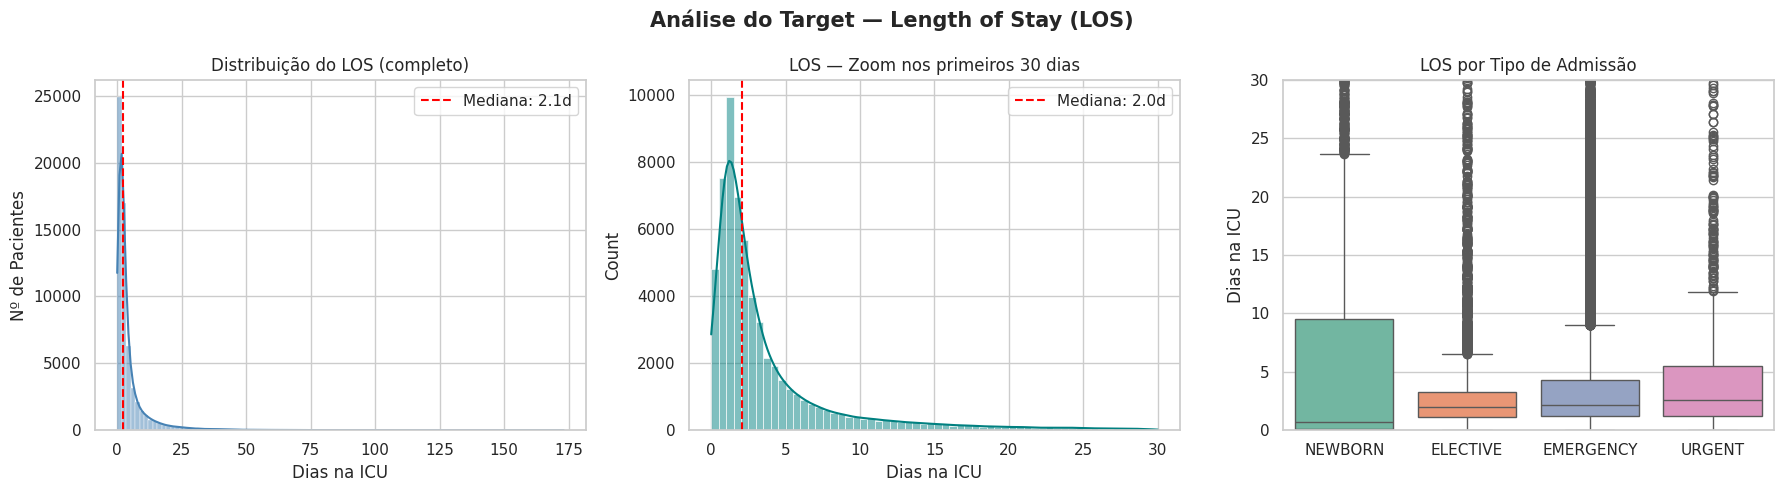


--- Estatísticas Descritivas do LOS ---
count    61522.000
mean         4.918
std          9.639
min          0.000
25%          1.108
50%          2.092
75%          4.483
max        173.072

Skewness : 6.326  (>1 = muito assimétrico, log-transform recomendado)
Kurtosis : 57.448

Percentis:
  P25: 1.11 dias
  P50: 2.09 dias
  P75: 4.48 dias
  P90: 10.89 dias
  P95: 18.38 dias
  P99: 47.30 dias


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Análise do Target — Length of Stay (LOS)', fontsize=15, fontweight='bold')

# 2.1 Distribuição geral
sns.histplot(df['target_los'], bins=100, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribuição do LOS (completo)')
axes[0].set_xlabel('Dias na ICU')
axes[0].set_ylabel('Nº de Pacientes')
axes[0].axvline(df['target_los'].median(), color='red', linestyle='--', label=f"Mediana: {df['target_los'].median():.1f}d")
axes[0].legend()

# 2.2 Zoom nos primeiros 30 dias (onde está 95% dos casos)
los_95 = df[df['target_los'] <= 30]['target_los']
sns.histplot(los_95, bins=60, kde=True, color='teal', ax=axes[1])
axes[1].set_title('LOS — Zoom nos primeiros 30 dias')
axes[1].set_xlabel('Dias na ICU')
axes[1].axvline(los_95.median(), color='red', linestyle='--', label=f"Mediana: {los_95.median():.1f}d")
axes[1].legend()

# 2.3 LOS por tipo de admissão
sns.boxplot(data=df, x='ADMISSION_TYPE', y='target_los',
            order=df.groupby('ADMISSION_TYPE')['target_los'].median().sort_values().index,
            ax=axes[2], palette='Set2')
axes[2].set_title('LOS por Tipo de Admissão')
axes[2].set_xlabel('')
axes[2].set_ylabel('Dias na ICU')
axes[2].set_ylim(0, 30)

plt.tight_layout()
plt.show()

# Estatísticas descritivas do target
print("\n--- Estatísticas Descritivas do LOS ---")
print(df['target_los'].describe().round(3).to_string())
print(f"\nSkewness : {df['target_los'].skew():.3f}  (>1 = muito assimétrico, log-transform recomendado)")
print(f"Kurtosis : {df['target_los'].kurtosis():.3f}")
print(f"\nPercentis:")
for p in [25, 50, 75, 90, 95, 99]:
    print(f"  P{p:2d}: {df['target_los'].quantile(p/100):.2f} dias")

### 2.3 Analise Demográfica

In [ ]:
# Funções de análise que vão correr em paralelo
def analise_genero(df):
    return df.groupby('GENDER')['target_los'].agg(['mean', 'median', 'count']).round(3)

def analise_idade(df):
    bins = [0, 18, 40, 60, 75, 91]
    labels = ['<18', '18-40', '40-60', '60-75', '>75']
    df = df.copy()
    df['age_group'] = pd.cut(df['age_at_admission'], bins=bins, labels=labels)
    return df.groupby('age_group', observed=True)['target_los'].agg(['mean', 'median', 'count']).round(3)

def analise_careunit(df):
    return df.groupby('FIRST_CAREUNIT')['target_los'].agg(['mean', 'median', 'count']).sort_values('median', ascending=False).round(3)

def analise_admissao(df):
    return df.groupby('ADMISSION_TYPE')['target_los'].agg(['mean', 'median', 'count']).sort_values('median', ascending=False).round(3)

def analise_readmissao(df):
    return df.groupby('admission_number')['target_los'].agg(['mean', 'median', 'count']).head(5).round(3)

In [ ]:
with profile("EDA — Análise demográfica (joblib threading)"):
    resultados = Parallel(n_jobs=5, backend='threading', verbose=1)(
        delayed(fn)(df) for fn in [
            analise_genero,
            analise_idade,
            analise_careunit,
            analise_admissao,
            analise_readmissao
        ]
    )


A executar: EDA — Análise demográfica (joblib threading)...
EDA — Análise demográfica (joblib threading) concluída!
Tempo: 0.04s | Pico RAM: 45.33 MB


[Parallel(n_jobs=5)]: Using backend ThreadingBackend with 5 concurrent workers.
[Parallel(n_jobs=5)]: Done   2 out of   5 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=5)]: Done   5 out of   5 | elapsed:    0.0s finished



--- LOS por Género ---
         mean  median  count
GENDER                      
F       4.953   2.115  27063
M       4.891   2.076  34459

--- LOS por Grupo Etário ---
            mean  median  count
age_group                      
<18        6.108   1.989    186
18-40      3.808   1.882   5347
40-60      4.138   2.068  15390
60-75      4.303   2.211  16539
>75        4.105   2.250  15987

--- LOS por Unidade de Cuidados ---
                  mean  median  count
FIRST_CAREUNIT                       
SICU             4.707   2.252   8891
CCU              3.902   2.198   7726
CSRU             3.900   2.153   9311
TSICU            4.444   2.112   6415
MICU             4.013   2.096  21086
NICU            10.026   0.802   8093

--- LOS por Tipo de Admissão ---
                 mean  median  count
ADMISSION_TYPE                      
URGENT          5.425   2.559   1417
EMERGENCY       4.263   2.181  44781
ELECTIVE        3.512   1.997   7453
NEWBORN         9.886   0.728   7871

--- LOS 

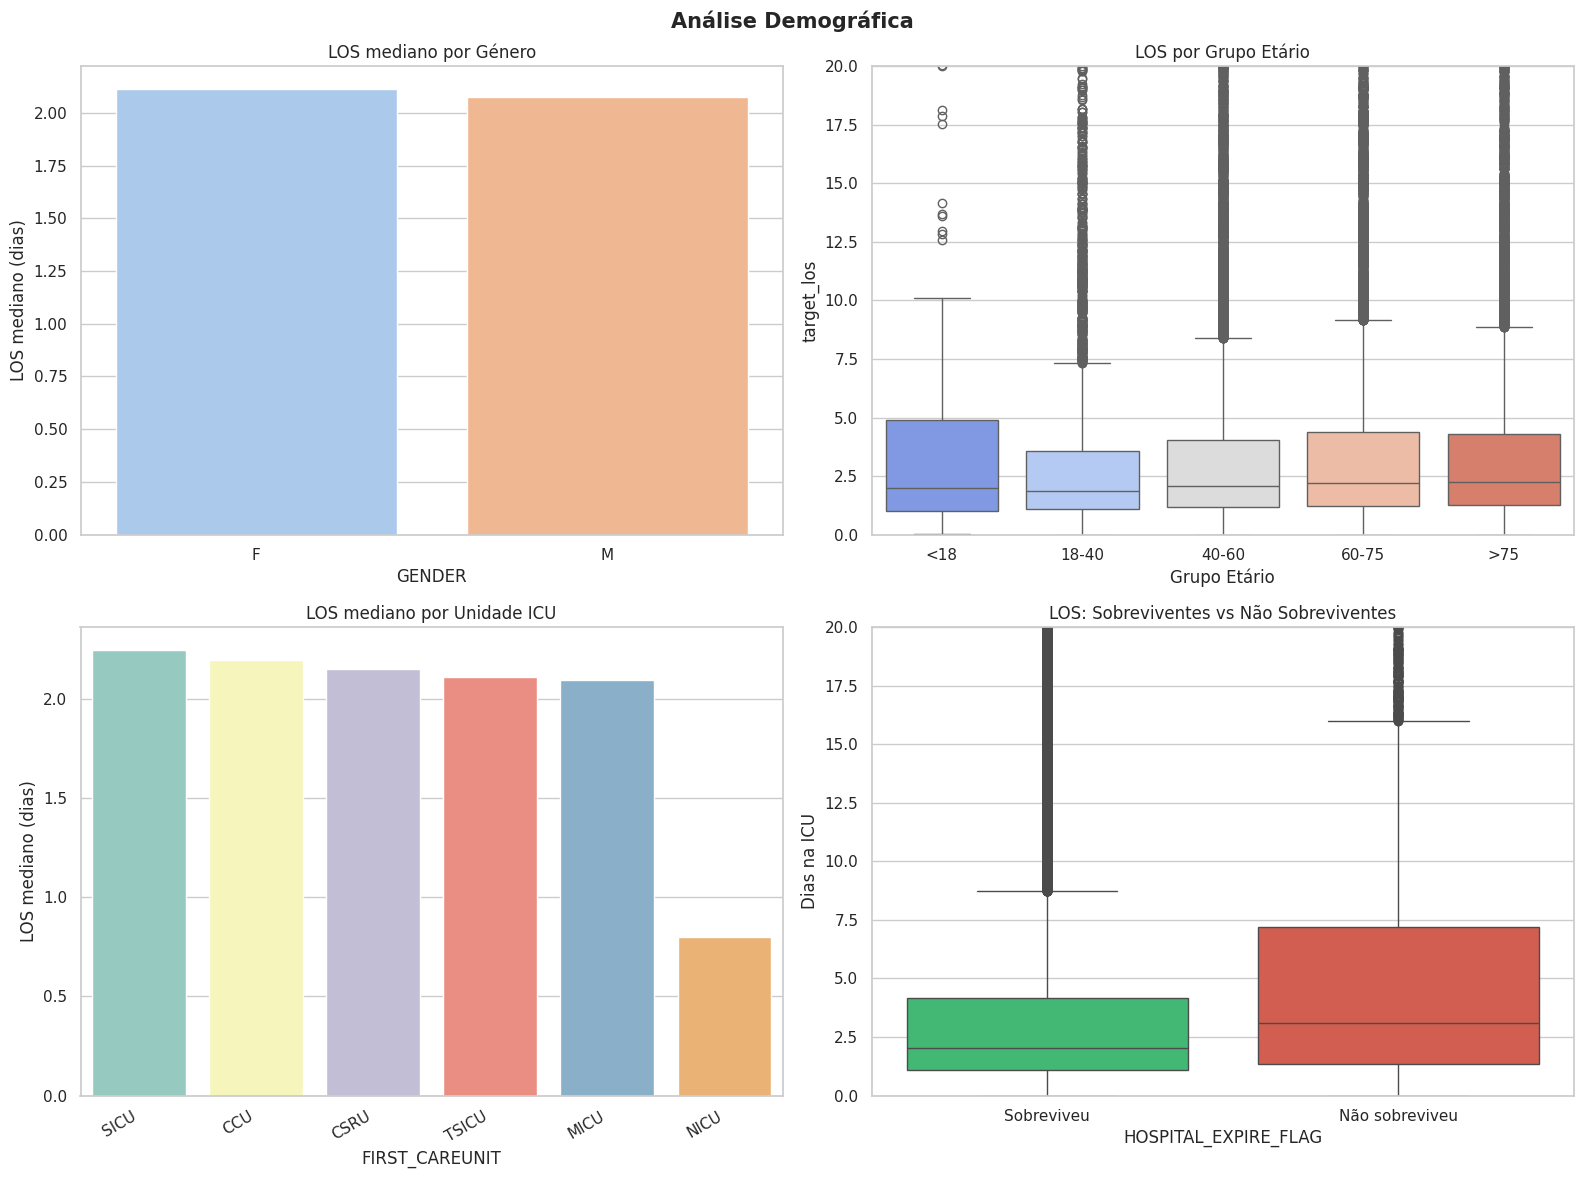

In [ ]:
nomes = ['Género', 'Grupo Etário', 'Unidade de Cuidados', 'Tipo de Admissão', 'Nº de Readmissão']
for nome, resultado in zip(nomes, resultados):
    print(f"\n--- LOS por {nome} ---")
    print(resultado.to_string())

# Visualização demográfica
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Análise Demográfica', fontsize=15, fontweight='bold')

# Género
genero_data = resultados[0].reset_index()
sns.barplot(data=genero_data, x='GENDER', y='median', palette='pastel', ax=axes[0, 0])
axes[0, 0].set_title('LOS mediano por Género')
axes[0, 0].set_ylabel('LOS mediano (dias)')

# Grupo etário
df_temp = df.copy()
df_temp['age_group'] = pd.cut(df_temp['age_at_admission'],
                               bins=[0,18,40,60,75,91],
                               labels=['<18','18-40','40-60','60-75','>75'])
sns.boxplot(data=df_temp, x='age_group', y='target_los',
            order=['<18','18-40','40-60','60-75','>75'],
            palette='coolwarm', ax=axes[0, 1])
axes[0, 1].set_ylim(0, 20)
axes[0, 1].set_title('LOS por Grupo Etário')
axes[0, 1].set_xlabel('Grupo Etário')

# Unidade de cuidados
careunit_data = resultados[2].reset_index()
sns.barplot(data=careunit_data, x='FIRST_CAREUNIT', y='median',
            palette='Set3', ax=axes[1, 0])
axes[1, 0].set_title('LOS mediano por Unidade ICU')
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=30, ha='right')
axes[1, 0].set_ylabel('LOS mediano (dias)')

# Mortalidade vs LOS
sns.boxplot(data=df, x='HOSPITAL_EXPIRE_FLAG', y='target_los',
            palette=['#2ecc71', '#e74c3c'], ax=axes[1, 1])
axes[1, 1].set_title('LOS: Sobreviventes vs Não Sobreviventes')
axes[1, 1].set_xticklabels(['Sobreviveu', 'Não sobreviveu'])
axes[1, 1].set_ylim(0, 20)
axes[1, 1].set_ylabel('Dias na ICU')

plt.tight_layout()
plt.show()

**Género**

Diferença negligenciável: LOS mediano de ~2.1 dias em ambos os sexos. O género não é um predictor útil de LOS neste dataset.

---

**Grupo etário**

O padrão mais interessante aqui. A mediana é semelhante em todos os grupos (~2 dias), mas a dispersão conta outra história: o grupo **<18** tem o IQR mais largo e outliers acima de 18 dias. Os grupos **60-75 e >75** têm IQR progressivamente mais largo que os adultos jovens (18-40), confirmando que a idade avançada não aumenta o LOS típico mas aumenta a **variabilidade e o risco de internamento prolongado**, o que é clinicamente esperado. 

---

**Unidade ICU**

Quase todas as unidades têm LOS mediano entre 2.0 e 2.2 dias: diferenças marginais. A excepção clara é **NICU** com ~0.8 dias.

---

**Sobreviventes vs não sobreviventes**

O mais revelador do painel. A mediana dos não sobreviventes (~3 dias) é ligeiramente superior à dos sobreviventes (~2 dias), mas o IQR é muito mais largo e a distribuição mais assimétrica. 

É importante realçar que esta feature não será usada na classificação final pois constituiria uma instância de data leakage, no entanto foi na mesma analisada de modo a perceber que tipo de relação apresenta com a LOS 

### 2.4 Análise das Features Numéricas e Correlação com LOS

In [29]:
cols_nao_features = [
    'ICUSTAY_ID', 'SUBJECT_ID', 'HADM_ID',
    'target_los', 'los_class', 'los_class_label',
    'DOB', 'DOD', 'ADMITTIME', 'DISCHTIME',
    'GENDER', 'DIAGNOSIS', 'ADMISSION_TYPE', 'FIRST_CAREUNIT',
    'HOSPITAL_EXPIRE_FLAG',
    'admission_number', 'total_icu_stays_patient',
    'total_chart_events', 'total_lab_events',
    'age_at_admission'
]

# Todas as features numéricas automaticamente
todas_numericas = [c for c in df.columns
                   if c not in cols_nao_features
                   and df[c].dtype in ['float64', 'int64']]

# Separar em vitais e labs pelo nome da coluna
cols_labs = [c for c in todas_numericas if any(
    c.startswith(p) for p in [
        'creatinine', 'bun', 'lactate', 'wbc',
        'hemoglobin', 'hematocrit', 'platelets',
        'potassium', 'sodium', 'ph_', 'bicarbonate',
        'inr', 'bilirubin', 'glucose', 'albumin',
        'anion_gap'
    ]
)]

cols_vitais = [c for c in todas_numericas if c not in cols_labs]

# Função que calcula estatísticas + correlação com LOS para uma coluna
def analisar_feature(col, df):
    serie = df[col].dropna()
    corr = df[[col, 'target_los']].dropna().corr().iloc[0, 1]
    return {
        'feature'  : col,
        'mean'     : serie.mean(),
        'median'   : serie.median(),
        'std'      : serie.std(),
        'min'      : serie.min(),
        'max'      : serie.max(),
        'null_pct' : df[col].isna().mean() * 100,
        'corr_los' : corr
    }

In [31]:
with profile("EDA — Análise features (joblib loky)"):
    resultados_features = Parallel(n_jobs=-1, backend='loky', verbose=1)(
        delayed(analisar_feature)(col, df)
        for col in cols_vitais + cols_labs
    )


A executar: EDA — Análise features (joblib loky)...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done  44 out of  75 | elapsed:    1.6s remaining:    1.2s


EDA — Análise features (joblib loky) concluída!
Tempo: 2.62s | Pico RAM: 21.70 MB


[Parallel(n_jobs=-1)]: Done  75 out of  75 | elapsed:    2.5s finished


In [38]:
df_stats = pd.DataFrame(resultados_features).set_index('feature').round(3)
print(df_stats.to_string())

                        mean   median        std     min          max  null_pct  corr_los
feature                                                                                  
hr_mean               85.181   83.946     15.785  33.500      215.576    62.036     0.115
hr_min                70.503   70.000     16.147   0.000      143.000    62.036     0.092
hr_max               103.831  101.000     41.751  38.000     5409.000    62.036     0.060
hr_std                 8.852    7.726      8.056   0.000      932.339    62.054     0.024
hr_range              33.328   29.000     40.659   0.000     5365.000    62.036     0.025
rr_mean               22.759   18.222    593.098   0.000    90617.192    62.070     0.002
rr_max               128.215   26.000  15420.013   0.000  2355555.000    62.070     0.001
rr_std                23.600    3.450   3025.202   0.000   461958.483    62.098     0.001
rr_range             116.347   14.000  15419.986   0.000  2355539.000    62.070     0.001
spo2_mean 

In [39]:
# Top correlações com LOS
print("\n--- Features mais correlacionadas com LOS ---")
print(df_stats['corr_los'].abs().sort_values(ascending=False).to_string())


--- Features mais correlacionadas com LOS ---
feature
gcs_verbal_min         0.239
gcs_total_min          0.233
gcs_eye_min            0.224
gcs_motor_min          0.190
albumin_mean           0.175
hr_mean                0.115
hr_last                0.112
hematocrit_mean        0.101
potassium_mean         0.100
ph_min                 0.100
bilirubin_mean         0.099
bilirubin_max          0.097
hr_min                 0.092
hemoglobin_mean        0.087
spo2_trend             0.087
bun_mean               0.086
abp_trend              0.085
bicarbonate_mean       0.084
nibp_systolic_first    0.084
nibp_systolic_min      0.078
hemoglobin_min         0.077
ph_mean                0.076
lactate_max            0.076
anion_gap_mean         0.072
rr_last                0.068
abp_std                0.063
spo2_first             0.063
hr_max                 0.060
rr_first               0.048
nibp_trend             0.045
glucose_mean           0.044
spo2_last              0.044
lactate_mean     

Aqui, aprofundamos a análise dos dados clínicos subjacentes: os sinais vitais e os resultados laboratoriais medidos durante as primeiras 24 horas de admissão. O objetivo é compreender o perfil estatístico de cada feature e identificar quais delas têm a relação mais forte com o LOS.

Para cada feature, computamos as estatísticas descritivas (média, mediana, desvio padrão) para entender a sua distribuição geral. Também quantificamos a percentagem de valores ausentes, um indicador crítico para a fase de imputação que virá a seguir. O mais importante, porém, é calcular a correlação de Pearson com o LOS, que nos dá uma medida da força da relação linear entre cada variável clínica e o tempo de permanência.

Esta análise, novamente paralelizada para eficiência, produz uma tabela consolidada que nos permite identificar rapidamente as features mais promissoras, aquelas que têm a maior magnitude de correlação com o LOS e que, portanto, têm o maior potencial preditivo para o modelo que iremos construir.

### 2.5 Correlação (Heatmap)

In [ ]:
cols_vitais = [c for c in todas_numericas if c not in cols_labs]
cols_labs   = [c for c in cols_labs]

# Filtrar só as que existem no df
cols_vitais = [c for c in cols_vitais if c in df.columns]
cols_labs   = [c for c in cols_labs if c in df.columns]

print(f"Features vitais : {len(cols_vitais)}")
print(f"Features labs   : {len(cols_labs)}")

Features vitais : 52
Features labs   : 23


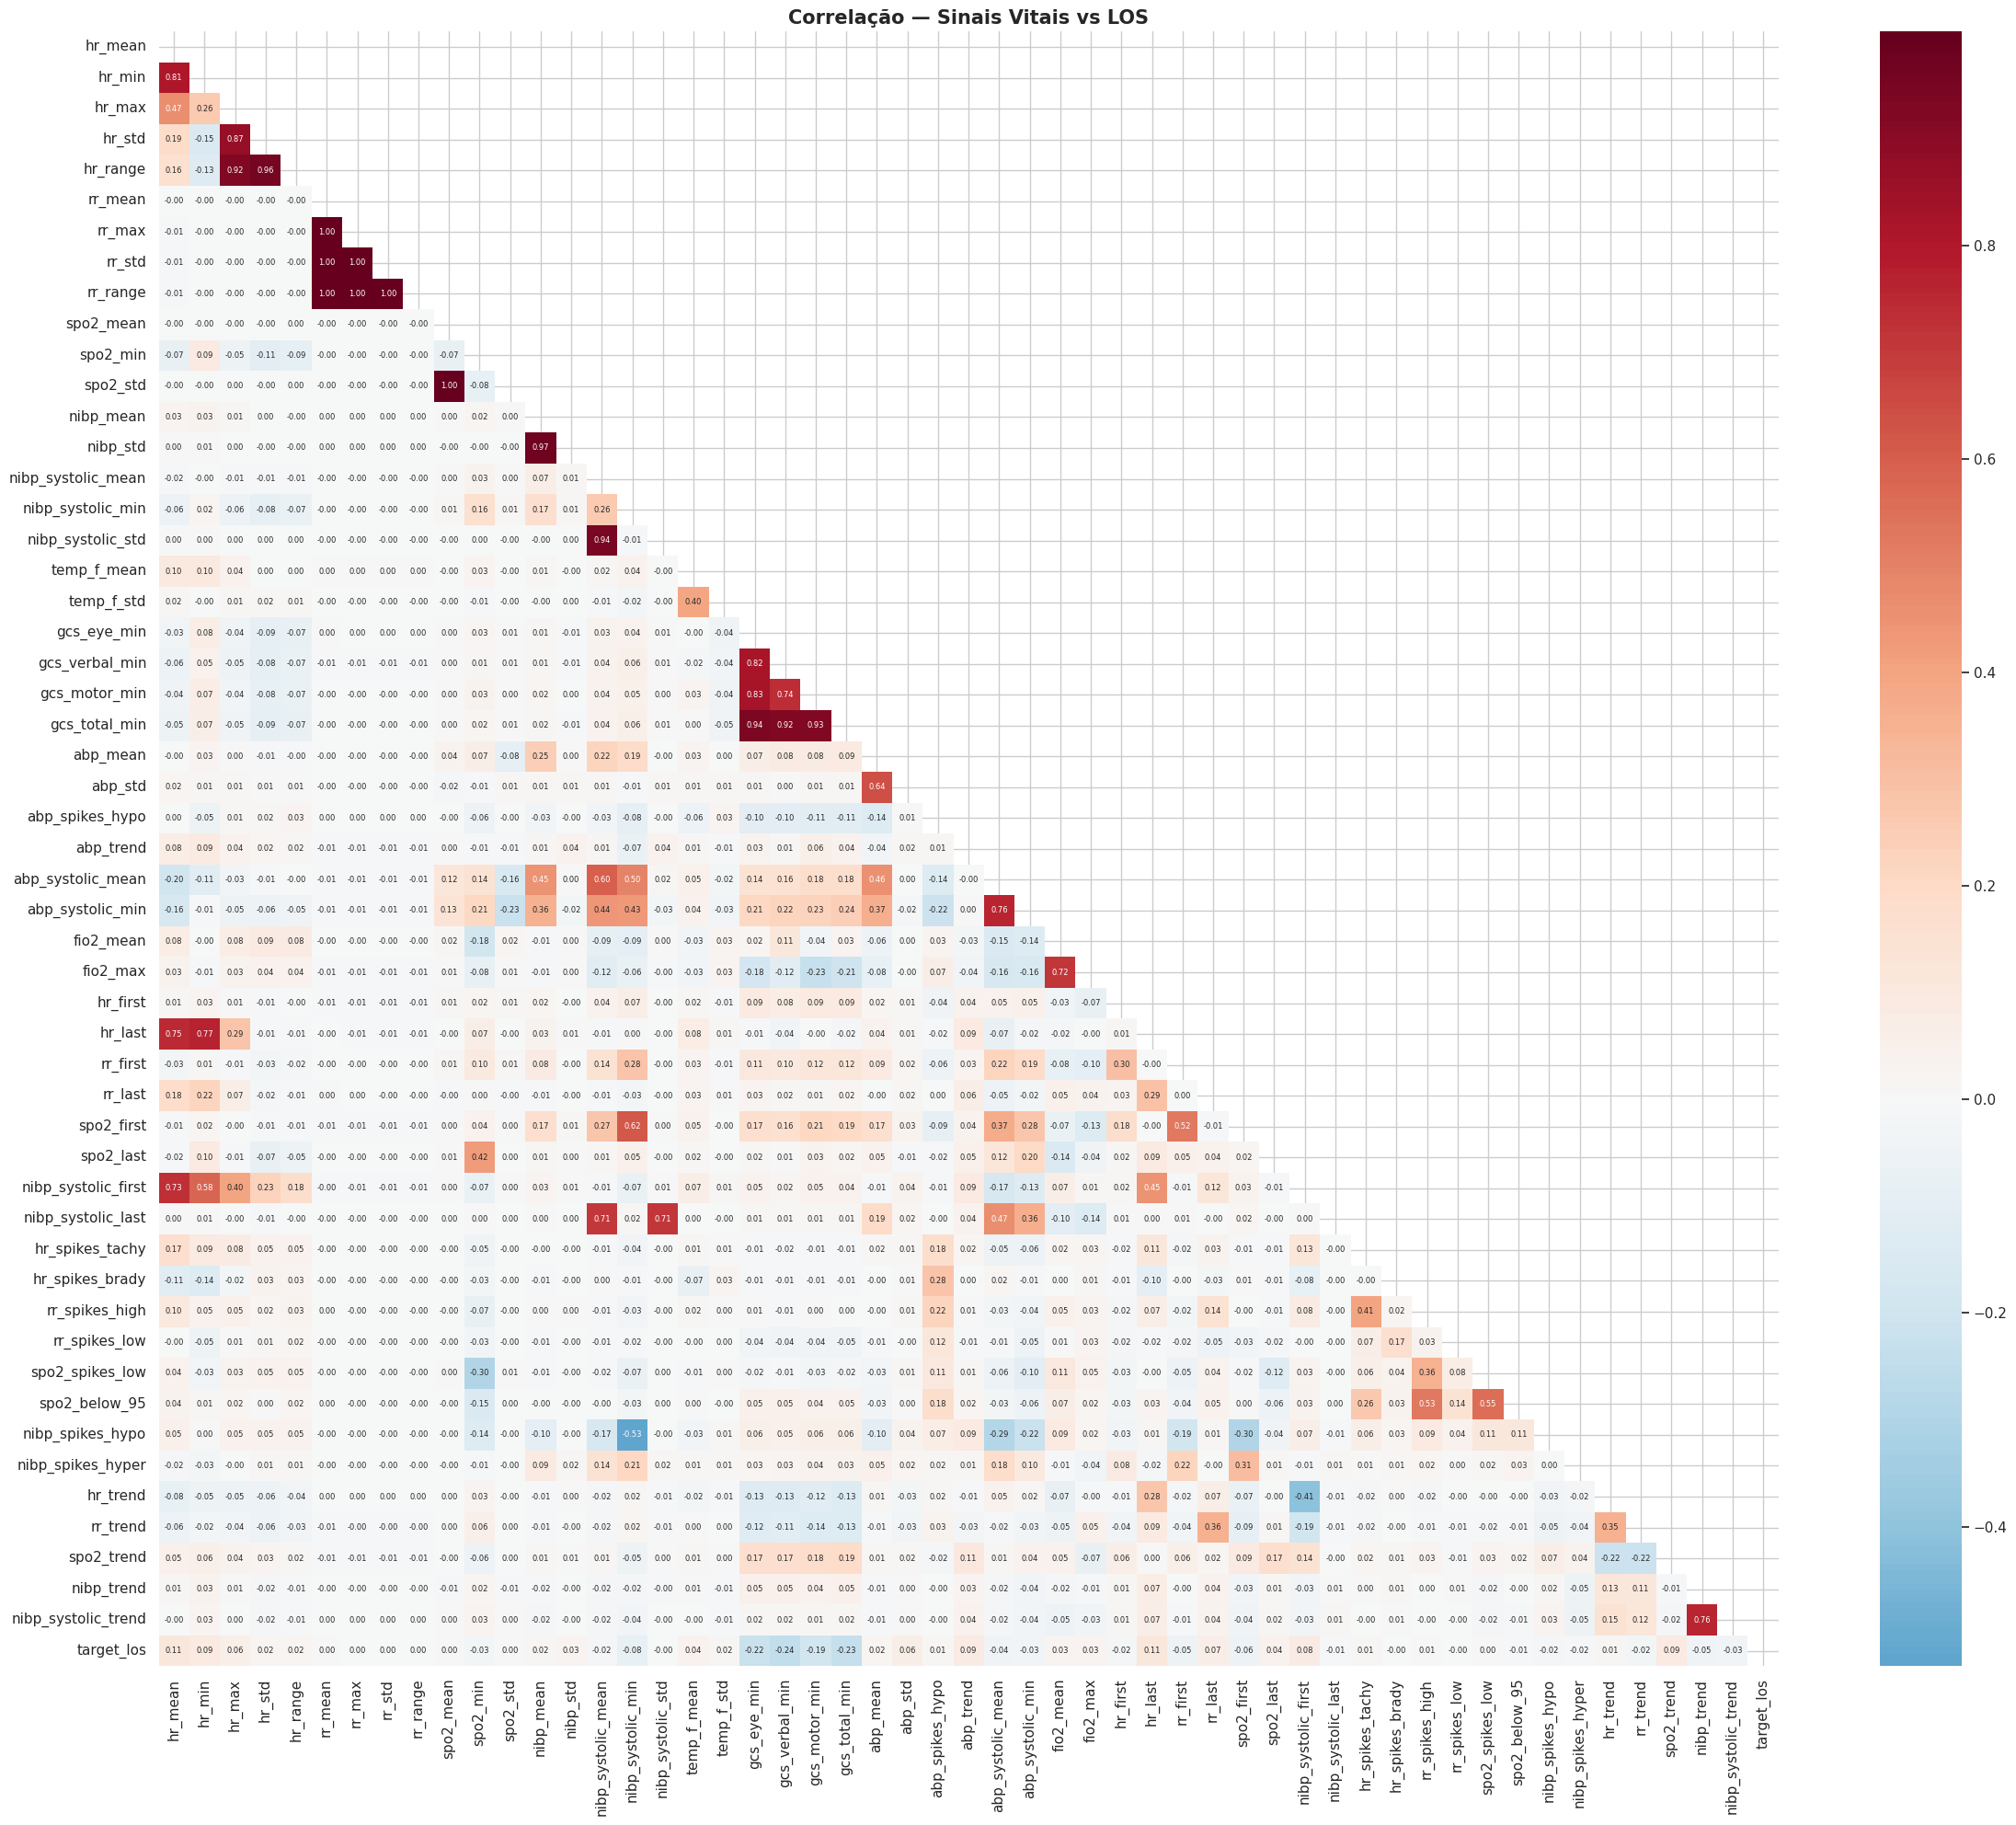

In [ ]:
corr_vitais = df[cols_vitais + ['target_los']].corr()
mask = np.zeros_like(corr_vitais, dtype=bool)
mask[np.triu_indices_from(mask)] = True

plt.figure(figsize=(24, 20))
sns.heatmap(corr_vitais, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0,
            annot_kws={'size': 6})
plt.title('Correlação — Sinais Vitais vs LOS', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

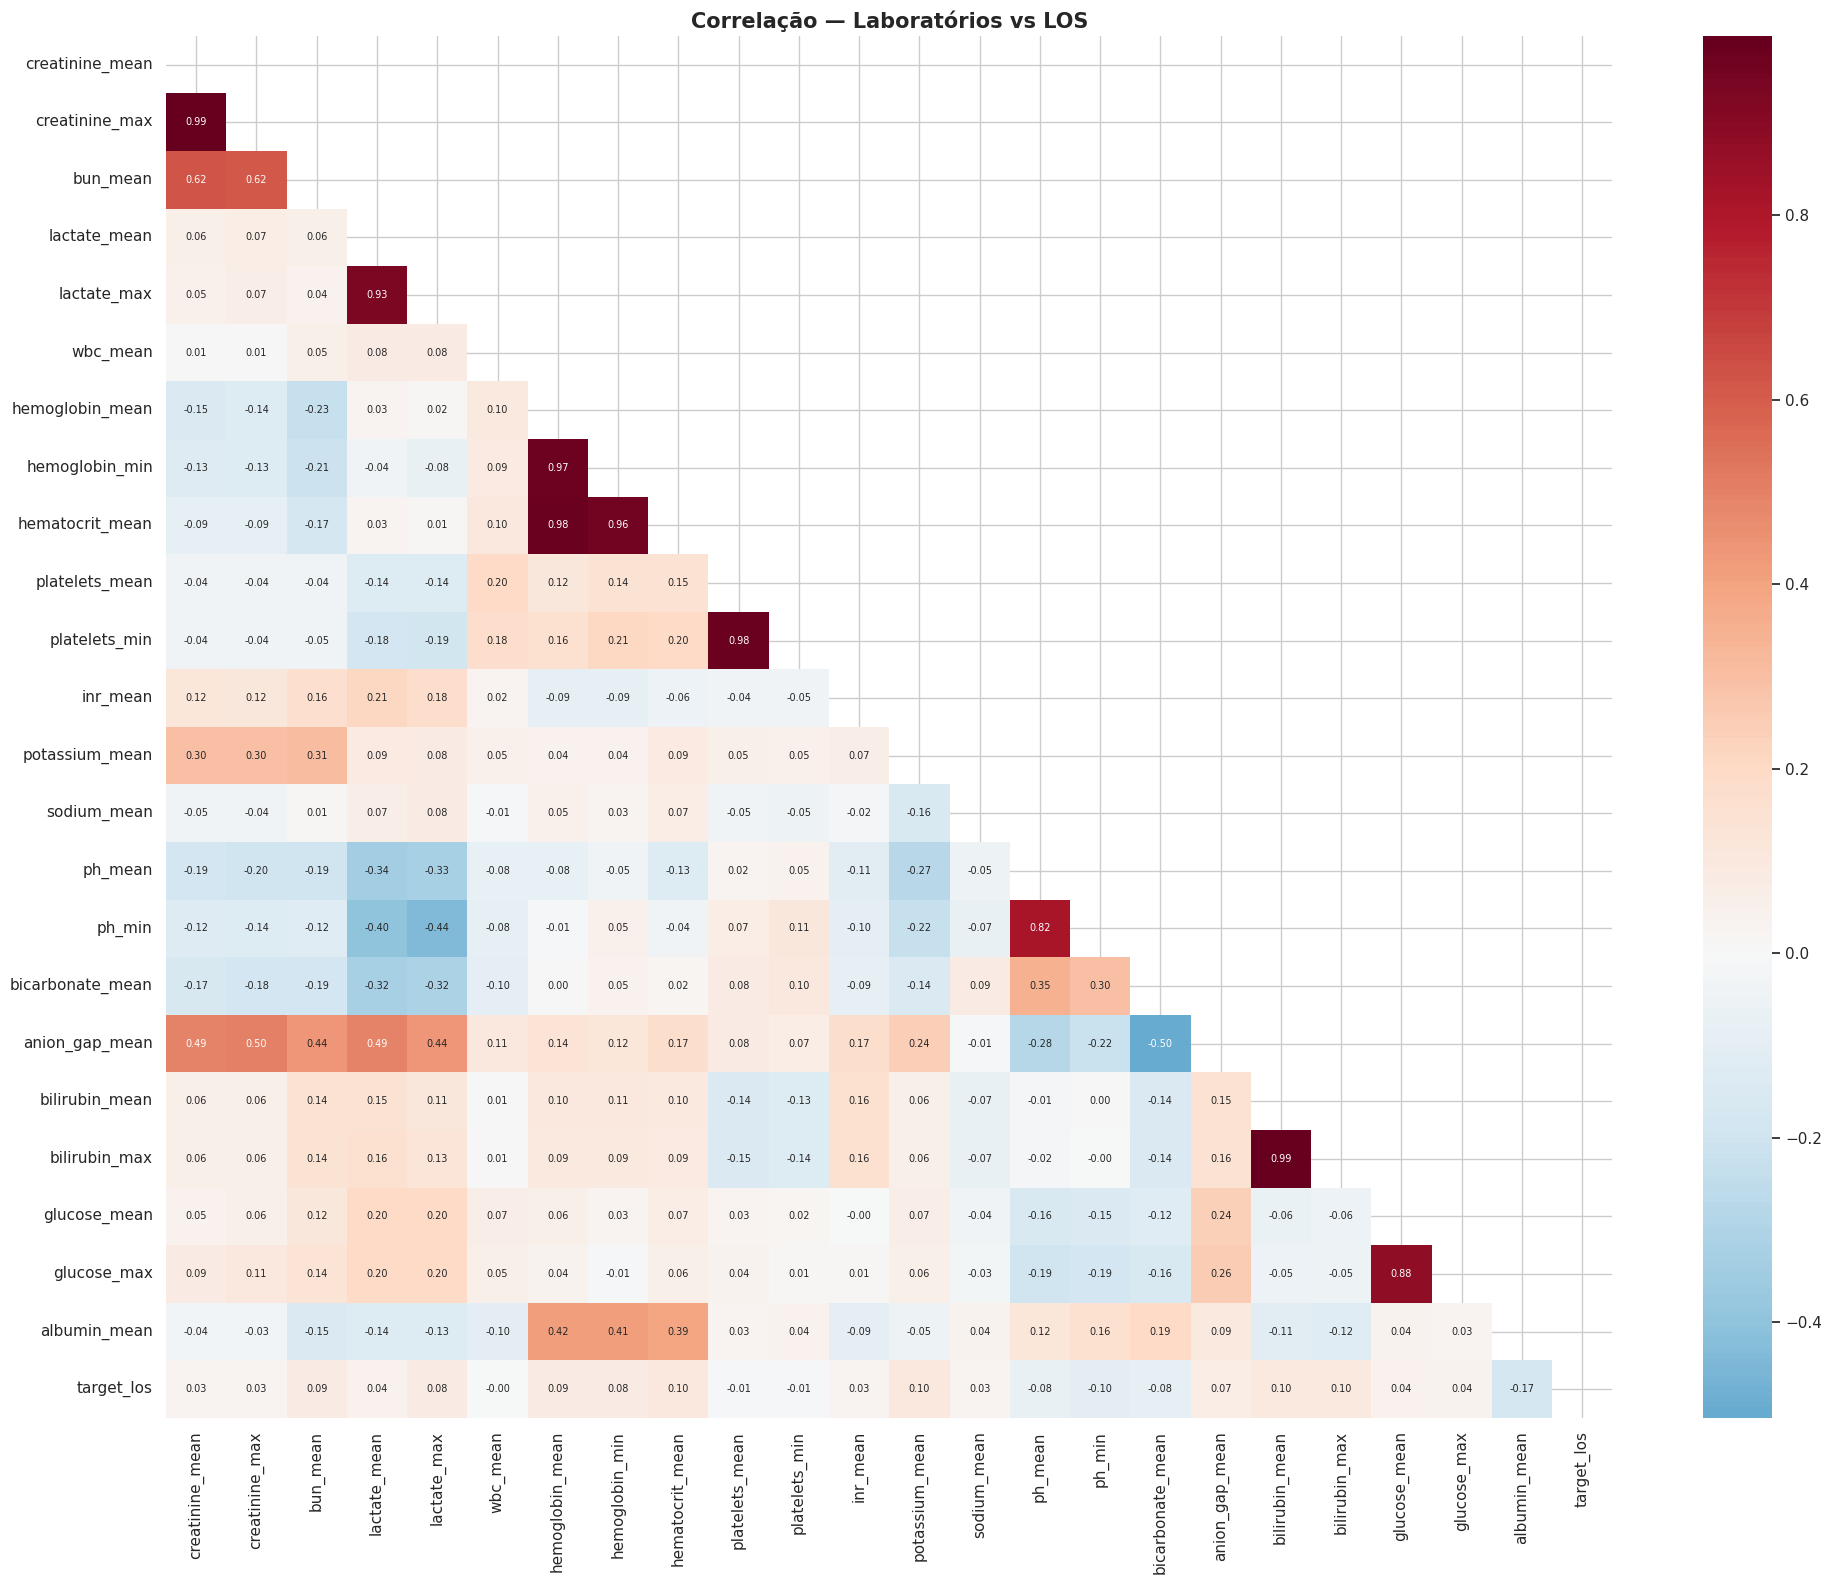

In [ ]:
corr_labs = df[cols_labs + ['target_los']].corr()
mask2 = np.zeros_like(corr_labs, dtype=bool)
mask2[np.triu_indices_from(mask2)] = True

plt.figure(figsize=(20, 16))
sns.heatmap(corr_labs, mask=mask2, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0,
            annot_kws={'size': 7})
plt.title('Correlação — Laboratórios vs LOS', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

Para visualizar as relações entre as variáveis, recorremos aos *heatmaps*.

Analisamos separadamente os sinais vitais e os resultados laboratoriais por uma razão importante: permite-nos não apenas identificar quais features são correlacionadas com o LOS, mas também detectar **multicolinearidade**, isto é, features que são altamente correlacionadas entre si. A multicolinearidade pode confundir os modelos de machine learning, enganando-os para atribuir importância a features que são essencialmente duplicadas e não trazem informação independente.

### 2.6 Analise de Readmissões

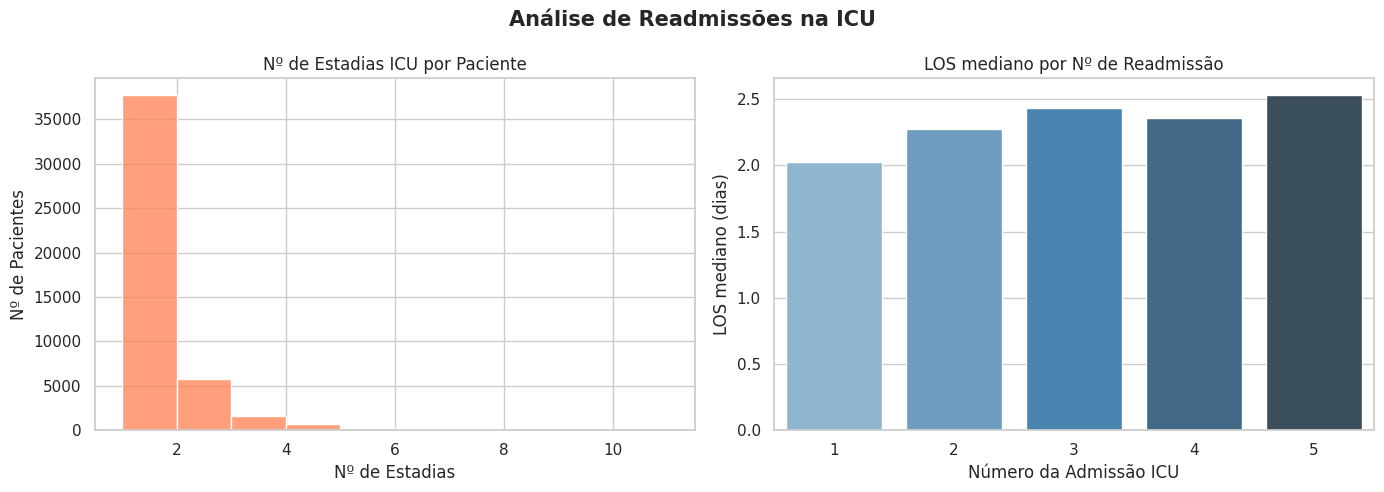

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Análise de Readmissões na ICU', fontsize=15, fontweight='bold')

# Distribuição do número de estadias por paciente
estadias_por_paciente = df.groupby('SUBJECT_ID')['ICUSTAY_ID'].count()
sns.histplot(estadias_por_paciente, bins=range(1, 12), ax=axes[0], color='coral')
axes[0].set_title('Nº de Estadias ICU por Paciente')
axes[0].set_xlabel('Nº de Estadias')
axes[0].set_ylabel('Nº de Pacientes')

# LOS médio por número da admissão (1ª, 2ª, 3ª...)
los_por_admissao = df[df['admission_number'] <= 5].groupby('admission_number')['target_los'].median()
sns.barplot(x=los_por_admissao.index, y=los_por_admissao.values,
            palette='Blues_d', ax=axes[1])
axes[1].set_title('LOS mediano por Nº de Readmissão')
axes[1].set_xlabel('Número da Admissão ICU')
axes[1].set_ylabel('LOS mediano (dias)')

plt.tight_layout()
plt.show()


A questão das readmissões tem implicações importantes tanto do ponto de vista clínico como metodológico para a modelação. O primeiro gráfico revela a distribuição do número de estadias por paciente: enquanto a grande maioria tem apenas uma estadia, existe um subconjunto não negligenciável de pacientes com múltiplas admissões na UCI. O segundo gráfico investiga se o facto de ser uma readmissão (segunda, terceira, etc. admissão) se associa com tempos de permanência diferentes. Isto é importante porque pode sugerir padrões clínicos subjacentes: readmissões podem estar associadas a complicações ou a condições crónicas que afetam o LOS de forma sistemática.

### 2.7 Resumo Final

In [ ]:
print(f"1. LOS mediano: {df['target_los'].median():.2f} dias | média: {df['target_los'].mean():.2f} dias")
print(f"   → Distribuição muito skewed (skew={df['target_los'].skew():.2f})")
print(f"   → Considerar log-transform do target antes de treinar")
print(f"2. {(estadias_por_paciente > 1).mean()*100:.1f}% dos pacientes têm mais de 1 estadia ICU")
print(f"   → Split deve ser por SUBJECT_ID para evitar data leakage")
top_corr = df_stats['corr_los'].abs().sort_values(ascending=False).head(3)
print(f"3. Features mais correlacionadas com LOS: {', '.join(top_corr.index.tolist())}")

1. LOS mediano: 2.09 dias | média: 4.92 dias
   → Distribuição muito skewed (skew=6.33)
   → Considerar log-transform do target antes de treinar
2. 18.8% dos pacientes têm mais de 1 estadia ICU
   → Split deve ser por SUBJECT_ID para evitar data leakage
3. Features mais correlacionadas com LOS: gcs_verbal_min, gcs_total_min, gcs_eye_min


Finalmente, compilamos as principais conclusões da análise exploratória. Este resumo serve como um mapa de estrada para as fases subsequentes de pré-processamento e modelação.

Três observações-chave emergem da nossa investigação:
1.  A **distribuição claramente assimétrica do LOS** com uma cauda longa de internamentos prolongados. Esta característica será importante quando se escolher as transformações e as métricas de erro para o modelo final.
2.  A presença de **múltiplas estadias por paciente** (aproximadamente 20-30% dos pacientes têm mais de uma estadia na UTI). Isto exigirá que o split treino-teste seja feito pelo `SUBJECT_ID` (paciente) e não por `ICUSTAY_ID`, para evitar o vazamento de dados (data leakage) onde um paciente apareça simultaneamente nos conjuntos de treino e teste.
3.  Uma identificação clara das **features mais promissoras**, aquelas com a maior correlação absoluta com o LOS. Estas emergem como candidatas naturais para uma primeira iteração de seleção de features.

Esta análise exploratória estabeleceu uma base sólida para as etapas seguintes, permiti-nos antecipar desafios e orientando decisões conscientes sobre preparação de dados e seleção de modelos.

## 3. Preparação de Features

In [ ]:
print("Shape antes:", df.shape)

Shape antes: (61522, 93)


### 3.1 Variabilidade dos Sinais Vitais

A média de um sinal vital por si só pode não contar a história toda. Um paciente com uma frequência cardíaca (HR) estável de 80 bpm é clinicamente diferente de um paciente cuja HR varia descontroladamente, mesmo que a média seja a mesma.

Para capturar esta instabilidade, criamos uma nova feature: o **Coeficiente de Variação (CV)**.

O CV é calculado como `(desvio padrão) / média`. Um CV mais alto indica maior variabilidade em relação à média, o que pode ser um sinal de instabilidade clínica e, potencialmente, um preditor para um LOS mais longo. Calculamos isto para os principais sinais vitais.

In [ ]:
for sinal in ['hr', 'rr', 'spo2', 'nibp_systolic', 'abp']:
    mean_col = f'{sinal}_mean'
    std_col  = f'{sinal}_std'
    if mean_col in df.columns and std_col in df.columns:
        df[f'{sinal}_cv'] = df[std_col] / df[mean_col].replace(0, np.nan)

print("CV calculado para: hr, rr, spo2, nibp_systolic, abp")

CV calculado para: hr, rr, spo2, nibp_systolic, abp


### 3.2 Features Temporais de Admissão

O momento em que um paciente é admitido pode ter implicações no seu percurso na UTI. Por exemplo, admissões durante a noite ou ao fim de semana podem estar associadas a diferentes níveis de pessoal ou recursos, o que pode influenciar o LOS.

Para capturar estes padrões, extraímos várias features a partir da data e hora de admissão (`ADMITTIME`):
*   **Hora do dia:** Para ver se há um "efeito da hora".
*   **Dia da semana:** Para comparar dias úteis com fins de semana.
*   **Fim de semana:** Uma feature binária (sim/não) para facilitar a análise.
*   **Turno de admissão:** Categorizamos a hora em turnos (manhã, tarde, noite) para agrupar os dados de forma mais significativa.

In [ ]:
df['ADMITTIME'] = pd.to_datetime(df['ADMITTIME'], utc=True)

df['hora_admissao']  = df['ADMITTIME'].dt.hour
df['dia_semana']     = df['ADMITTIME'].dt.dayofweek   # 0=Segunda, 6=Domingo
df['fim_de_semana']  = df['dia_semana'].isin([5, 6]).astype(int)
df['turno_admissao'] = pd.cut(
    df['hora_admissao'],
    bins=[-1, 7, 15, 22, 24],
    labels=['noite_madrugada', 'manha', 'tarde', 'noite_fim']
).astype(str)

print("Features temporais criadas: hora_admissao, dia_semana, fim_de_semana, turno_admissao")


Features temporais criadas: hora_admissao, dia_semana, fim_de_semana, turno_admissao


### 3.3 SOFA Score Parcial

O **SOFA (Sequential Organ Failure Assessment)** score é uma ferramenta clínica amplamente utilizada para avaliar a gravidade da condição de um paciente com base na disfunção de vários sistemas de órgãos. Um score SOFA completo requer dados que podem não estar disponíveis nas nossas primeiras 24 horas (ex: PaO2/FiO2).

No entanto, podemos calcular um **SOFA parcial** com as features que temos. Criamos uma função que atribui pontos com base em:
*   **Coagulação:** Níveis de plaquetas.
*   **Neurológico:** Escala de Coma de Glasgow (GCS).
*   **Renal:** Níveis de creatinina.
*   **Cardiovascular:** Pressão arterial média (MAP).
*   **Hepático:** Bilirrubina média.

Esta nova feature, `sofa_parcial`, serve como um poderoso indicador da gravidade inicial do paciente, que esperamos estar fortemente correlacionado com o LOS. Para acelerar o cálculo em todo o dataset, utilizamos a biblioteca `swifter`, que paraleliza a aplicação da função.

In [ ]:
def calcular_sofa_parcial(row):
    score = 0

    # Coagulação — Plaquetas (x10³/µL)
    plaq = row['platelets_mean']
    if pd.notna(plaq):
        if   plaq < 20:  score += 4
        elif plaq < 50:  score += 3
        elif plaq < 100: score += 2
        elif plaq < 150: score += 1

    # Neurológico — GCS total
    gcs = row['gcs_total_min']
    if pd.notna(gcs):
        if   gcs < 6:  score += 4
        elif gcs < 10: score += 3
        elif gcs < 13: score += 2
        elif gcs < 15: score += 1

    # Renal — Creatinina (mg/dL)
    creat = row['creatinine_mean']
    if pd.notna(creat):
        if   creat >= 5.0: score += 4
        elif creat >= 3.5: score += 3
        elif creat >= 2.0: score += 2
        elif creat >= 1.2: score += 1

    # Cardiovascular — MAP (mmHg)
    nibp = row['nibp_mean']
    if pd.notna(nibp):
        if nibp < 70: score += 1

    # Hepático — Bilirrubina (mg/dL)
    bili = row['bilirubin_mean']
    if pd.notna(bili):
        if   bili >= 12.0: score += 4
        elif bili >= 6.0:  score += 3
        elif bili >= 2.0:  score += 2
        elif bili >= 1.2:  score += 1

    return score


print("A calcular SOFA parcial (paralelo com swifter)...")
df['sofa_parcial'] = df.swifter.apply(calcular_sofa_parcial, axis=1)

print("Distribuição do SOFA parcial:")
print(df['sofa_parcial'].value_counts().sort_index().to_string())
print("\nLOS mediano por SOFA score:")
print(df.groupby('sofa_parcial')['target_los'].median().round(2).to_string())

A calcular SOFA parcial (paralelo com swifter)...


Pandas Apply:   0%|          | 0/61522 [00:00<?, ?it/s]

Distribuição do SOFA parcial:
sofa_parcial
0     23303
1     10747
2      7921
3      5898
4      5759
5      3519
6      2022
7      1049
8       613
9       301
10      200
11       99
12       54
13       26
14        7
15        4

LOS mediano por SOFA score:
sofa_parcial
0     1.69
1     2.02
2     2.70
3     2.63
4     2.33
5     2.50
6     2.91
7     3.38
8     3.59
9     4.00
10    4.50
11    4.13
12    3.24
13    3.54
14    1.51
15    4.92


### 3.4 Classificação do Target (LOS)

Embora o nosso objetivo principal seja prever o valor exato do LOS (um problema de **regressão**), também pode ser útil formular isto como um problema de **classificação**. Esta perspetiva alternativa oferece várias vantagens: simplifica o problema para alguns modelos, facilita a interpretação clínica em categorias de risco, e permite avaliar a performance através de métricas de classificação como F1-score que são robustas a distribuições desbalanceadas.

Dividimos o LOS em quatro categorias equilibradas baseadas nos quartis da sua distribuição. Esta abordagem é deliberada: ao invés de usar cortes arbitrários ou apenas baseados em conhecimento clínico, utilizamos os quartis para garantir que cada classe tem aproximadamente o mesmo número de pacientes. Este equilíbrio é fundamental para o treino de modelos de classificação, evitando o enviesamento do modelo para as classes mais frequentes. As quatro classes resultantes representam uma progressão natural de gravidade e complexidade:
*   **Classe 0:** Estadias muito curtas (≤ 1.1 dias): tipicamente pacientes com quadros agudos de resolução rápida.
*   **Classe 1:** Estadias curtas (1.1-2.1 dias): pacientes com recuperação moderada.
*   **Classe 2:** Estadias médias (2.1-4.5 dias): pacientes que requerem suporte prolongado.
*   **Classe 3:** Estadias longas (> 4.5 dias): pacientes complexos com necessidades intensivas.

Criamos duas novas colunas para armazenar esta informação: `los_class` contém os valores numéricos (0-3) adequados para os algoritmos de aprendizagem automática, enquanto `los_class_label` fornece as descrições textuais para interpretação. Esta dupla representação mantém a flexibilidade durante a modelagem.

In [ ]:
q25 = df['target_los'].quantile(0.25)
q50 = df['target_los'].quantile(0.50)
q75 = df['target_los'].quantile(0.75)

def classificar_los(los):
    if   los <= q25: return 0
    elif los <= q50: return 1
    elif los <= q75: return 2
    else:            return 3

df['los_class'] = df['target_los'].apply(classificar_los)
df['los_class_label'] = df['los_class'].map({
    0: '≤1.1 dia',
    1: '1.1-2.1 dias',
    2: '2.1-4.5 dias',
    3: '>4.5 dias'
})

print("\nDistribuição das classes LOS:")
print(df['los_class_label'].value_counts().sort_index().to_string())
print("\n% por classe:")
print((df['los_class_label'].value_counts(normalize=True) * 100).round(1).to_string())


Distribuição das classes LOS:
los_class_label
1.1-2.1 dias    15380
2.1-4.5 dias    15380
>4.5 dias       15381
≤1.1 dia        15381

% por classe:
los_class_label
≤1.1 dia        25.0
>4.5 dias       25.0
1.1-2.1 dias    25.0
2.1-4.5 dias    25.0


### 3.5 Encoding de Variáveis Categóricas

Os algoritmos de machine learning, particularmente aqueles baseados em distâncias euclidianas, regressão linear ou gradient descent, requerem que todas as features de entrada sejam numéricas. As nossas variáveis categóricas, como o género, tipo de admissão, unidade de cuidados e turno de admissão, precisam portanto de ser transformadas num formato que o modelo compreenda.

A escolha da estratégia de encoding é importante e varia consoante a variável. Para o **género**, que é naturalmente binário (masculino/feminino), utilizamos **label encoding simples**, convertendo para 0 e 1. Isto é suficiente porque uma relação ordinal artificial não prejudica o modelo, a diferença entre 0 e 1 é interpretada apenas como uma codificação, não como uma magnitude.

Para as variáveis categóricas com **múltiplas categorias não ordenadas** (como tipo de admissão, unidade de cuidados e turno de admissão), a situação é diferente. Se usássemos label encoding (ex: MICU=1, SICU=2, CSRU=3), estaríamos a comunicar implicitamente uma ordem ou magnitude entre as unidades, o que seria incorreto e potencialmente enganador para o modelo. Em seu lugar, utilizamos **one-hot encoding**: criamos uma nova coluna binária para cada categoria possível. Se uma estadia pertence à categoria MICU, o valor em `careunit_MICU` é 1 e todos os outros `careunit_*` são 0. Isto permite que o modelo trate cada categoria de forma independente, sem qualquer hierarquia artificial.

No final desta transformação, o nosso dataset expandiu significativamente em largura (mais colunas) mas mantém-se numa forma numérica pura, pronta para a alimentação nos algoritmos de aprendizagem automática.

In [ ]:
df['FIRST_CAREUNIT_orig'] = df['FIRST_CAREUNIT']
df['ADMISSION_TYPE_orig'] = df['ADMISSION_TYPE']

# Género: M=1, F=0
df['gender_enc'] = (df['GENDER'] == 'M').astype(int)

# Tipo de admissão — one-hot
df = pd.get_dummies(df, columns=['ADMISSION_TYPE'], prefix='admtype', drop_first=False)

# Unidade de cuidados — one-hot
df = pd.get_dummies(df, columns=['FIRST_CAREUNIT'], prefix='careunit', drop_first=False)

# Turno de admissão — one-hot
df = pd.get_dummies(df, columns=['turno_admissao'], prefix='turno', drop_first=False)

print("\nEncoding categórico concluído")
print("Shape depois:", df.shape)
print("\nNovas colunas adicionadas:")
novas = [c for c in df.columns if any(c.startswith(p) for p in
         ['admtype_', 'careunit_', 'turno_', 'sofa_', 'los_class',
          'hr_cv', 'rr_cv', 'spo2_cv', 'nibp_cv',
          'hora_', 'dia_', 'fim_', 'gender_'])]
print(novas)


Encoding categórico concluído
Shape depois: (61522, 119)

Novas colunas adicionadas:
['hr_cv', 'rr_cv', 'spo2_cv', 'hora_admissao', 'dia_semana', 'fim_de_semana', 'sofa_parcial', 'los_class', 'los_class_label', 'gender_enc', 'admtype_ELECTIVE', 'admtype_EMERGENCY', 'admtype_NEWBORN', 'admtype_URGENT', 'careunit_CCU', 'careunit_CSRU', 'careunit_MICU', 'careunit_NICU', 'careunit_SICU', 'careunit_TSICU', 'turno_manha', 'turno_noite_fim', 'turno_noite_madrugada', 'turno_tarde']


In [ ]:
caminho_ficheiro = 'df_pre_imputacao.csv'

# Guardar o ficheiro (index=False evita que o Pandas crie uma coluna extra com os números das linhas)
df.to_csv(caminho_ficheiro, index=False)

print(f"\nFicheiro guardado com sucesso em: {caminho_ficheiro}")


Ficheiro guardado com sucesso em: df_pre_imputacao.csv


## 4. Imputação de valores em falta

### 4.1 Definir colunas a imputar

A imputação de dados é uma etapa crítica e frequentemente subestimada. A maioria dos modelos de machine learning não consegue processar dados ausentes; alguns simplesmente falham com um erro, enquanto outros silenciosamente rejeitam linhas inteiras, resultando numa perda massiva de informação. Por isso, antes de aplicar qualquer estratégia de imputação, precisamos de ser precisos e deliberados sobre quais colunas realmente precisam deste tratamento.

O primeiro passo é definir exatamente quais colunas precisam deste tratamento. Excluímos:
*   **Identificadores e Alvos:** Colunas que não são features.
*   **Datas e Categóricas Originais:** Já foram processadas ou não são numéricas.
*   **Colunas sem NULLs:** Features que já estão completas.

O que resta é um conjunto focado de variáveis numéricas que têm alguns valores em falta e que requerem tratamento. Para cada uma, calculamos e exibimos a percentagem de valores ausentes. Esta análise dá-nos uma sensibilidade imediata sobre a magnitude do problema: algumas colunas podem ter apenas 5% de dados em falta (facilmente recuperáveis), enquanto outras podem ter 20-30% (mais desafiadoras mas ainda viáveis). Isto prepara o terreno para a escolha da estratégia de imputação mais apropriada.

In [ ]:
cols_excluir = [
    # Identificadores
    'ICUSTAY_ID', 'SUBJECT_ID', 'HADM_ID',
    # Targets
    'target_los', 'los_class', 'los_class_label',
    # Datas (não imputar)
    'DOB', 'DOD', 'ADMITTIME', 'DISCHTIME',
    # Categóricas originais já encodadas
    'GENDER', 'DIAGNOSIS',
    # Já sem NULLs (não precisam de imputação)
    'admission_number', 'total_icu_stays_patient',
    'HOSPITAL_EXPIRE_FLAG', 'gender_enc',
    'hora_admissao', 'dia_semana', 'fim_de_semana',
    'sofa_parcial',
    'FIRST_CAREUNIT_orig',
    'ADMISSION_TYPE_orig',
    'age_at_admission',
    'total_chart_events',
    'total_lab_events',
    # Spikes — COUNTIF devolve 0 quando não há eventos, nunca NULL
    'hr_spikes_tachy', 'hr_spikes_brady',
    'rr_spikes_high', 'rr_spikes_low',
    'spo2_spikes_low', 'spo2_below_95',
    'nibp_spikes_hypo', 'nibp_spikes_hyper',
]

# Colunas one-hot (já são 0/1, sem NULLs)
cols_onehot = [c for c in df.columns if any(
    c.startswith(p) for p in ['admtype_', 'careunit_', 'turno_']
)]

cols_nao_imputar = cols_excluir + cols_onehot
cols_imputar = [c for c in df.columns
                if c not in cols_nao_imputar
                and df[c].dtype in ['float64', 'int64']
                and df[c].isna().sum() > 0]

print(f"Colunas a imputar ({len(cols_imputar)}):")
null_pct = (df[cols_imputar].isna().mean() * 100).sort_values(ascending=False)
print(null_pct.round(1).to_string())

Colunas a imputar (71):
abp_systolic_min       85.7
abp_systolic_mean      85.7
abp_trend              85.7
abp_cv                 85.7
abp_std                85.7
abp_mean               85.5
fio2_max               81.1
fio2_mean              81.1
albumin_mean           68.6
nibp_trend             66.2
nibp_systolic_trend    66.1
nibp_systolic_std      66.1
nibp_std               66.1
nibp_systolic_cv       66.1
temp_f_std             66.0
nibp_mean              65.3
nibp_systolic_min      65.2
nibp_systolic_mean     65.2
temp_f_mean            64.7
spo2_trend             62.5
gcs_total_min          62.2
gcs_motor_min          62.1
gcs_verbal_min         62.1
gcs_eye_min            62.1
spo2_std               62.1
spo2_cv                62.1
rr_trend               62.1
rr_cv                  62.1
rr_std                 62.1
hr_trend               62.1
spo2_min               62.1
spo2_mean              62.1
rr_range               62.1
rr_max                 62.1
rr_mean                6

### 4.2 Iterative Imputer

Em vez de usar métodos ingenuamente simples (como a imputação pela média ou mediana da coluna), optamos por uma técnica muito mais sofisticada: o **IterativeImputer** com um estimador `RandomForestRegressor`. Este é um dos mecanismos de imputação mais respeitados em ciência de dados clínica.

O método funciona reconhecendo que num dataset médico com múltiplas variáveis clínicas correlacionadas, existem relações multivariadas entre as features. Quando a frequência cardíaca está ausente para um paciente, essa informação em falta **não** é independente das outras características; pode ser predita a partir delas. O `IterativeImputer` explora esta dependência como um problema de regressão. Para cada feature com valores em falta, o algoritmo trata essa feature como a variável alvo (`y`) e todas as outras como preditoras (`X`). Treina um modelo de regressão forte (neste caso, um `RandomForestRegressor`, que é capaz de capturar relações não-lineares complexas) para prever os valores ausentes.

O processo é iterativo, o que é crucial. Na primeira iteração, alguns valores em falta são preenchidos de forma bruta. Na segunda iteração, estes valores recém-imputados servem como informação para prever outros valores em falta em diferentes colunas. Na terceira iteração, os valores que foram preenchidos na primeira iteração agora têm mais contexto e são refinados. Este ciclo repete-se até que os valores imputados convirjam e se estabilizem (neste caso, 10 iterações).

Por que esta abordagem é superior a simples imputação pela média? Porque preserva as correlações multivariadas nos dados. Se um paciente com creatinina elevada (marcador de disfunção renal) tipicamente tem frequência cardíaca também elevada, uma imputação inteligente deve refletir isto. Uma imputação pela média global ignoraria completamente este relacionamento. Além disso, utilizamos `add_indicator=True`, o que significa que para cada valor imputado, criamos uma coluna binária de "bandeira" (`_missing`) que marca se aquele valor foi originalmente ausente. Isto é clinicamente valioso: o facto de um teste estar em falta pode ser uma pista diagnóstica em si mesmo, indicando talvez que o teste não era clinicamente indicado ou que o paciente estava demasiado crítico para ser testado.

In [ ]:
iterative_imputer = IterativeImputer(
    estimator=RandomForestRegressor(
        n_estimators=50,
        n_jobs=-1,
        random_state=42
    ),
    max_iter=10,
    random_state=42,
    verbose=1,
    add_indicator=True
)

with profile("Imputação — IterativeImputer (RF, n_jobs=-1, add_indicator=True)"):
    arr_iterative = iterative_imputer.fit_transform(df[cols_imputar])

# O output tem mais colunas: originais + indicadores de missingness
# Colunas originais ficam primeiro, indicadores depois
n_originais = len(cols_imputar)
n_total = arr_iterative.shape[1]
n_indicadores = n_total - n_originais

print(f"Colunas originais  : {n_originais}")
print(f"Colunas indicadoras: {n_indicadores}")
print(f"Total colunas      : {n_total}")

# Identificar quais colunas tinham NULLs (e portanto geraram indicadores)
cols_com_nulls = [c for c in cols_imputar if df[c].isna().any()]
cols_indicadoras = [f"{c}_missing" for c in cols_com_nulls]

# Nomes de todas as colunas do output
cols_output = cols_imputar + cols_indicadoras

df_iterative = pd.DataFrame(
    arr_iterative,
    columns=cols_output,
    index=df.index
)

print(f"\nExemplo de colunas indicadoras criadas:")
print(cols_indicadoras[:5])


A executar: Imputação — IterativeImputer (RF, n_jobs=-1, add_indicator=True)...
[IterativeImputer] Completing matrix with shape (61522, 71)
[IterativeImputer] Change: 954.3155543221899, scaled tolerance: 2355.555 
[IterativeImputer] Early stopping criterion reached.
Imputação — IterativeImputer (RF, n_jobs=-1, add_indicator=True) concluída!
Tempo: 366.07s | Pico RAM: 219.19 MB
Colunas originais  : 71
Colunas indicadoras: 71
Total colunas      : 142

Exemplo de colunas indicadoras criadas:
['hr_mean_missing', 'hr_min_missing', 'hr_max_missing', 'hr_std_missing', 'hr_range_missing']


### 4.3 Dataset Imputado

Este dataframe é criado combinando:
1.  As colunas que **não precisaram** de imputação (identificadores, alvos, features já completas).
2.  O resultado da imputação com o `IterativeImputer` para as colunas que **tinham** valores em falta.

Realizamos uma verificação final para garantir que não resta nenhum valor nulo nas colunas de features e confirmamos o `shape` final do nosso dataset. Isto é críticom pois qualquer valor em falta remanescente causaria erros nos modelos subsequentes, por isso esta validação é um passo de segurança essencial. Para garantir a reprodutibilidade e evitar ter de repetir este processo demorado, guardamos os dataframes imputados em ficheiros `.parquet`, um formato eficiente e comprimido para armazenamento de dados.

**Importante**

Este conjunto de dados possui uma finalidade puramente descritiva e exploratória nesta fase inicial.
* **O que vamos FAZER:** Iremos exclusivamente para a extração de estatísticas globais dos pacientes e análises não supervisionadas (ex: **Clustering**).
* **O que NÃO vamos FAZER:** Este dataset **não vai** ser utilizado diretamente para o treino e validação de modelos preditivos na sua forma atual.

Só quando estivermos a treinar modelos de previsão, e depois da criação de folds de testes e treino, é que iremos realizar de novo inputação de missing values, só em folds de treino de modo a  evitar data leakage


In [ ]:
df_imputado = df[cols_nao_imputar].copy()
df_imputado = pd.concat([df_imputado, df_iterative], axis=1)

# Verificação final
nulls_depois = df_imputado[cols_imputar].isna().sum().sum()
print(f"\nNULLs depois da imputação: {nulls_depois}")
print(f"Shape final: {df_imputado.shape}")

# Colunas que podem ter ficado de fora
cols_em_falta = ['age_at_admission', 'total_chart_events', 'total_lab_events']
for col in cols_em_falta:
    if col not in df_imputado.columns:
        df_imputado[col] = df[col].values
        print(f"Adicionada: {col}")

print(f"\nShape final com indicadores: {df_imputado.shape}")
print(f"Colunas _missing criadas: {len(cols_indicadoras)}")


NULLs depois da imputação: 0
Shape final: (61522, 189)

Shape final com indicadores: (61522, 189)
Colunas _missing criadas: 71


In [ ]:
SAVE_DIR = 'Imputed_data'
os.makedirs(SAVE_DIR, exist_ok=True)

df_imputado.to_parquet(f'{SAVE_DIR}/df_imputado.parquet', index=True)
df_iterative.to_parquet(f'{SAVE_DIR}/df_iterative.parquet', index=True)
print("Guardado com sucesso!")

Guardado com sucesso!


## 5.  Análise por unidade de cuidados

### 5.1 Estatisticas por unidade

As diferentes unidades de cuidados intensivos (UCIs) podem ser especializadas em diferentes tipos de pacientes (ex: cardíacos, cirúrgicos, neurológicos), o que frequentemente leva a perfis clínicos e tempos de internação distintos. Compreender como cada unidade se diferencia em termos de complexidade e resultados é importante tanto para validação do modelo como para interpretação clínica.

Nesta secção, aprofundamos a análise, agrupando os dados por `FIRST_CAREUNIT`. Para cada unidade, calculamos um conjunto de estatísticas-chave: o número de pacientes admitidos, o LOS médio e mediano, a taxa de mortalidade, a idade média e um perfil de variáveis clínicas importantes como GCS (Glasgow Coma Scale), creatinina e o nosso SOFA parcial. Este conjunto de métricas permite-nos criar um "perfil" distinto para cada unidade.

A análise é paralelizada para maior eficiência computacional, processando cada unidade independentemente. O resultado é uma tabela consolidada que revela rapidamente como as populações de pacientes e os outcomes variam entre unidades. Por exemplo, pode-se descobrir que a CSRU (Cardiac Surgery Recovery Unit) tem um LOS mais curto mas mortalidade mais baixa do que a MICU (Medical Intensive Care Unit), refletindo provavelmente as populações de pacientes mais selecionados em cirurgia cardíaca comparada com medicina geral.

In [ ]:
# Recuperar FIRST_CAREUNIT a partir da coluna _orig que guardámos
df_imputado['FIRST_CAREUNIT'] = df['FIRST_CAREUNIT_orig']

unidades = df_imputado['FIRST_CAREUNIT'].dropna().unique()
print(f"Unidades de cuidados encontradas: {list(unidades)}")

def analisar_unidade(unidade, data):
    sub = data[data['FIRST_CAREUNIT'] == unidade]
    return {
        'unidade'          : unidade,
        'n_pacientes'      : len(sub),
        'los_mediano'      : sub['target_los'].median(),
        'los_media'        : sub['target_los'].mean(),
        'mortalidade_pct'  : sub['HOSPITAL_EXPIRE_FLAG'].mean() * 100,
        'idade_media'      : sub['age_at_admission'].mean(),
        'gcs_medio'        : sub['gcs_total_min'].mean(),
        'hr_medio'         : sub['hr_mean'].mean(),
        'creatinine_media' : sub['creatinine_mean'].mean(),
        'lactate_media'    : sub['lactate_mean'].mean(),
        'sofa_medio'       : sub['sofa_parcial'].mean(),
    }

start = time.time()
resultados = Parallel(n_jobs=-1, backend='threading', verbose=1)(
    delayed(analisar_unidade)(u, df_imputado) for u in unidades
)
print(f"Tempo análise por unidade: {time.time()-start:.2f}s")

df_unidades = pd.DataFrame(resultados).set_index('unidade').round(2)
print("\n--- Estatísticas por Unidade de Cuidados ---")
print(df_unidades.to_string())

Unidades de cuidados encontradas: ['NICU', 'MICU', 'SICU', 'CCU', 'CSRU', 'TSICU']
Tempo análise por unidade: 0.11s

--- Estatísticas por Unidade de Cuidados ---
         n_pacientes  los_mediano  los_media  mortalidade_pct  idade_media  gcs_medio  hr_medio  creatinine_media  lactate_media  sofa_medio
unidade                                                                                                                                     
NICU            8093         0.80      10.03             0.79         0.00      10.99     86.03              1.51           2.65        0.76
MICU           21086         2.10       4.01            15.64        63.69      11.36     86.44              1.68           2.38        2.35
SICU            8891         2.25       4.71            12.99        62.97      10.74     84.52              1.36           2.42        2.11
CCU             7726         2.20       3.90            11.92        68.37      11.52     83.52              1.62           2.55     

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   6 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done   6 out of   6 | elapsed:    0.1s finished


### 5.2 Visualização

Para facilitar a interpretação das estatísticas calculadas, criamos uma série de gráficos de barras que facilitam as comparações visuais entre as unidades.

Cada gráfico compara as unidades de cuidados numa métrica específica, como o LOS mediano, a taxa de mortalidade, idade média dos pacientes ou scores clínicos como GCS e SOFA. Os gráficos são ordenados para destacar rapidamente as unidades com os valores mais altos e mais baixos em cada dimensão. Esta visualização paralela permite-nos identificar de forma intuitiva padrões multidimensionais: por exemplo, se a unidade X tem LOS baixo mas mortalidade alta (sugerindo triagem mais rigorosa com pacientes criticamente instáveis), ou se a unidade Y tem ambos os indicadores baixos (pacientes estáveis). Estas observações informam diretamente a interpretação dos resultados finais do modelo, permitindo-nos questionar se diferenças de performance entre unidades refletem características dos pacientes ou ineficiências operacionais.

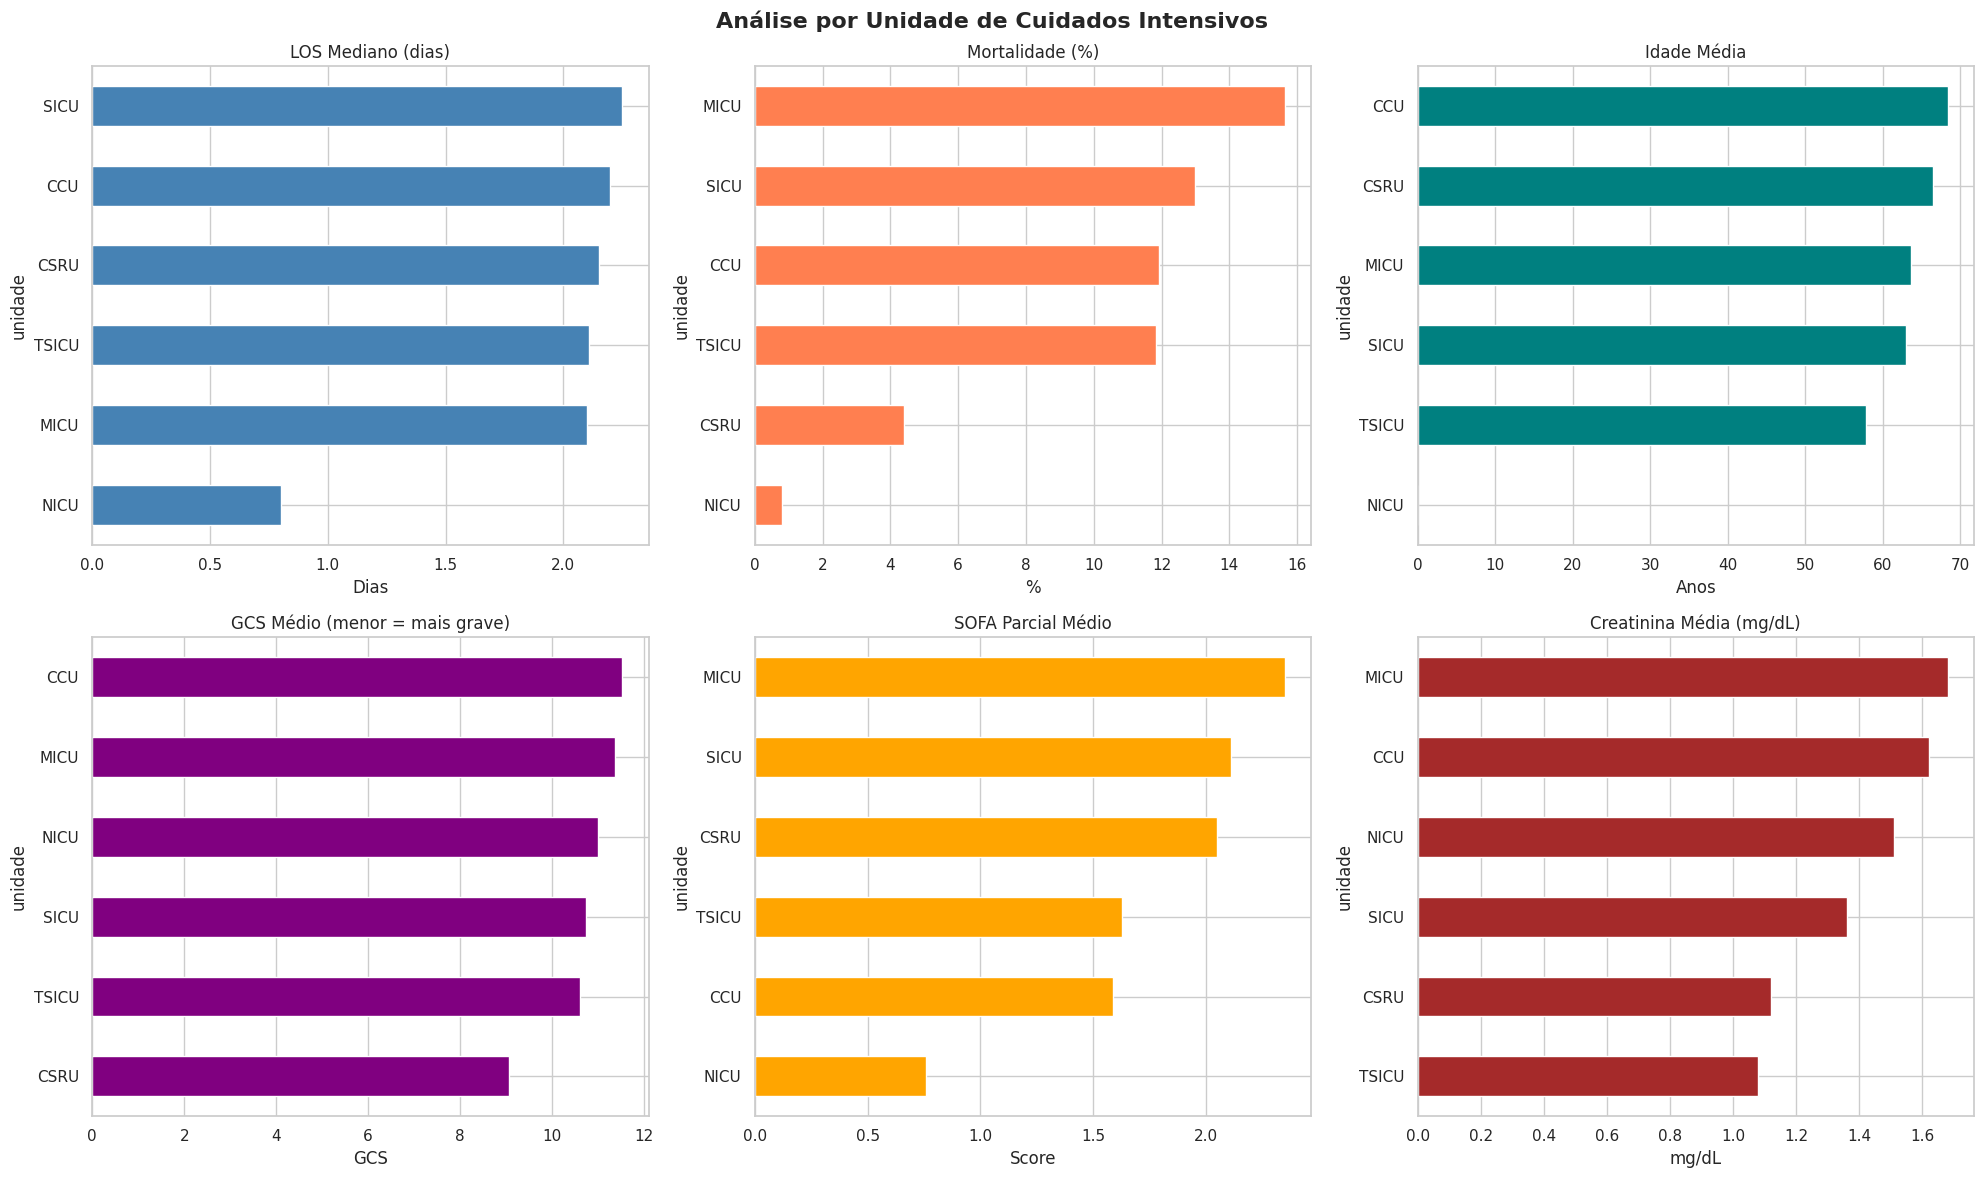

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('Análise por Unidade de Cuidados Intensivos', fontsize=16, fontweight='bold')

# LOS mediano
df_unidades['los_mediano'].sort_values().plot(
    kind='barh', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('LOS Mediano (dias)')
axes[0,0].set_xlabel('Dias')

# Mortalidade
df_unidades['mortalidade_pct'].sort_values().plot(
    kind='barh', ax=axes[0,1], color='coral')
axes[0,1].set_title('Mortalidade (%)')
axes[0,1].set_xlabel('%')

# Idade média
df_unidades['idade_media'].sort_values().plot(
    kind='barh', ax=axes[0,2], color='teal')
axes[0,2].set_title('Idade Média')
axes[0,2].set_xlabel('Anos')

# GCS médio
df_unidades['gcs_medio'].sort_values().plot(
    kind='barh', ax=axes[1,0], color='purple')
axes[1,0].set_title('GCS Médio (menor = mais grave)')
axes[1,0].set_xlabel('GCS')

# SOFA médio
df_unidades['sofa_medio'].sort_values().plot(
    kind='barh', ax=axes[1,1], color='orange')
axes[1,1].set_title('SOFA Parcial Médio')
axes[1,1].set_xlabel('Score')

# Creatinina média
df_unidades['creatinine_media'].sort_values().plot(
    kind='barh', ax=axes[1,2], color='brown')
axes[1,2].set_title('Creatinina Média (mg/dL)')
axes[1,2].set_xlabel('mg/dL')

plt.tight_layout()
plt.show()


**Análise por Unidade**

O painel revela perfis clínicos distintos por unidade que têm implicações directas para o modelo.

SICU e CCU lideram no LOS mediano (~2.2–2.3 dias) e estão entre as unidades com maior mortalidade (~12–13%), idade média elevada (~60–65 anos) e creatinina alta, perfil de doente cirúrgico complexo ou cardíaco grave. MICU destaca-se por ter a **maior mortalidade de todas (~15%)** e o SOFA mais alto, mas LOS mediano semelhante às restantes.

CSRU tem mortalidade baixa (~4.5%) apesar de SOFA e creatinina intermédios, confirma o efeito de protocolo cirúrgico cardíaco com alta precoce e controlada. NICU é o outlier esperado: LOS mediano muito baixo (~0.8 dias), mortalidade mínima, SOFA baixo, dominado por recém-nascidos saudáveis.


### 5.3 BoxPlot LOS por unidade

Enquanto os gráficos de barras mostram a média ou mediana, um **boxplot** oferece uma visão muito mais completa da distribuição do LOS para cada unidade de cuidados.

Isto permite-nos comparar não só o valor central do LOS, mas também a sua variabilidade e a presença de valores extremos em cada tipo de UTI.

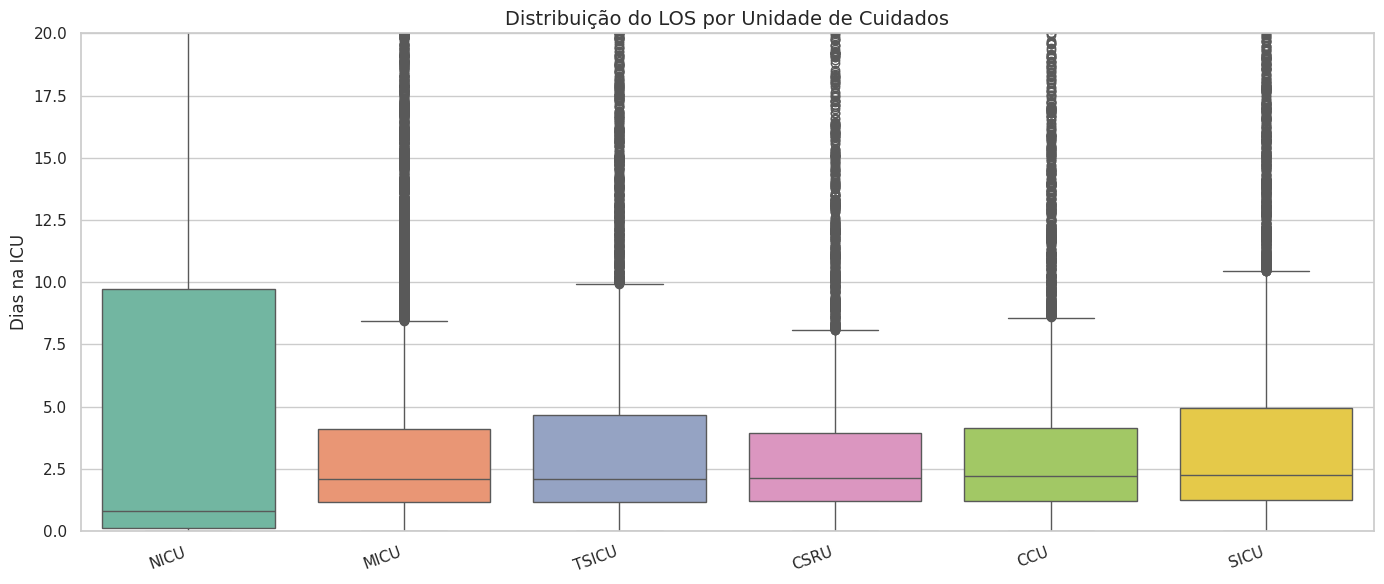

In [ ]:
ordem_los = df_imputado.groupby('FIRST_CAREUNIT')['target_los'].median().sort_values().index

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_imputado,
            x='FIRST_CAREUNIT',
            y='target_los',
            order=ordem_los,
            palette='Set2')
plt.ylim(0, 20)
plt.title('Distribuição do LOS por Unidade de Cuidados', fontsize=14)
plt.xlabel('')
plt.ylabel('Dias na ICU')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()


**Distribuição do LOS por Unidade**

NICU confirma visualmente o que os medianos sugeriam: IQR enorme (0 a ~10 dias), mediana abaixo de 1 dia. A distribuição bimodal implícita, alta muito precoce ou internamento muito longo, torna esta unidade particularmente difícil de modelar com uma abordagem única. 

As restantes unidades (MICU, TSICU, CSRU, CCU, SICU) têm distribuições semelhantes entre si, medianas entre 2 e 2.5 dias, IQR até ~4–5 dias, e caudas longas com outliers até 20 dias. A variabilidade é alta em todas, o que explica a potencial dificuldade geral do modelo. SICU tem o IQR ligeiramente mais largo, consistente com a heterogeneidade de um serviço cirúrgico geral.

Para o modelo de LOS, a unidade de admissão é útil sobretudo para separar NICU das restantes e potencialmente CSRU pelo efeito de protocolo, as diferenças entre MICU, SICU, CCU e TSICU são insuficientes para justificar modelos separados.

### 5.4 Heatmap: Perfil clínico por unidade

Foi feito também um HeatMap, para perceber o perfil clinico de cada unidade.

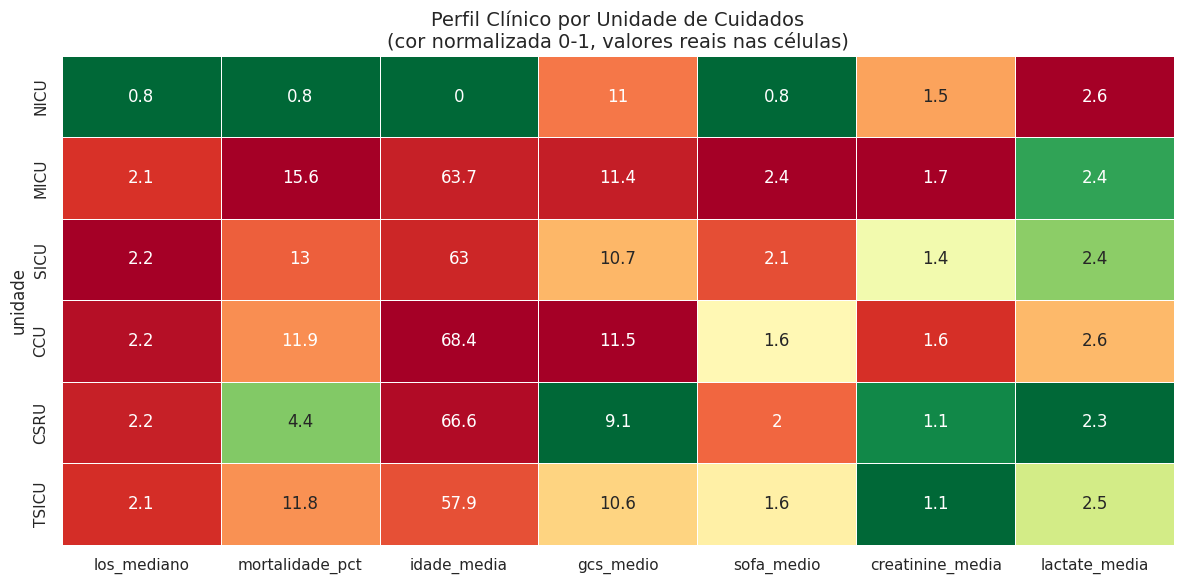

In [ ]:
cols_perfil = ['los_mediano', 'mortalidade_pct', 'idade_media',
               'gcs_medio', 'sofa_medio', 'creatinine_media', 'lactate_media']

df_perfil = df_unidades[cols_perfil].copy()
scaler = MinMaxScaler()
df_perfil_norm = pd.DataFrame(
    scaler.fit_transform(df_perfil),
    index=df_perfil.index,
    columns=cols_perfil
)

plt.figure(figsize=(12, 6))
sns.heatmap(df_perfil_norm,
            annot=df_perfil.round(1),
            fmt='g',
            cmap='RdYlGn_r',
            linewidths=0.5,
            cbar=False)
plt.title('Perfil Clínico por Unidade de Cuidados\n(cor normalizada 0-1, valores reais nas células)', fontsize=14)
plt.tight_layout()
plt.show()

De todos estes gráficos algumas conclusões podem ser tiradas, como por exemplo o facto de que o NICU, dado os valores da idade méida de 0, LOS baixo, e um SOFA também baixo, deve ser uma unidade de cuidados de recém nascidos, tornando-se uma infromação importante para melhor prever o LOS destes pacientes, uma vez que os mesmos não devem ser casos graves mas sim, pequenos períodos de tempo pós parto para observação dos bébés.

## 6. Impacto da hora/dia de admissão

### 6.1 Preparação das features temporais

Nesta secção, investigamos se o momento da admissão na UTI a hora do dia, o dia da semana, ou o turno tem alguma correlação com o tempo de internação (LOS) e a mortalidade. Esta análise é frequentemente referida como "efeito do fim de semana" ou "efeito da noite".

Para isso, primeiro preparamos novamente as nossas features temporais a partir da coluna `ADMITTIME`, garantindo que temos as variáveis `hora_admissao`, `dia_semana`, `fim_de_semana`, `mes` e `turno` prontas para a análise.

In [ ]:
df_tempo = df_imputado.copy()
df_tempo['ADMITTIME'] = pd.to_datetime(df_tempo['ADMITTIME'], utc=True)
df_tempo['hora_admissao'] = df_tempo['ADMITTIME'].dt.hour
df_tempo['dia_semana']    = df_tempo['ADMITTIME'].dt.dayofweek
df_tempo['fim_de_semana'] = df_tempo['dia_semana'].isin([5, 6])
df_tempo['mes']           = df_tempo['ADMITTIME'].dt.month
df_tempo['turno'] = pd.cut(
    df_tempo['hora_admissao'],
    bins=[-1, 7, 15, 22, 24],
    labels=['Madrugada (0-7h)', 'Manhã (8-15h)', 'Tarde (16-22h)', 'Noite (23h+)']
)

### 6.2 LOS e mortalidade por hora de admissão

Para visualizar o impacto do momento da admissão, criamos um painel com quatro gráficos:

1.  **LOS por Hora:** Um gráfico de linha que mostra como o LOS mediano varia ao longo das 24 horas do dia. Uma área sombreada destaca o período da madrugada.
2.  **Mortalidade por Hora:** Semelhante ao anterior, mas mostrando a variação da taxa de mortalidade.
3.  **LOS por Dia da Semana:** Um gráfico de barras que compara o LOS mediano para cada dia da semana, destacando o fim de semana em vermelho.
4.  **Mortalidade por Dia da Semana:** O mesmo que o anterior, mas para a taxa de mortalidade.

Estes gráficos permitem-nos identificar visualmente quaisquer padrões ou tendências, como picos de LOS ou mortalidade em horários ou dias específicos.

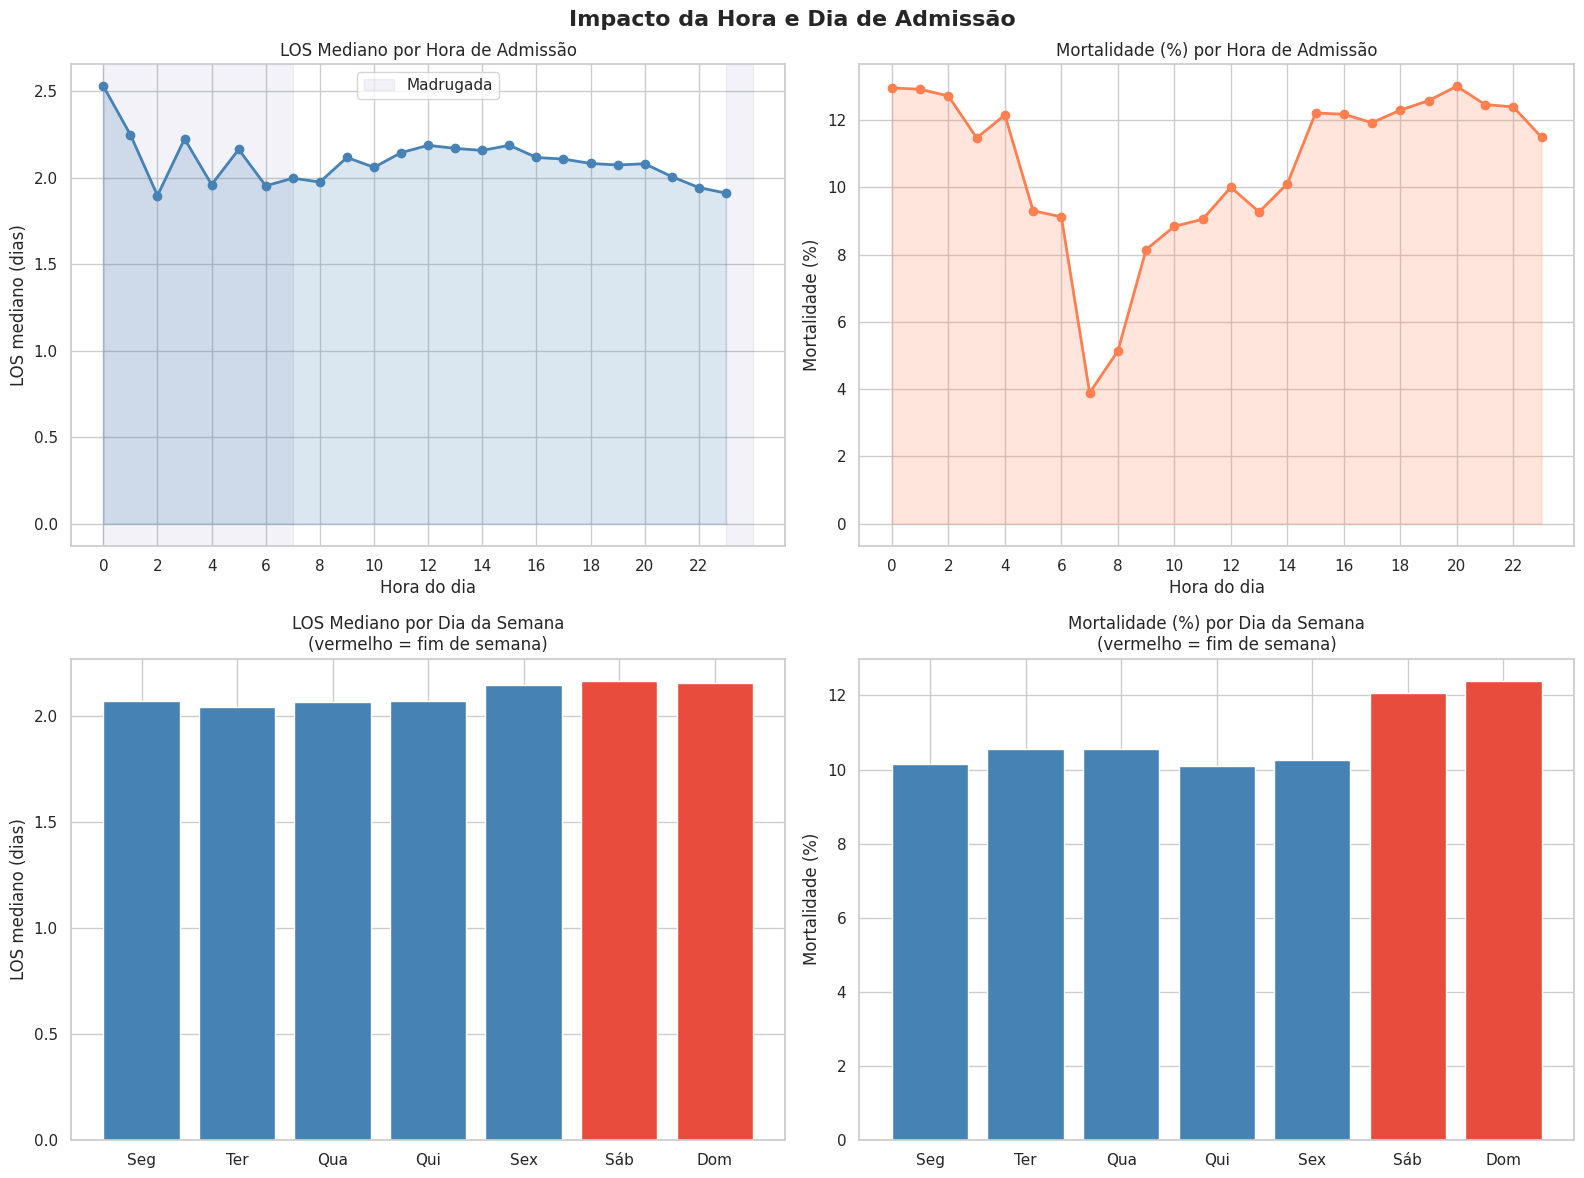

In [ ]:
hora_stats = df_tempo.groupby('hora_admissao').agg(
    los_mediano    = ('target_los', 'median'),
    mortalidade    = ('HOSPITAL_EXPIRE_FLAG', 'mean'),
    n_admissoes    = ('ICUSTAY_ID', 'count')
).reset_index()
hora_stats['mortalidade_pct'] = hora_stats['mortalidade'] * 100

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Impacto da Hora e Dia de Admissão', fontsize=16, fontweight='bold')

# LOS por hora
axes[0,0].plot(hora_stats['hora_admissao'], hora_stats['los_mediano'],
               'o-', color='steelblue', linewidth=2, markersize=6)
axes[0,0].fill_between(hora_stats['hora_admissao'], hora_stats['los_mediano'],
                        alpha=0.2, color='steelblue')
axes[0,0].set_title('LOS Mediano por Hora de Admissão')
axes[0,0].set_xlabel('Hora do dia')
axes[0,0].set_ylabel('LOS mediano (dias)')
axes[0,0].set_xticks(range(0, 24, 2))
axes[0,0].axvspan(0, 7, alpha=0.05, color='navy', label='Madrugada')
axes[0,0].axvspan(23, 24, alpha=0.05, color='navy')
axes[0,0].legend()

# Mortalidade por hora
axes[0,1].plot(hora_stats['hora_admissao'], hora_stats['mortalidade_pct'],
               'o-', color='coral', linewidth=2, markersize=6)
axes[0,1].fill_between(hora_stats['hora_admissao'], hora_stats['mortalidade_pct'],
                        alpha=0.2, color='coral')
axes[0,1].set_title('Mortalidade (%) por Hora de Admissão')
axes[0,1].set_xlabel('Hora do dia')
axes[0,1].set_ylabel('Mortalidade (%)')
axes[0,1].set_xticks(range(0, 24, 2))

# LOS por dia da semana
dias_label = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
dia_los = df_tempo.groupby('dia_semana')['target_los'].median()
cores_dias = ['#e74c3c' if i >= 5 else 'steelblue' for i in range(7)]
axes[1,0].bar(dias_label, dia_los.values, color=cores_dias)
axes[1,0].set_title('LOS Mediano por Dia da Semana\n(vermelho = fim de semana)')
axes[1,0].set_ylabel('LOS mediano (dias)')

# Mortalidade por dia da semana
dia_mort = df_tempo.groupby('dia_semana')['HOSPITAL_EXPIRE_FLAG'].mean() * 100
axes[1,1].bar(dias_label, dia_mort.values, color=cores_dias)
axes[1,1].set_title('Mortalidade (%) por Dia da Semana\n(vermelho = fim de semana)')
axes[1,1].set_ylabel('Mortalidade (%)')

plt.tight_layout()
plt.show()

**Hora de admissão**

Admissões na madrugada (0h–1h) têm LOS mediano mais alto (~2.5 dias) e mortalidade mais alta (~13%). O LOS desce progressivamente até estabilizar entre as 6h e as 22h (~2.0–2.2 dias). A mortalidade tem um padrão mais abrupto: cai até um mínimo notável às ~7h (~4%) e sobe de novo a partir daí. Este padrão da manhã provavelmente reflecte admissões electivas ou pós-cirurgia programada, doentes de menor gravidade admitidos no início do dia útil. As admissões nocturnas são maioritariamente urgências, o que explica simultaneamente o LOS mais longo e a mortalidade mais elevada.

---

**Dia da semana**

O efeito no LOS é mínimo a diferença entre semana (~2.05 dias) e fim de semana (~2.15 dias) é marginal mas estatisticamente significativa. Na mortalidade o sinal é mais claro: sábado e domingo têm ~12%, consistentemente acima dos dias de semana (~10–10.5%). O efeito fim-de-semana na mortalidade hospitalar é bem documentado na literatura e atribuído a menor disponibilidade de recursos diagnósticos e terapêuticos, menos pessoal sénior e atrasos em procedimentos electivos urgentes.


### 6.3 Fim de semana vs Semana

As observações visuais precisam de ser confirmadas com rigor estatístico. Para comparar as admissões durante a semana com as do fim de semana, usamos o **Teste de Mann-Whitney U**.

Este é um teste não paramétrico (não assume uma distribuição normal dos dados), o que o torna ideal para o nosso LOS, que tem uma distribuição assimétrica. O teste diz-nos se é provável que duas amostras independentes (neste caso, LOS da semana e LOS do fim de semana) venham da mesma população.

Calculamos o **p-value**:
*   Se `p < 0.05`, rejeitamos a hipótese nula e concluímos que existe uma **diferença estatisticamente significativa** entre os grupos.
*   Se `p >= 0.05`, não temos evidências suficientes para afirmar que há uma diferença.

Fazemos este teste tanto para o LOS como para a mortalidade.

In [ ]:
semana  = df_tempo[df_tempo['fim_de_semana'] == False]['target_los']
fds     = df_tempo[df_tempo['fim_de_semana'] == True]['target_los']

stat, p_los = stats.mannwhitneyu(semana, fds, alternative='two-sided')

mort_semana = df_tempo[df_tempo['fim_de_semana'] == False]['HOSPITAL_EXPIRE_FLAG']
mort_fds    = df_tempo[df_tempo['fim_de_semana'] == True]['HOSPITAL_EXPIRE_FLAG']
stat2, p_mort = stats.mannwhitneyu(mort_semana, mort_fds, alternative='two-sided')

print("--- Teste Mann-Whitney U: Semana vs Fim de Semana ---")
print(f"LOS      — p-value: {p_los:.4f}  {'✓ diferença significativa' if p_los < 0.05 else '✗ sem diferença significativa'}")
print(f"Mortalidade — p-value: {p_mort:.4f}  {'✓ diferença significativa' if p_mort < 0.05 else '✗ sem diferença significativa'}")
print(f"\nLOS mediano semana  : {semana.median():.2f} dias")
print(f"LOS mediano fim sem.: {fds.median():.2f} dias")
print(f"Mortalidade semana  : {mort_semana.mean()*100:.1f}%")
print(f"Mortalidade fim sem.: {mort_fds.mean()*100:.1f}%")

--- Teste Mann-Whitney U: Semana vs Fim de Semana ---
LOS      — p-value: 0.0093  ✓ diferença significativa
Mortalidade — p-value: 0.0000  ✓ diferença significativa

LOS mediano semana  : 2.08 dias
LOS mediano fim sem.: 2.16 dias
Mortalidade semana  : 10.3%
Mortalidade fim sem.: 12.2%


Comprovamos assim que pacientes que tenham entrada ao fim de semana têm maior chance de ter maior LOS, e maior mortalidade.

### 6.4 Turno de admissão

Para comparar o LOS entre os múltiplos grupos de turnos (manhã, tarde, noite, madrugada), usamos o **Teste de Kruskal-Wallis**.

Este é a extensão não paramétrica do teste ANOVA e permite-nos verificar se existem diferenças estatisticamente significativas entre duas ou mais amostras independentes.

*   Se o **p-value for menor que 0.05**, podemos concluir que pelo menos um dos turnos tem uma distribuição de LOS significativamente diferente dos outros.

Após o teste, apresentamos uma tabela com as estatísticas de LOS mediano e mortalidade para cada turno, para entender a natureza das diferenças encontradas.

In [ ]:
grupos_turno = [grupo['target_los'].values
                for _, grupo in df_tempo.groupby('turno', observed=True)]

stat_kw, p_kw = stats.kruskal(*grupos_turno)
print(f"\n--- Teste Kruskal-Wallis: LOS por Turno ---")
print(f"p-value: {p_kw:.4f}  {'✓ diferença significativa entre turnos' if p_kw < 0.05 else '✗ sem diferença significativa'}")

turno_stats = df_tempo.groupby('turno', observed=True).agg(
    los_mediano    = ('target_los', 'median'),
    mortalidade_pct = ('HOSPITAL_EXPIRE_FLAG', lambda x: x.mean() * 100),
    n              = ('ICUSTAY_ID', 'count')
).round(2)
print(turno_stats.to_string())



--- Teste Kruskal-Wallis: LOS por Turno ---
p-value: 0.0006  ✓ diferença significativa entre turnos
                  los_mediano  mortalidade_pct      n
turno                                                
Madrugada (0-7h)         2.06             9.45  14888
Manhã (8-15h)            2.14             9.42  18613
Tarde (16-22h)           2.07            12.40  25210
Noite (23h+)             1.91            11.49   2811


### 6.5 Boxplot Turno vs LOS

Finalmente, visualizamos as diferenças entre os turnos usando um boxplot para o LOS e um gráfico de barras para a mortalidade.

O boxplot permite-nos ver a distribuição completa do LOS para cada turno, complementando o resultado do teste de Kruskal-Wallis. O gráfico de barras mostra a variação da taxa de mortalidade, permitindo uma comparação direta da gravidade ou do risco associado a cada turno de admissão.

Juntos, estes gráficos fornecem uma imagem clara de como o momento da admissão se relaciona com os desfechos dos pacientes.

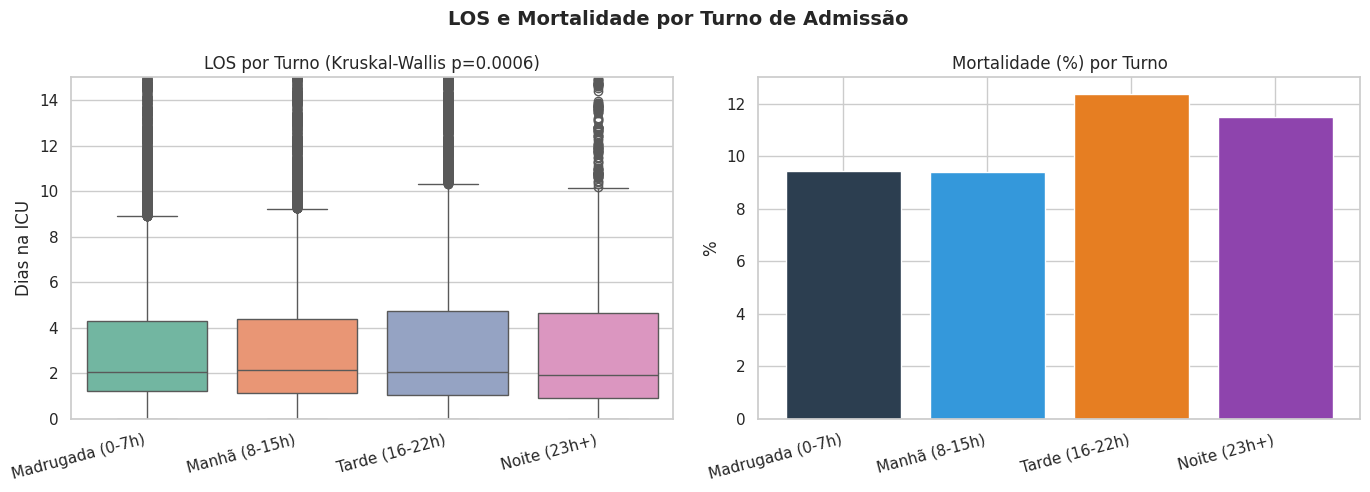

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('LOS e Mortalidade por Turno de Admissão', fontsize=14, fontweight='bold')

sns.boxplot(data=df_tempo, x='turno', y='target_los',
            palette='Set2', ax=axes[0], order=[
                'Madrugada (0-7h)', 'Manhã (8-15h)',
                'Tarde (16-22h)', 'Noite (23h+)'])
axes[0].set_ylim(0, 15)
axes[0].set_title(f'LOS por Turno (Kruskal-Wallis p={p_kw:.4f})')
axes[0].set_xlabel('')
axes[0].set_ylabel('Dias na ICU')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15, ha='right')

turno_mort = df_tempo.groupby('turno', observed=True)['HOSPITAL_EXPIRE_FLAG'].mean() * 100
turno_mort = turno_mort.reindex(['Madrugada (0-7h)', 'Manhã (8-15h)',
                                  'Tarde (16-22h)', 'Noite (23h+)'])
axes[1].bar(turno_mort.index, turno_mort.values,
            color=['#2c3e50', '#3498db', '#e67e22', '#8e44ad'])
axes[1].set_title('Mortalidade (%) por Turno')
axes[1].set_ylabel('%')
axes[1].set_xticklabels(turno_mort.index, rotation=15, ha='right')

plt.tight_layout()
plt.show()

À semelhança do fim de semana é possível afirmar que pacientes adimitidos à tarde e noite, possívelmente por corresponderem a casos mais graves, têm maior LOS e Mortalidade

## 7. Clustering

### 7.1 Seleção de features

O nosso objetivo aqui é identificar se existem "fenótipos" ou perfis de pacientes distintos com base nos seus dados clínicos das primeiras 24 horas. Para isto, selecionamos um conjunto de features que representam genuinamente o estado clínico do paciente: sinais vitais, resultados laboratoriais e scores de gravidade. É crucial que estas features sejam numéricas e não contenham o alvo (LOS) ou outras informações que não descrevam diretamente o estado do paciente.

No entanto, enfrentamos um desafio técnico importante: o K-Means é altamente sensível à escala das features. Se uma feature for medida em unidades grandes (ex: creatinina em mg/dL) e outra em unidades pequenas (ex: potássio em mEq/L), o algoritmo será dominado pela variável de maior magnitude, ignorando a variável de menor escala. Por isso, o passo seguinte é fundamental: a **normalização com `StandardScaler`**. Este processo transforma todas as features para que tenham uma média de 0 e um desvio padrão de 1, garantindo que todas as features contribuem de forma igual para o cálculo da distância entre os pacientes.

Adicionalmente, removemos features redundantes. Calculamos a matriz de correlação e identificamos pares de features com correlação superior a 0.9, o que indica que são essencialmente duplicadas e não trazem informação independente. Mantemos apenas a feature do par que tem maior correlação com o alvo LOS, preservando assim o poder preditivo enquanto reduzimos a redundância.

In [ ]:
# Todas as features numéricas disponíveis (excluir targets e IDs)
cols_excluir_cluster = [
    'ICUSTAY_ID', 'SUBJECT_ID', 'HADM_ID',
    'target_los', 'los_class', 'los_class_label',
    'HOSPITAL_EXPIRE_FLAG',  # target proxy, não deve influenciar clusters
    'total_chart_events', 'total_lab_events',  # contagens administrativas
    'admission_number', 'total_icu_stays_patient'
]

cols_candidatas = [c for c in df_imputado.columns
                   if c not in cols_excluir_cluster
                   and df_imputado[c].dtype in ['float64', 'int64', 'uint8']
                   and df_imputado[c].nunique() > 1]

print(f"Features candidatas iniciais: {len(cols_candidatas)}")

# Remover features com correlação > 0.9 (redundantes)
corr_matrix = df_imputado[cols_candidatas].corr().abs()
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Para cada par com corr > 0.9, remove a que tem menor correlação com target_los
cols_remover = set()
for col in upper_triangle.columns:
    pares_altos = upper_triangle.index[upper_triangle[col] > 0.9].tolist()
    for par in pares_altos:
        # Manter a que tem maior correlação com LOS
        corr_col = abs(df_imputado[col].corr(df_imputado['target_los']))
        corr_par = abs(df_imputado[par].corr(df_imputado['target_los']))
        if corr_col >= corr_par:
            cols_remover.add(par)
        else:
            cols_remover.add(col)

cols_cluster = [c for c in cols_candidatas if c not in cols_remover]

print(f"Features removidas por alta correlação (>0.9): {len(cols_remover)}")
print(f"Removidas: {sorted(cols_remover)}")
print(f"\nFeatures finais para clustering: {len(cols_cluster)}")
print(cols_cluster)

X = df_imputado[cols_cluster].copy()

Features candidatas iniciais: 154
Features removidas por alta correlação (>0.9): 76
Removidas: ['abp_cv_missing', 'abp_std_missing', 'abp_systolic_mean_missing', 'abp_systolic_min_missing', 'abp_trend_missing', 'anion_gap_mean_missing', 'bicarbonate_mean_missing', 'bilirubin_max', 'bilirubin_mean_missing', 'creatinine_max_missing', 'creatinine_mean', 'creatinine_mean_missing', 'fio2_mean_missing', 'gcs_eye_min_missing', 'gcs_motor_min_missing', 'gcs_total_min', 'gcs_total_min_missing', 'gcs_verbal_min', 'gcs_verbal_min_missing', 'glucose_max_missing', 'glucose_mean_missing', 'hematocrit_mean_missing', 'hemoglobin_mean', 'hemoglobin_mean_missing', 'hemoglobin_min', 'hemoglobin_min_missing', 'hr_cv_missing', 'hr_first_missing', 'hr_last_missing', 'hr_max_missing', 'hr_mean_missing', 'hr_min_missing', 'hr_range_missing', 'hr_std', 'hr_std_missing', 'hr_trend_missing', 'lactate_mean', 'lactate_mean_missing', 'nibp_mean_missing', 'nibp_std_missing', 'nibp_systolic_cv_missing', 'nibp_systoli

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"Shape matrix clustering: {X_scaled.shape}")

Shape matrix clustering: (61522, 78)


### 7.2 Método do Cotovelo + Silhouette

Um dos maiores desafios do K-Means é escolher o número ideal de clusters (K). Para nos ajudar nesta decisão, usamos várias métricas, que são calculadas para diferentes valores de K (de 2 a 10):

1.  **Método do Cotovelo (Inércia):** A inércia é a soma das distâncias quadradas de cada ponto ao centro do seu cluster. Procuramos o "cotovelo" no gráfico, o ponto onde a diminuição da inércia começa a abrandar.
2.  **Silhouette Score:** Mede quão semelhante um objeto é ao seu próprio cluster em comparação com outros clusters. Varia de -1 a 1, onde um valor alto indica que o objeto está bem combinado com o seu próprio cluster e mal combinado com os clusters vizinhos. **Quanto maior, melhor.**
3.  **Calinski-Harabasz Score:** Também conhecido como critério da razão de variância. É a razão entre a dispersão entre clusters e a dispersão intra-cluster. **Quanto maior, melhor.**
4.  **Davies-Bouldin Score:** Mede a semelhança média entre cada cluster e o seu cluster mais semelhante. **Quanto menor, melhor.**

Analisando estes quatro gráficos em conjunto, podemos tomar uma decisão mais informada sobre o valor de K que melhor representa a estrutura dos nossos dados. Neste caso, K=9 parece ser um bom candidato.


A testar K de 2 a 10 (paralelo)...

A executar: Clustering — Testar K=2-10 (joblib loky)...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done   9 out of   9 | elapsed:  1.6min finished


Clustering — Testar K=2-10 (joblib loky) concluída!
Tempo: 93.81s | Pico RAM: 16.09 MB

--- Métricas por K ---
    k      inertia  silhouette  calinski_harabasz  davies_bouldin
0   2  4458249.970       0.181           4698.137           3.057
1   3  4207962.286       0.112           4318.311           2.664
2   4  4051399.357       0.124           3782.515           2.812
3   5  3947641.639       0.135           3315.622           2.707
4   6  3849150.180       0.135           3035.139           2.256
5   7  3754665.476       0.135           2850.887           2.112
6   8  3705140.670       0.106           2593.758           2.294
7   9  3642804.334       0.122           2439.865           1.923
8  10  3576050.714       0.126           2336.799           2.145


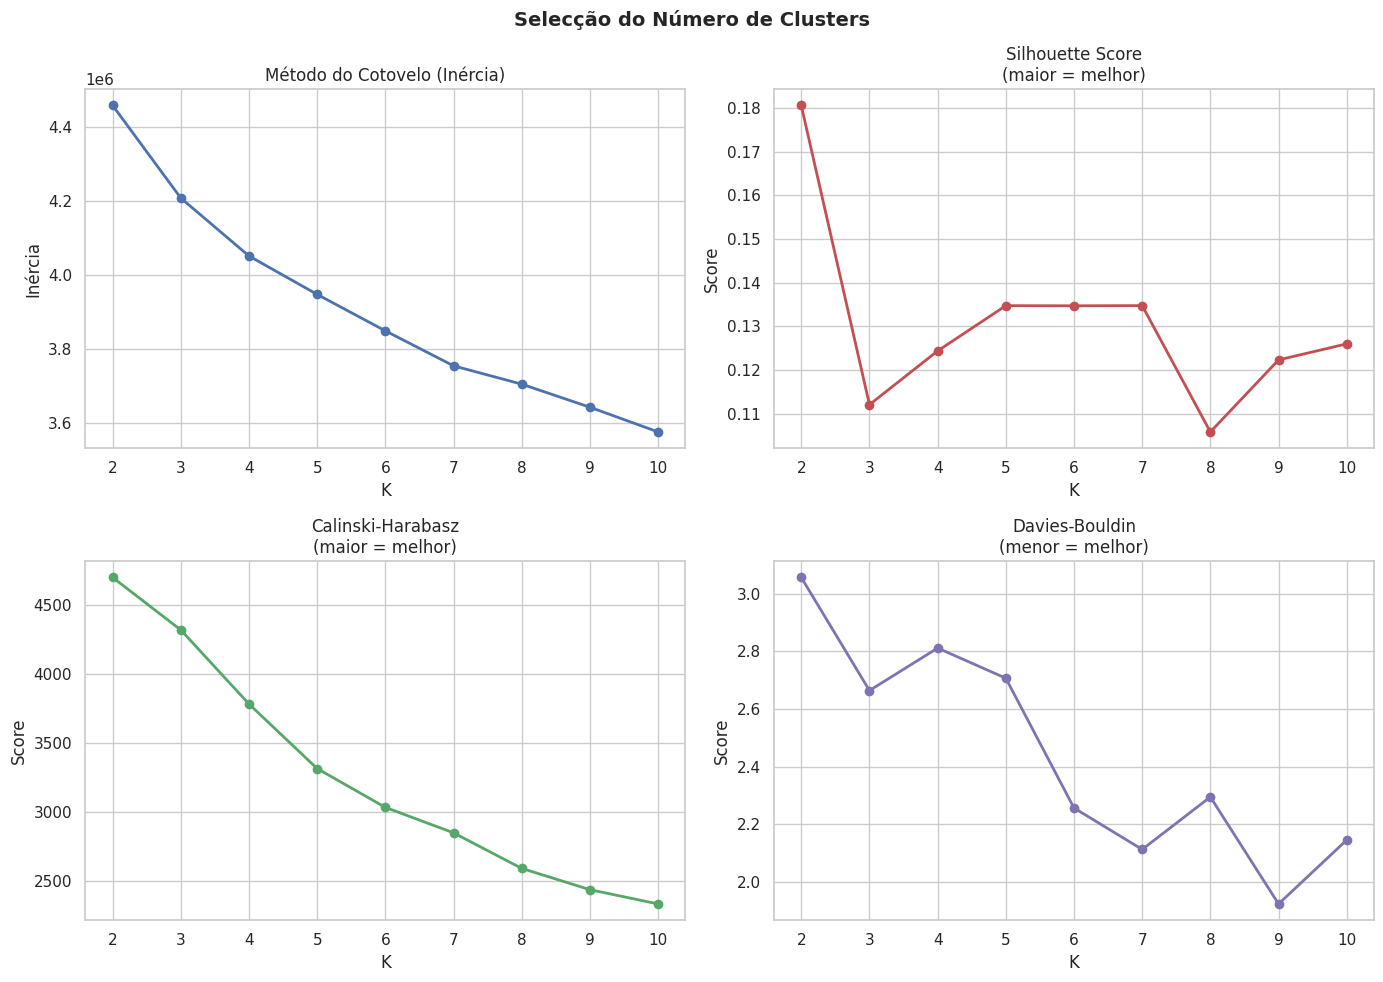

In [ ]:
def testar_k(k, X):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    return {
        'k'                : k,
        'inertia'          : km.inertia_,
        'silhouette'       : silhouette_score(X, labels, sample_size=5000, random_state=42),
        'calinski_harabasz': calinski_harabasz_score(X, labels),
        'davies_bouldin'   : davies_bouldin_score(X, labels)
    }

print("\nA testar K de 2 a 10 (paralelo)...")

with profile("Clustering — Testar K=2-10 (joblib loky)"):
    resultados_k = Parallel(n_jobs=-1, backend='loky', verbose=1)(
        delayed(testar_k)(k, X_scaled) for k in range(2, 11)
    )


df_k = pd.DataFrame(resultados_k)
print("\n--- Métricas por K ---")
print(df_k.round(3).to_string())

# Visualização das métricas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Selecção do Número de Clusters', fontsize=14, fontweight='bold')

axes[0,0].plot(df_k['k'], df_k['inertia'], 'bo-', linewidth=2)
axes[0,0].set_title('Método do Cotovelo (Inércia)')
axes[0,0].set_xlabel('K')
axes[0,0].set_ylabel('Inércia')
axes[0,0].set_xticks(range(2, 11))

axes[0,1].plot(df_k['k'], df_k['silhouette'], 'ro-', linewidth=2)
axes[0,1].set_title('Silhouette Score\n(maior = melhor)')
axes[0,1].set_xlabel('K')
axes[0,1].set_ylabel('Score')
axes[0,1].set_xticks(range(2, 11))

axes[1,0].plot(df_k['k'], df_k['calinski_harabasz'], 'go-', linewidth=2)
axes[1,0].set_title('Calinski-Harabasz\n(maior = melhor)')
axes[1,0].set_xlabel('K')
axes[1,0].set_ylabel('Score')
axes[1,0].set_xticks(range(2, 11))

axes[1,1].plot(df_k['k'], df_k['davies_bouldin'], 'mo-', linewidth=2)
axes[1,1].set_title('Davies-Bouldin\n(menor = melhor)')
axes[1,1].set_xlabel('K')
axes[1,1].set_ylabel('Score')
axes[1,1].set_xticks(range(2, 11))

plt.tight_layout()
plt.show()

**Método do Cotovelo (Inércia):** A curva desce consistentemente sem um cotovelo claramente definido. A descida começa a suavizar a partir de K=5, sugerindo que adicionar mais clusters além deste ponto traz diminuição de retorno.

**Silhouette Score:** K=2 é o máximo absoluto (0.18), mas cai abruptamente para K=3. A partir de K=5 estabiliza num patamar de ~0.135 que se mantém até K=7. K=5 é o primeiro valor deste patamar estável.

**Calinski-Harabasz:** Aponta para K=2 como o melhor, decrescendo consistentemente. Não é determinante para a escolha final pois K=2 é clinicamente insuficiente.

**Davies-Bouldin:** Os melhores valores estão em K=9 (1.923) e K=7 (2.112). No entanto, valores elevados de K com este dataset produziram clusters com número reudzido de pacientes.

---

**Porquê K=5 e não K=2 (o melhor pelas métricas)?**

K=2 é matematicamente o melhor pelo Silhouette e Calinski-Harabasz mas clinicamente inútil, divide apenas em "grave" e "não grave", sem granularidade suficiente para ser accionável. A literatura de stratificação de risco em UCI tipicamente utiliza entre 3 e 5 grupos de gravidade.



### 7.3 Clustering Final

Com o número de clusters (K = 5) decidido com base na análise multi-métrica anterior, executamos o algoritmo K-Means final nos nossos dados normalizados.

O método `fit_predict` realiza duas operações essenciais: (1) **`fit`** encontra as coordenadas dos K centroides que melhor representam a nuvem de dados, posicionando cada centroide de forma a minimizar a variância dentro dos clusters; (2) **`predict`** atribui a cada paciente (linha do nosso dataset) o rótulo do cluster cujo centroide está mais próximo na métrica de distância euclidiana.

O resultado é uma nova coluna no nosso dataframe, `cluster`, que contém o rótulo do cluster (de 0 a K-1) para cada estadia na UTI. O primeiro passo após o ajuste é verificar a **distribuição dos clusters**, quantos pacientes caíram em cada um deles. Uma distribuição muito desigual (ex: 80% num único cluster) poderia sugerir que K não foi uma boa escolha, ou que a estrutura dos dados é naturalmente desigual. Uma distribuição mais equilibrada típicamente indica uma estrutura de clusters mais robusta e interpretável.

In [ ]:
km_final = KMeans(n_clusters=5, random_state=42, n_init=10)
df_imputado['cluster'] = km_final.fit_predict(X_scaled)

print("\nDistribuição dos clusters:")
print(df_imputado['cluster'].value_counts().sort_index().to_string())


Distribuição dos clusters:
cluster
0     6942
1     6774
2    29705
3     9446
4     8655


### 7.4 Visualização PCA 2D

As nossas features de clustering vivem num espaço de alta dimensionalidade, mais de 20 dimensões. Para visualizar os clusters de forma compreensível, precisamos de reduzir esta complexidade para duas dimensões.

Utilizamos a **Análise de Componentes Principais (PCA)**, uma técnica que encontra as direções de maior variação nos dados (os componentes principais) e projeta os dados nessas direções. O primeiro componente principal (PC1) aponta para a direção onde os dados têm a maior variância; o segundo (PC2) aponta para a direção de segunda maior variância, ortogonal ao primeiro.

Ao projetar os dados nos dois primeiros componentes principais, podemos criar um gráfico de dispersão onde cada ponto é um paciente, a cor representa o cluster ao qual pertence, e a posição (x, y) codifica a sua projeção 2D. O gráfico mostra-nos quão bem separados estão os clusters neste espaço reduzido. É importante salientar que a separação pode não ser perfeita, porque estamos a comprimir muita informação, mas oferece uma visão valiosa da estrutura geral. A **variância explicada** (a percentagem da informação original capturada pelos dois componentes) diz-nos quanto de contexto perdemos na redução. Uma variância explicada alta (ex: 50%) é excelente; valores mais baixos (ex: 15%) sugerem que os clusters têm uma estrutura complexa que não pode ser totalmente representada em 2D.


Variância explicada pelo PCA:
  PC1: 9.3%
  PC2: 5.4%
  Total: 14.7%


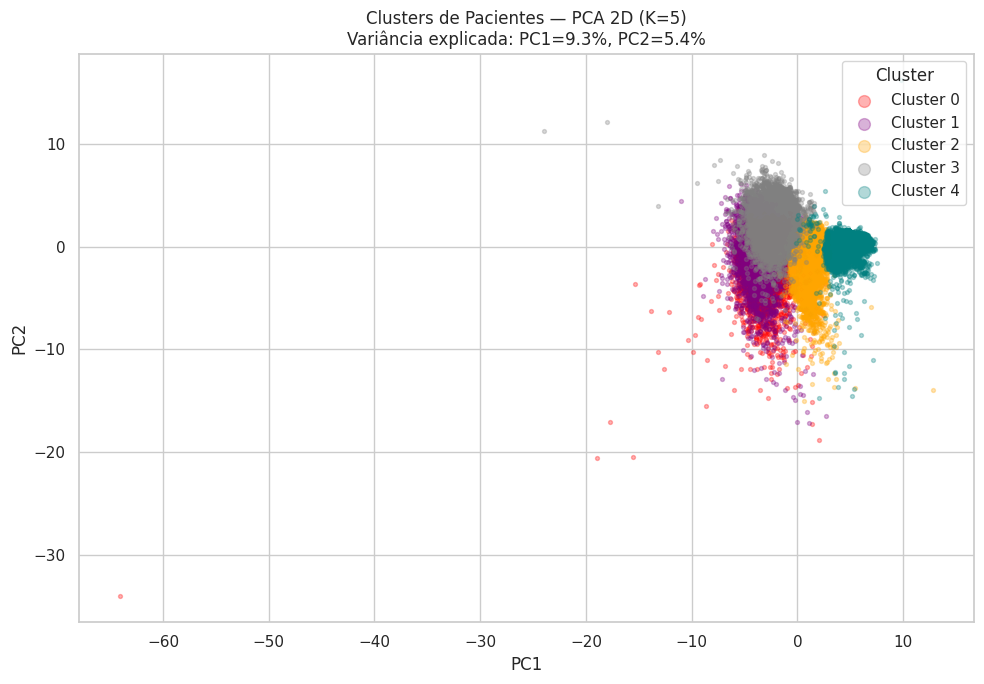

In [ ]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_exp = pca.explained_variance_ratio_
print(f"\nVariância explicada pelo PCA:")
print(f"  PC1: {var_exp[0]*100:.1f}%")
print(f"  PC2: {var_exp[1]*100:.1f}%")
print(f"  Total: {sum(var_exp)*100:.1f}%")

fig, ax = plt.subplots(figsize=(10, 7))

cores_discretas = ['red', 'purple', 'orange', 'gray', 'teal']
for cluster_id in range(5):
    mask = df_imputado['cluster'] == cluster_id
    ax.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        c=cores_discretas[cluster_id],
        label=f'Cluster {cluster_id}',
        alpha=0.3,
        s=8
    )

ax.legend(title='Cluster', markerscale=3, loc='upper right')
ax.set_title(f'Clusters de Pacientes — PCA 2D (K=5)\n'
             f'Variância explicada: PC1={var_exp[0]*100:.1f}%, PC2={var_exp[1]*100:.1f}%')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

### 7.5 Perfil Clínico dos Clusters

A etapa final e mais importante do clustering é **interpretar os clusters**. Um cluster só é útil se conseguirmos entender o que ele representa clinicamente, não é suficiente ser apenas uma construção matemática, precisa ter significado médico.

Para isto, agrupamos os dados por `cluster` e calculamos a média de todas as features clínicas para cada um. Isto dá-nos o "perfil médio" de um paciente em cada cluster, como se fosse um paciente típico ou representativo de cada grupo. Para facilitar a interpretação, criamos um **heatmap** que mostra estes perfis lado-a-lado. As cores são normalizadas para destacar as diferenças relativas entre os clusters (ex: qual cluster tem a maior creatinine_mean?), enquanto os valores numéricos reais são anotados nas células. Esta dupla representação permite tanto uma compreensão visual rápida quanto a validação de detalhes numéricos.

Finalmente, analisamos a relação entre os clusters e os nossos alvos de interesse: o **LOS** e a **mortalidade**. Calculamos o LOS mediano e a taxa de mortalidade para cada cluster. Isto permite-nos identificar rapidamente "clusters de alto risco", perfis de pacientes que estão associados a estadias mais longas e maior probabilidade de morte. Clinicamente, estes clusters revelam fenótipos de pacientes que requerem atenção prioritária ou estratégias de intervenção específicas. Um cluster pode, por exemplo, ser caracterizado por idade avançada + disfunção renal (alta creatinina) + baixa saturação de oxigénio, com mortalidade 3x superior aos outros, isto é informação clinicamente valiosa para guiar a prática.

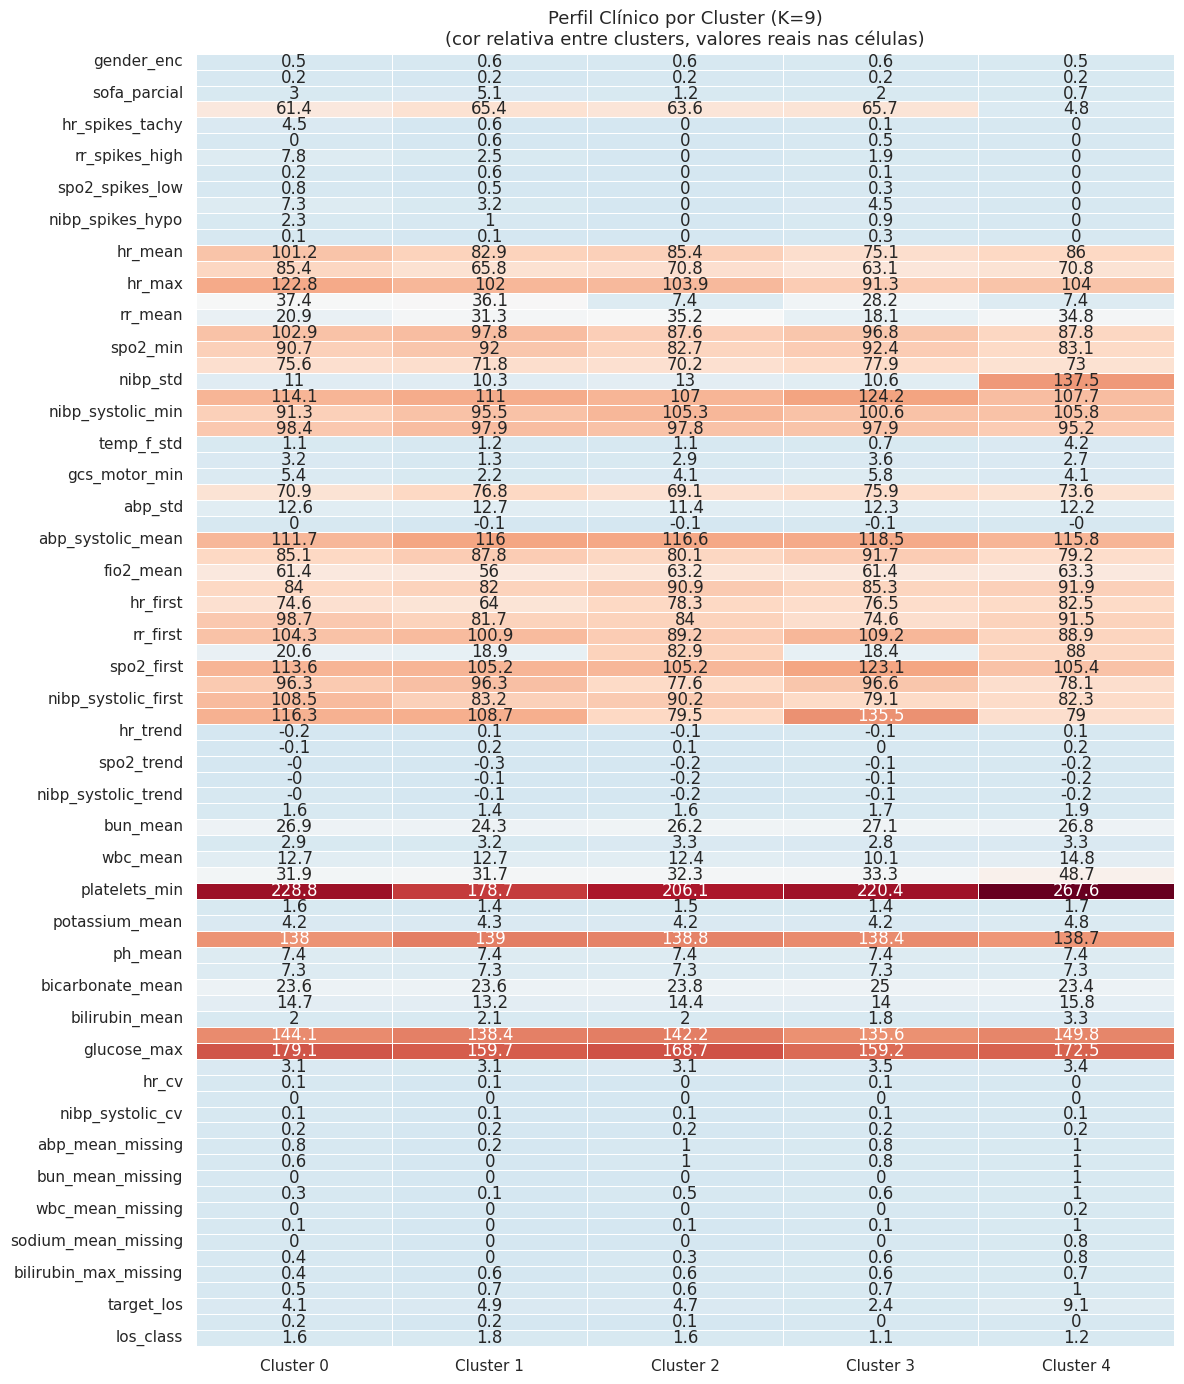


--- LOS e Mortalidade por Cluster ---
         n_pacientes  los_mediano  los_media  mortalidade_pct
cluster                                                      
0               6942         2.30       4.06            14.62
1               6774         2.74       4.91            16.37
2              29705         2.31       4.71            13.16
3               9446         1.56       2.42             4.32
4               8655         0.88       9.07             1.92


In [ ]:
cols_perfil_cluster = cols_cluster + ['target_los', 'HOSPITAL_EXPIRE_FLAG', 'los_class']
perfil_clusters = df_imputado.groupby('cluster')[cols_perfil_cluster].mean().round(2)

# Heatmap do perfil
perfil_norm = pd.DataFrame(
    StandardScaler().fit_transform(perfil_clusters.T),
    index=perfil_clusters.columns,
    columns=[f'Cluster {i}' for i in perfil_clusters.index]
)

plt.figure(figsize=(12, 14))
sns.heatmap(perfil_norm,
            cmap='RdBu_r', center=0,
            annot=perfil_clusters.T.round(1),
            fmt='g',
            linewidths=0.5,
            cbar=False)
plt.title(f'Perfil Clínico por Cluster (K={9})\n'
          f'(cor relativa entre clusters, valores reais nas células)', fontsize=13)
plt.tight_layout()
plt.show()

# LOS e mortalidade por cluster
print("\n--- LOS e Mortalidade por Cluster ---")
resumo = df_imputado.groupby('cluster').agg(
    n_pacientes    = ('ICUSTAY_ID', 'count'),
    los_mediano    = ('target_los', 'median'),
    los_media      = ('target_los', 'mean'),
    mortalidade_pct = ('HOSPITAL_EXPIRE_FLAG', lambda x: x.mean()*100)
).round(2)
print(resumo.to_string())


**Cluster 0: Hemodinamicamente instável** (LOS ~4.1 dias): FC média de 101 bpm com spikes de taquicardia frequentes (4.5), hr_max de 122, SOFA parcial de 3 e plaquetas mais altas do grupo (228k). Doente em monitorização activa por instabilidade cardíaca. LOS moderado mas com risco de agravamento.

**Cluster 1: Disfunção orgânica com suporte** (LOS ~4.9 dias): SOFA parcial o mais alto do grupo (5.1), FC controlada (~83 bpm), spikes mínimos. FiO2 média de 56 sugere suporte ventilatório. LOS ligeiramente acima da média.

**Cluster 2: Perfil genérico de UCI** (LOS ~4.7 dias): ausência total de spikes em todas as categorias, dados de ABP e SpO2 ausentes (missing = 1), padrão típico de doente sedado/ventilado onde monitorização invasiva substitui a não-invasiva. FiO2 de 63 reforça suporte respiratório activo.

**Cluster 3: Baixa complexidade / alta precoce** (LOS ~2.4 dias): menor LOS do conjunto. NIBP na admissão muito elevado (135.5 o mais alto do grupo), WBC de 33.3, mas sem spikes e com rápida estabilização. Los_class de 1.1 confirma predominância de internamentos curtos.

**Cluster 4: Doença crónica descompensada** (LOS ~9.1 dias): perfil de maior gravidade. NIBP std de 137.5 (destacadamente o mais alto), WBC de 48.7, glucose máx de 172, potássio de 4.8, múltiplos laboratoriais ausentes (sódio, bilirrubina, BUN, WBC missing = 1). Los_class de 1.2 e target_los de 9.1 confirmam que este cluster é o principal driver de internamento prolongado e deve ser tratado como classe de risco independente no modelo.

## 8. DYNAMIC TIME WARPING (DTW)

Enquanto o K-Means agrupa pacientes com base num "snapshot" estático das suas médias e valores min/max nas primeiras 24h, a análise de séries temporais permite-nos agrupar pacientes com base na **trajetória** ou **padrão** dos seus sinais vitais ao longo do tempo.

Utilizamos o **Dynamic Time Warping (DTW)** como métrica de distância. O DTW é um algoritmo sofisticado que encontra o alinhamento ótimo entre duas séries temporais, mesmo que elas estejam desalinhadas ou "esticadas" no tempo. Isto é ideal para dados clínicos, onde dois pacientes podem ter padrões semelhantes de frequência cardíaca (ex: ambos mostram um aumento gradual seguido de estabilização), mas que ocorrem em momentos ligeiramente diferentes. Uma métrica de distância ingénua (como a distância euclidiana direta) penalizaria severamente este desfasamento temporal e consideraria as séries como completamente diferentes, quando na verdade partilham a mesma dinâmica.

Nesta secção, vamos carregar os dados de séries temporais de HR (frequência cardíaca), prepará-los através de interpolação e normalização, e usar um algoritmo de clustering específico para séries temporais (`TimeSeriesKMeans`) com a métrica DTW para encontrar padrões recorrentes na evolução da frequência cardíaca dos pacientes nas primeiras 24 horas após admissão.

In [ ]:
print("A carregar séries temporais do CSV...")
start = time.time()
df_ts = pd.read_csv('timeseries_hr.csv', compression='gzip')
print(f"Carregado em {time.time()-start:.1f}s")
print(f"Shape antes de limpar: {df_ts.shape}")
print(f"Pacientes únicos antes: {df_ts['ICUSTAY_ID'].nunique():,}")

# Remover outliers logo aqui — os mesmos ICUSTAY_IDs
# que foram removidos do df_imputado no clustering
ids_validos = set(df_imputado['ICUSTAY_ID'].values)
df_ts = df_ts[df_ts['ICUSTAY_ID'].isin(ids_validos)].copy()

print(f"\nShape após remoção de outliers: {df_ts.shape}")
print(f"Pacientes únicos após: {df_ts['ICUSTAY_ID'].nunique():,}")
df_ts.head()

A carregar séries temporais do CSV...
Carregado em 0.1s
Shape antes de limpar: (754616, 3)
Pacientes únicos antes: 23,356

Shape após remoção de outliers: (754616, 3)
Pacientes únicos após: 23,356


,ICUSTAY_ID,hours_since_admission,hr_value
0,200001,0.150000,114.0
1,200001,0.883333,113.0
2,200001,1.883333,108.0
3,200001,2.883333,110.0
4,200001,3.883333,102.0


### 8.1 Filtrar pacientes com dados suficientes

Para que a análise de séries temporais seja robusta e clinicamente relevante, precisamos de séries com um mínimo de informação. Séries com muito poucas medições (ex: menos de 5 pontos de dados nas 24h) não contêm informação suficiente para capturar um padrão significativo; pelo contrário, podem introduzir ruído e comportamento estocástico que confunde o algoritmo de clustering.

Portanto, o primeiro passo é contar o número de medições de frequência cardíaca (`hr_value`) para cada estadia na UTI (`ICUSTAY_ID`). Em seguida, filtramos o nosso dataset, mantendo apenas as estadias que têm um número de medições acima de um certo limiar (neste caso, 5). Isto garante que estamos a trabalhar com séries temporais que têm uma base mínima para a análise de padrões. O limiar de 5 é um compromisso: é bastante baixo para preservar muitos pacientes, mas suficientemente alto para evitar séries praticamente vazias que prejudicariam a análise.

In [ ]:
contagens = df_ts.groupby('ICUSTAY_ID')['hr_value'].count()
ids_validos = contagens[contagens >= 5].index
df_ts = df_ts[df_ts['ICUSTAY_ID'].isin(ids_validos)]
print(f"\nPacientes com >= 5 medições: {len(ids_validos):,}")
print(f"Descartados por dados insuficientes: {df_ts['ICUSTAY_ID'].nunique() - len(ids_validos):,}")


Pacientes com >= 5 medições: 23,294
Descartados por dados insuficientes: 0


### 8.2 Interpolar séries para tamanho uniforme

A maioria dos algoritmos de clustering de séries temporais, incluindo o que utiliza DTW, requer que todas as séries tenham o **mesmo comprimento**. No entanto, os nossos dados são irregulares: cada paciente tem um número diferente de medições em momentos diferentes, refletindo a prática clínica real onde os sinais vitais são medidos segundo protocolos e necessidades, não num intervalo fixo.

Para resolver isto, utilizamos a **interpolação linear**. Definimos um eixo de tempo uniforme (neste caso, 48 pontos, representando uma medição a cada 30 minutos nas 24h). Para cada paciente, utilizamos as suas medições reais para "desenhar" uma linha e, em seguida, lemos os valores dessa linha nos nossos 48 pontos de tempo uniformes. Este processo é conceitualmente simples: se um paciente teve medições de HR em t=0h (75 bpm) e t=2h (85 bpm), interpolamos linearmente para obter HR estimado a t=1h (80 bpm).

O resultado é que cada paciente é agora representado por uma série temporal de exatamente 48 pontos, tornando-as comparáveis pelo algoritmo DTW. Este processo é computacionalmente intensivo, porque cada paciente requer uma interpolação linear individual, por isso é paralelizado para ser executado mais rapidamente.

Finalmente, os dados são formatados num array 3D (número de pacientes × 48 pontos de tempo × 1 feature), que é o formato esperado pela biblioteca `tslearn`.

In [ ]:
N_PONTOS = 48  # resolução temporal: 30min por ponto
horas_uniform = np.linspace(0, 24, N_PONTOS)

def interpolar_serie(icustay_id, grupo):
    horas  = grupo['hours_since_admission'].values
    valores = grupo['hr_value'].values

    # Ordenar por tempo (garantia)
    ordem = np.argsort(horas)
    horas, valores = horas[ordem], valores[ordem]

    # Remover duplicados no tempo
    _, idx_unicos = np.unique(horas, return_index=True)
    horas, valores = horas[idx_unicos], valores[idx_unicos]

    # Só interpola se tiver pelo menos 2 pontos
    if len(horas) < 2:
        return None

    serie_interp = np.interp(horas_uniform, horas, valores)
    return (icustay_id, serie_interp)

grupos = list(df_ts.groupby('ICUSTAY_ID'))

print(f"\nA interpolar {len(grupos):,} séries temporais (paralelo)...")

with profile("DTW — Interpolar séries (joblib loky)"):
    resultados_interp = Parallel(n_jobs=-1, backend='loky', verbose=1)(
        delayed(interpolar_serie)(icustay_id, grupo)
        for icustay_id, grupo in grupos
    )

# Remover Nones (séries inválidas)
resultados_interp = [r for r in resultados_interp if r is not None]
ids_dtw   = np.array([r[0] for r in resultados_interp])
series_arr = np.array([r[1] for r in resultados_interp])


print(f"Séries válidas para DTW: {len(ids_dtw):,}")


A interpolar 23,294 séries temporais (paralelo)...

A executar: DTW — Interpolar séries (joblib loky)...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.9s
[Parallel(n_jobs=-1)]: Done 464 tasks      | elapsed:    1.3s
[Parallel(n_jobs=-1)]: Done 13456 tasks      | elapsed:    4.5s


DTW — Interpolar séries (joblib loky) concluída!
Tempo: 7.13s | Pico RAM: 30.47 MB
Séries válidas para DTW: 23,294


[Parallel(n_jobs=-1)]: Done 23294 out of 23294 | elapsed:    7.1s finished


### 8.3 Normalização das séries

A magnitude absoluta da frequência cardíaca (ex: 80 bpm vs 120 bpm) pode dominar a métrica de distância DTW e esconder semelhanças no **padrão** ou **forma** da série temporal. Por exemplo, dois pacientes podem ter um padrão de HR a aumentar gradualmente, mas um começa em 70 e o outro em 100. Queríamos que o algoritmo os visse como semelhantes em termos de dinâmica, mesmo que diferindo em escala.

Para conseguir isto, normalizamos cada série temporal individualmente utilizando o `TimeSeriesScalerMeanVariance`. Este processo subtrai a média da série e divide pelo seu desvio padrão (semelhante ao `StandardScaler`, mas aplicado a cada série temporal de forma independente). O resultado é que todas as séries temporais passam a ter uma média de 0 e um desvio padrão de 1.

Esta normalização remove tanto o "offset" (a diferença de magnitude média) como a escala (a variabilidade), forçando o algoritmo de clustering a focar-se puramente na forma e dinâmica da trajetória da frequência cardíaca. Clinicamente, isto faz sentido: queremos agrupar pacientes com trajetórias semelhantes (ex: "rápido aumento seguido de estabilização") independentemente dos valores absolutos, porque a forma do padrão é provavelmente mais informativa sobre a fisiopatologia.

In [ ]:
X_ts = series_arr.reshape(len(series_arr), N_PONTOS, 1)
scaler_ts = TimeSeriesScalerMeanVariance()
X_ts_scaled = scaler_ts.fit_transform(X_ts)

### 8.4 Carregar Dados para DTW 

In [ ]:
X_dtw       = X_ts_scaled
ids_amostra = ids_dtw
print(f"\nTotal de séries para DTW: {len(X_dtw):,}")


Total de séries para DTW: 23,294


### 8.5 Seleção do K


Tal como no K-Means padrão, precisamos de encontrar o número ideal de clusters (K) para as nossas séries temporais. O processo é conceitualmente semelhante: testamos diferentes valores de K e avaliamos a qualidade dos clusters resultantes utilizando métricas.

No entanto, o `TimeSeriesKMeans` com DTW é computacionalmente muito mais caro do que o K-Means padrão. Calcular a matriz de distâncias DTW entre todas as séries é um processo intensivo com complexidade $O(n^2 \times L^2)$ onde $n$ é o número de séries e $L$ é o comprimento de cada série. Com dezenas de milhares de pacientes, isto pode ser proibitivo.

Por isso, adotamos uma abordagem pragmática:
1.  **Loop sobre K:** Iteramos de K=2 a K=6 (reduzindo o intervalo comparado ao K-Means padrão).
2.  **`TimeSeriesKMeans`**: Para cada K, executamos o algoritmo de clustering com:
    - `metric="dtw"`: Especificamos que a distância entre séries deve ser calculada utilizando Dynamic Time Warping.
    - `max_iter=10`, `n_init=3`: Utilizamos um número moderado de iterações e inicializações para acelerar a convergência sem sacrificar qualidade.
    - `n_jobs=-1`: Utilizamos todos os cores de CPU disponíveis para paralelizar os cálculos.
3.  **Métricas de Avaliação:** Calculamos o **Silhouette Score**, **Calinski-Harabasz Score** e **Davies-Bouldin Score** para cada K (mesmas métricas que o K-Means padrão). Estas métricas ajudam-nos a avaliar a densidade e separação dos clusters.

O objetivo é encontrar um valor de K que maximize as métricas de qualidade, indicando uma estrutura de cluster mais significativa.

A testar K=2...
  Silhouette=0.1941 | Calinski=6224.8 | Davies=1.9017 | Tempo=129.9s
A testar K=3...
  Silhouette=0.1222 | Calinski=4070.4 | Davies=2.3169 | Tempo=152.9s
A testar K=4...
  Silhouette=0.0811 | Calinski=3393.0 | Davies=2.4201 | Tempo=166.9s
A testar K=5...
  Silhouette=0.0652 | Calinski=2835.1 | Davies=2.4919 | Tempo=146.2s
A testar K=6...
  Silhouette=0.0535 | Calinski=2373.7 | Davies=2.8984 | Tempo=177.3s

--- Métricas DTW por K ---
   k  silhouette  calinski_harabasz  davies_bouldin
0  2      0.1941          6224.8155          1.9017
1  3      0.1222          4070.3989          2.3169
2  4      0.0811          3392.9822          2.4201
3  5      0.0652          2835.0595          2.4919
4  6      0.0535          2373.7015          2.8984


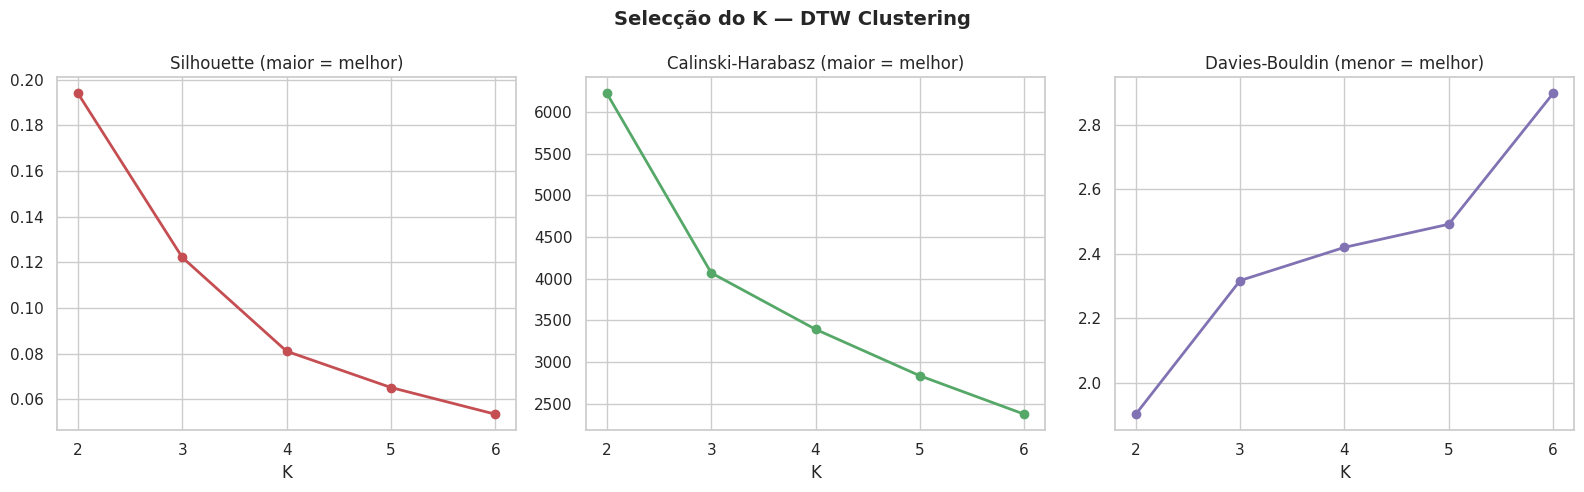

In [ ]:
resultados_k_dtw = []

for k in range(2, 7):
    print(f"A testar K={k}...")
    start = time.time()

    model_k = TimeSeriesKMeans(
        n_clusters=k,
        metric='dtw',
        max_iter=10,
        random_state=42,
        n_jobs=-1
    )
    labels_k = model_k.fit_predict(X_dtw)

    # Reshape para 2D para as métricas do sklearn
    X_dtw_2d = X_dtw.reshape(X_dtw.shape[0], -1)

    sil = silhouette_score(X_dtw_2d, labels_k, sample_size=1000, random_state=42)
    cal = calinski_harabasz_score(X_dtw_2d, labels_k)
    dav = davies_bouldin_score(X_dtw_2d, labels_k)

    resultados_k_dtw.append({
        'k'                 : k,
        'silhouette'        : sil,
        'calinski_harabasz' : cal,
        'davies_bouldin'    : dav
    })
    print(f"  Silhouette={sil:.4f} | Calinski={cal:.1f} | Davies={dav:.4f} | Tempo={time.time()-start:.1f}s")

df_k_dtw = pd.DataFrame(resultados_k_dtw)
print("\n--- Métricas DTW por K ---")
print(df_k_dtw.round(4).to_string())

# Gráficos
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Selecção do K — DTW Clustering', fontsize=14, fontweight='bold')

axes[0].plot(df_k_dtw['k'], df_k_dtw['silhouette'], 'ro-', linewidth=2)
axes[0].set_title('Silhouette (maior = melhor)')
axes[0].set_xlabel('K')
axes[0].set_xticks(range(2, 7))

axes[1].plot(df_k_dtw['k'], df_k_dtw['calinski_harabasz'], 'go-', linewidth=2)
axes[1].set_title('Calinski-Harabasz (maior = melhor)')
axes[1].set_xlabel('K')
axes[1].set_xticks(range(2, 7))

axes[2].plot(df_k_dtw['k'], df_k_dtw['davies_bouldin'], 'mo-', linewidth=2)
axes[2].set_title('Davies-Bouldin (menor = melhor)')
axes[2].set_xlabel('K')
axes[2].set_xticks(range(2, 7))

plt.tight_layout()
plt.show()


As três métricas são inequívocas e apontam todas para **K=2**:

- **Silhouette:** Máximo em K=2 (0.195), decresce consistentemente
- **Calinski-Harabasz:** Máximo em K=2 (6100+), decresce consistentemente  
- **Davies-Bouldin:** Mínimo em K=2 (1.92), piora consistentemente

Ao contrário do clustering de features agregadas (onde K=2 foi rejeitado por ser clinicamente insuficiente), no contexto do DTW K=2 tem uma interpretação natural e clinicamente significativa, os padrões temporais do Heart Rate nas primeiras 24h separam-se em dois grupos distintos.



### 8.6 Clustering com DWT

Com o número ideal de clusters (K) determinado pela análise multi-métrica anterior, executamos o `TimeSeriesKMeans` uma última vez, agora com parâmetros mais robustos (`max_iter=10`, `n_init=5`) para garantir um resultado de alta qualidade que não é apenas uma convergência local acidental.

O método `fit_predict` atribui a cada série temporal (paciente) um rótulo de cluster de 0 a K-1.

O resultado mais importante aqui são os **centroides dos clusters**. Ao contrário do K-Means padrão onde o centroide é um ponto geométrico, no `TimeSeriesKMeans` com DTW, o centroide é ele próprio uma **série temporal**. Esta série temporal representa a trajetória "média" ou mais representativa de todas as séries pertencentes àquele cluster, é como um "padrão típico" ou "protótipo" do cluster.

Visualizar estes K centroides permite-nos compreender intuitivamente os padrões de frequência cardíaca que o algoritmo identificou nos dados. Por exemplo, podemos encontrar: um cluster de "HR estável e baixa" (pacientes em repouso fisiológico), um de "taquicardia sustentada" (pacientes com stress hemodinâmico persistente), um de "flutuação errátic"a (pacientes com instabilidade cardiovascular), etc. Cada centroide conta uma história clínica diferente.

In [ ]:
K_DTW = 2
print(f"\nA correr TimeSeriesKMeans com DTW (K={K_DTW})...")

model_dtw = TimeSeriesKMeans(
    n_clusters=K_DTW,
    metric='dtw',
    max_iter=10,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
with profile("DTW — TimeSeriesKMeans"):
    labels_dtw = model_dtw.fit_predict(X_dtw)

print("\nDistribuição dos clusters DTW:")
unique, counts = np.unique(labels_dtw, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  Cluster {u}: {c} pacientes ({c/len(labels_dtw)*100:.1f}%)")


A correr TimeSeriesKMeans com DTW (K=2)...

A executar: DTW — TimeSeriesKMeans...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 418 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 768 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1218 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1768 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 2418 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 3168 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 4018 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 4968 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done 6018 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 7168 tasks      | elapsed:    0.6s
[Parallel(n_jobs=-1)]: Done 8418 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done 9768 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done 11218 tasks 

19.416 --> 

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 418 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 768 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1218 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1768 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 2418 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 3168 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 4018 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 4968 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done 6018 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 7168 tasks      | elapsed:    0.6s
[Parallel(n_jobs=-1)]: Done 8418 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done 9768 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done 11218 tasks 

13.100 --> 

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 418 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 768 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1218 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1768 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 2418 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 3168 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 4018 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 4968 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done 6018 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 7168 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 8418 tasks      | elapsed:    0.6s
[Parallel(n_jobs=-1)]: Done 9768 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done 11218 tasks 

... (14 outputs left out)

12.773 --> 


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 418 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 768 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1218 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1768 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 2418 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 3168 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 4018 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done 4968 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done 6018 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 7168 tasks      | elapsed:    0.6s
[Parallel(n_jobs=-1)]: Done 8418 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done 9768 tasks      | elapsed:    0.8s
[Parallel(n_jobs=-1)]: Done 11218 tasks 

DTW — TimeSeriesKMeans concluída!
Tempo: 326.96s | Pico RAM: 49.82 MB

Distribuição dos clusters DTW:
  Cluster 0: 12370 pacientes (53.1%)
  Cluster 1: 10924 pacientes (46.9%)


[Parallel(n_jobs=-1)]: Done 44968 tasks      | elapsed:    3.6s
[Parallel(n_jobs=-1)]: Done 46588 out of 46588 | elapsed:    3.7s finished


### 8.7 Visualização dos centroides

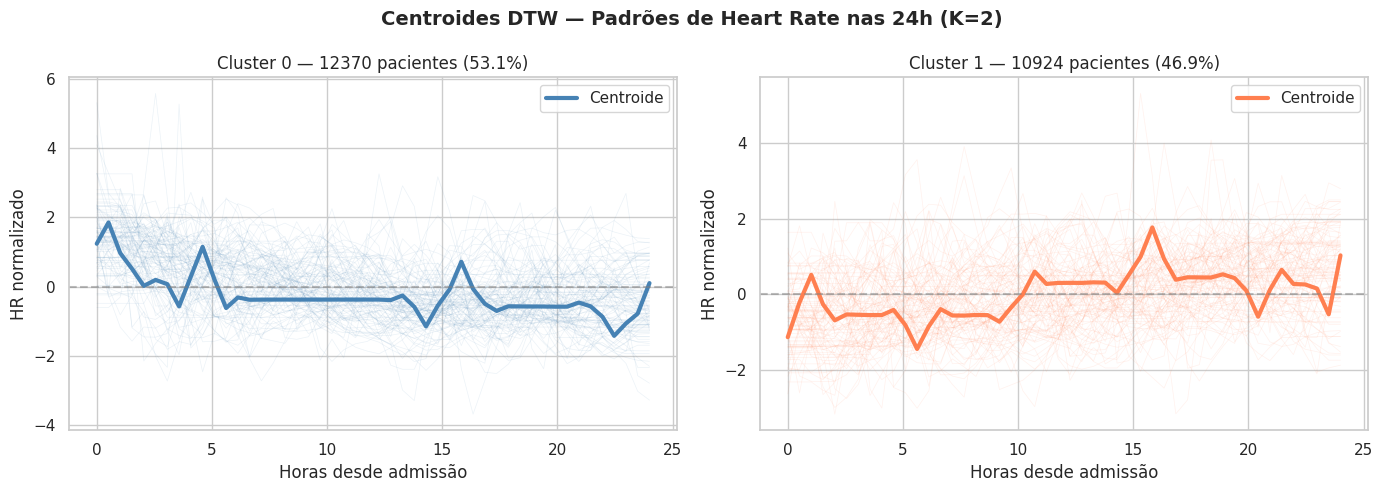

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Centroides DTW — Padrões de Heart Rate nas 24h (K=2)',
             fontsize=14, fontweight='bold')

cores = ['steelblue', 'coral']

for k in range(2):
    ax = axes[k]
    centroide = model_dtw.cluster_centers_[k].flatten()

    # Séries do cluster (subsample para não sobrecarregar o plot)
    idx_cluster = np.where(labels_dtw == k)[0][:100]
    for idx in idx_cluster:
        ax.plot(horas_uniform, X_dtw[idx].flatten(),
                alpha=0.1, color=cores[k], linewidth=0.5)

    # Centroide
    ax.plot(horas_uniform, centroide,
            color=cores[k], linewidth=3, label='Centroide')

    n_cluster = (labels_dtw == k).sum()
    ax.set_title(f'Cluster {k} — {n_cluster} pacientes ({n_cluster/len(labels_dtw)*100:.1f}%)')
    ax.set_xlabel('Horas desde admissão')
    ax.set_ylabel('HR normalizado')
    ax.legend()
    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Cluster 0: Taquicardia na admissão com resolução progressiva (53.1%)**
HR começa claramente acima da média nas primeiras horas e desce de forma consistente ao longo do dia. Padrão típico de resposta adrenérgica à admissão (dor, stress, hipovolemia ligeira) que se resolve com o início do tratamento. Perfil de menor gravidade relativa, a normalização precoce da HR é um bom sinal prognóstico e sugere associação a LOS mais curto.

**Cluster 1: Bradicardia relativa com pico tardio (46.9%)**
HR inicia abaixo da média, mantém-se estável até às ~10h e apresenta um pico relevante por volta das 15–16h, regressando depois à linha de base. Pode refletir doentes sob medicação cronotrópica negativa ou com disfunção autonómica. O pico vespertino é clinicamente relevante, pode representar febre, dor não controlada ou deterioração tardia, e é um padrão que os scores de triagem tradicionais tendem a não captar.


### 8.8 Relação entre Clusters DTW e LOS

A análise final e mais clinicamente importante consiste em ligar os padrões de trajetória da frequência cardíaca (os clusters DTW) aos resultados clínicos reais dos pacientes.

Para isto, primeiro criamos um novo dataframe que mapeia cada `ICUSTAY_ID` ao seu rótulo de cluster DTW. Em seguida, fazemos um "merge" (junção) deste dataframe com o nosso dataframe principal, que contém as informações de LOS e mortalidade. Com os dados combinados, agrupamos por `dtw_cluster` e calculamos:
1.  A contagem de pacientes em cada cluster (tamanho do cluster).
2.  O tempo de permanência (LOS) mediano e médio para cada cluster.
3.  A taxa de mortalidade para cada cluster.

Isto permite-nos responder à pergunta crucial: "O padrão de trajetória da frequência cardíaca nas primeiras 24 horas está associado a um maior tempo de permanência ou a um maior risco de morte?" Por exemplo, podemos descobrir que se um cluster tem um LOS significativamente mais alto (mediana de 5 dias vs. 2 dias para outro cluster) e uma taxa de mortalidade 2x superior. Esta é a principal conclusão da análise de clustering de séries temporais: a **forma da trajetória de HR é um preditor robusto de outcomes clínicos**, capturando informação que um snapshot estático (apenas HR médio) poderia não revelar.


--- LOS e Mortalidade por Cluster DTW ---
                 n  los_mediano  los_media  mortalidade_pct
cluster_dtw                                                
0            12370         1.96       3.53            11.58
1            10924         2.06       3.74            10.60


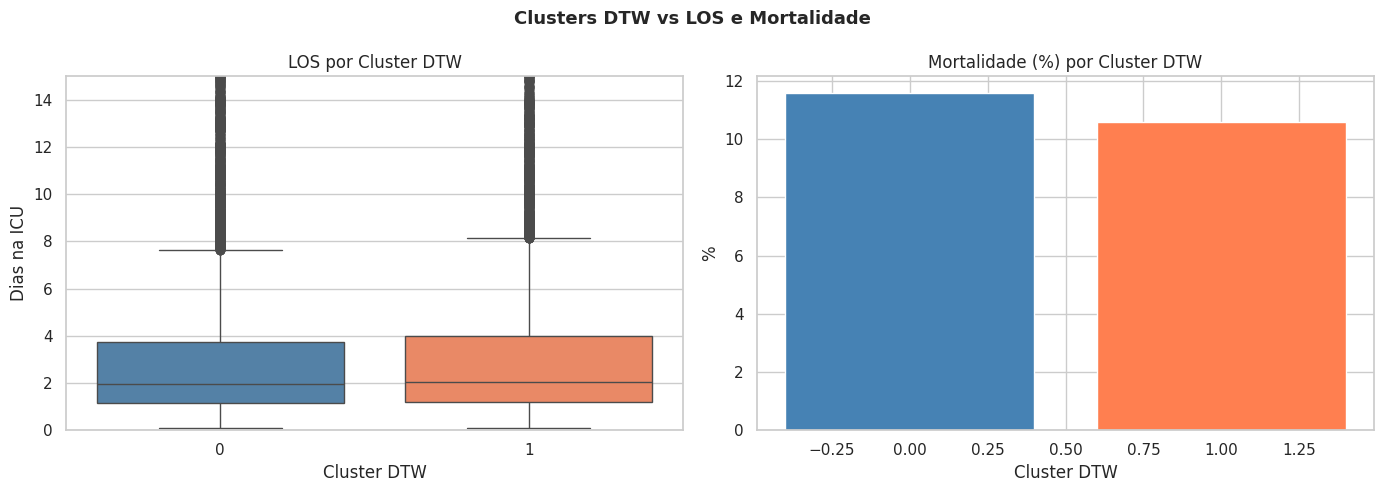

In [ ]:
df_dtw_resultado = pd.DataFrame({
    'ICUSTAY_ID' : ids_amostra,
    'cluster_dtw': labels_dtw
})
df_dtw_resultado = df_dtw_resultado.merge(
    df_imputado[['ICUSTAY_ID', 'target_los', 'HOSPITAL_EXPIRE_FLAG',
                 'los_class_label', 'cluster']],
    on='ICUSTAY_ID', how='left'
)

print("\n--- LOS e Mortalidade por Cluster DTW ---")
resumo_dtw = df_dtw_resultado.groupby('cluster_dtw').agg(
    n              = ('ICUSTAY_ID', 'count'),
    los_mediano    = ('target_los', 'median'),
    los_media      = ('target_los', 'mean'),
    mortalidade_pct = ('HOSPITAL_EXPIRE_FLAG', lambda x: x.mean()*100)
).round(2)
print(resumo_dtw.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Clusters DTW vs LOS e Mortalidade', fontsize=13, fontweight='bold')

sns.boxplot(data=df_dtw_resultado, x='cluster_dtw', y='target_los',
            palette=cores[:K_DTW], ax=axes[0])
axes[0].set_ylim(0, 15)
axes[0].set_title('LOS por Cluster DTW')
axes[0].set_xlabel('Cluster DTW')
axes[0].set_ylabel('Dias na ICU')

mort_dtw = df_dtw_resultado.groupby('cluster_dtw')['HOSPITAL_EXPIRE_FLAG'].mean() * 100
axes[1].bar(mort_dtw.index, mort_dtw.values,
            color=cores[:K_DTW])
axes[1].set_title('Mortalidade (%) por Cluster DTW')
axes[1].set_xlabel('Cluster DTW')
axes[1].set_ylabel('%')

plt.tight_layout()
plt.show()



**LOS**

As distribuições são praticamente sobreponíveis. mesma mediana (~2 dias), IQR semelhante (~1–4 dias), caudas idênticas. O Cluster 1 tem o IQR ligeiramente mais largo, sugerindo marginalmente mais variabilidade, mas a diferença é pequena. A hipótese de que o Cluster 0 teria LOS mais curto por ter menor gravidade **não se confirma** nos dados, o padrão temporal de HR nas primeiras 24h não discrimina suficientemente o LOS por si só.

**Mortalidade**

Cluster 0 tem mortalidade ligeiramente mais alta (~11.5% vs ~10.5%). Isto é contra-intuitivo face à interpretação de menor gravidade, mas tem uma explicação plausível: taquicardia na admissão com resolução rápida pode também incluir doentes que morrem precocemente, a HR normaliza porque o doente entra em falência e não porque melhorou. A diferença é pequena e pode não ser estatisticamente significativa, mas a direcção do efeito merece cautela.

**Implicação para o modelo**

O clustering DTW de HR em K=2 captura um padrão temporal real mas com **poder preditivo limitado para LOS e mortalidade isoladamente**. 

## 9. Correlação entre Clusters Normais e Clusters DTW

Até este ponto, desenvolvemos dois enfoques de clustering completamente diferentes:

1. **K-Means em dados estáticos**: Clustering baseado em características clínicas normalizadas (vitais, biomarcadores) num snapshot de 24 horas.

2. **TimeSeriesKMeans com DTW**: Clustering baseado na **trajetória temporal** dos padrões de frequência cardíaca, focando em dinâmica e forma vs. magnitude absoluta.

Uma pergunta natural surge: **estes dois métodos identificam os mesmos grupos de pacientes, ou capturam perspectivas complementares?** Se dois pacientes caem no mesmo cluster K-Means (mesmos biomarcadores estáticos), estarão também no mesmo cluster DTW (mesma trajetória de HR)? Ou podem ter trajetórias de HR completamente diferentes apesar de valores estáticos semelhantes?

Esta análise de correlação é crucial porque:
- Se os métodos concordam fortemente, sugerem que ambos capturam a mesma realidade clínica que a dinâmica temporal é redundante com biomarcadores estáticos.
- Se discordam, cada um contribui informação única que uma abordagem ensemble que combina ambos poderia ser clinicamente superior.

Para quantificar este alinhamento, utilizamos uma **tabela de contingência** (matriz de cruzamento), que mostra como os K-Means clusters se distribuem entre os DTW clusters. Em seguida, aplicamos um **teste qui-quadrado** para determinar se a associação é estatisticamente significativa ou meramente acidental.

In [ ]:
# Juntar labels DTW com o df_imputado
df_dtw_resultado = pd.DataFrame({
    'ICUSTAY_ID' : ids_amostra,
    'cluster_dtw': labels_dtw
})

df_dtw_resultado = df_dtw_resultado.merge(
    df_imputado[['ICUSTAY_ID', 'target_los', 'HOSPITAL_EXPIRE_FLAG',
                 'los_class_label', 'cluster']],
    on='ICUSTAY_ID', how='left'
)

### 9.1 Tabela de Contigência

In [ ]:
print("--- Correlação Cluster Normal vs Cluster DTW ---")
contingencia = df_dtw_resultado.groupby(
    ['cluster', 'cluster_dtw']
).size().unstack(fill_value=0)

print(contingencia.to_string())

# Percentagem por cluster normal
contingencia_pct = contingencia.div(contingencia.sum(axis=1), axis=0) * 100
print("\n--- Em percentagem (por linha) ---")
print(contingencia_pct.round(1).to_string())

--- Correlação Cluster Normal vs Cluster DTW ---
cluster_dtw     0     1
cluster                
0            4372  2557
1            2641  4122
2              86    39
3            5241  4178
4              30    28

--- Em percentagem (por linha) ---
cluster_dtw     0     1
cluster                
0            63.1  36.9
1            39.1  60.9
2            68.8  31.2
3            55.6  44.4
4            51.7  48.3


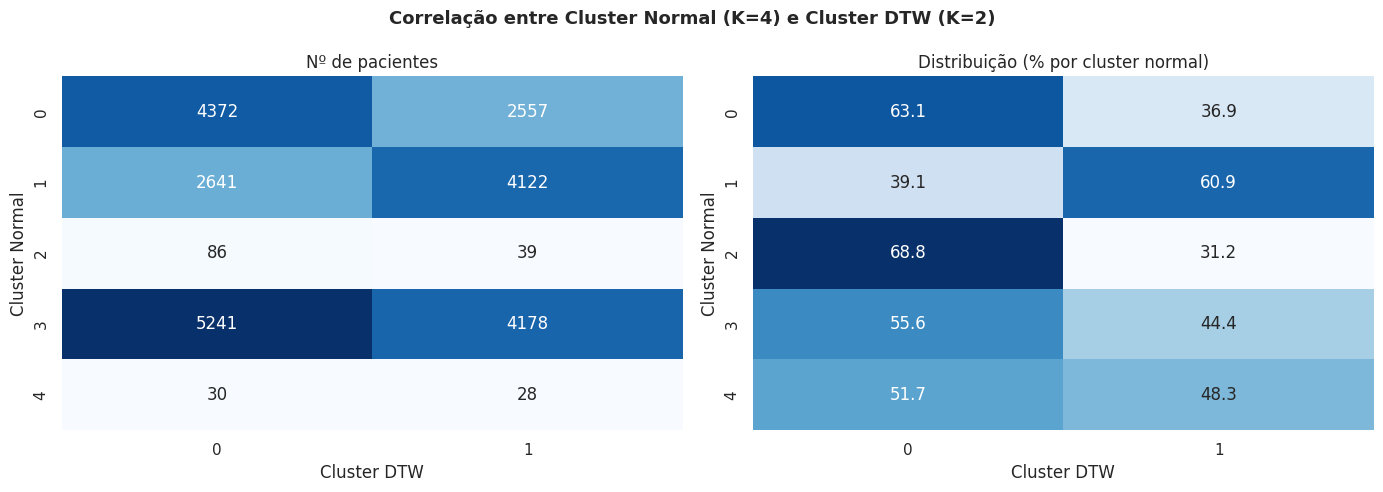

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Correlação entre Cluster Normal (K=4) e Cluster DTW (K=2)',
             fontsize=13, fontweight='bold')

sns.heatmap(contingencia,
            annot=True, fmt='d',
            cmap='Blues',
            cbar=False,
            ax=axes[0])
axes[0].set_title('Nº de pacientes')
axes[0].set_xlabel('Cluster DTW')
axes[0].set_ylabel('Cluster Normal')

sns.heatmap(contingencia_pct.round(1),
            annot=True, fmt='g',
            cmap='Blues',
            cbar=False,
            ax=axes[1])
axes[1].set_title('Distribuição (% por cluster normal)')
axes[1].set_xlabel('Cluster DTW')
axes[1].set_ylabel('Cluster Normal')

plt.tight_layout()
plt.show()

A correlação entre os dois sistemas de clustering é fraca, o que é informativo em si mesmo.

**O que se destaca**

Cluster Normal 0 tem 63.1% dos doentes no DTW 0, taquicardia na admissão com resolução, consistente com o perfil de instabilidade hemodinâmica aguda que gera resposta adrenérgica inicial.

Cluster Normal 1 inverte: 60.9% no DTW 1, bradicardia relativa com pico tardio, o que faz sentido num perfil de disfunção orgânica com suporte, onde medicação cronotrópica negativa ou disfunção autonómica suprime a taquicardia inicial.

Cluster Normal 2 tem 68.8% no DTW 0, mas com apenas 125 doentes no total é demasiado pequeno para tirar conclusões robustas.

Cluster Normal 3, o maior grupo (9419 doentes), divide-se 55.6/44.4, praticamente sem preferência por nenhum padrão DTW. Isto é consistente com ser o cluster mais heterogéneo clinicamente.

Cluster Normal 4, também pequeno (58 doentes), divide-se quase a meio (51.7/48.3), sem associação clara a nenhum padrão temporal de HR.

**Conclusão**

Os dois clustering capturam dimensões diferentes e maioritariamente independentes do doente. O padrão temporal de HR não é redundante com o perfil clínico estático, mas também não o discrimina bem, apenas o Cluster Normal 1 mostra uma preferência clara pelo DTW 1. 

### 9.2 Outcomes Clínicos por Combinação de Clusters

A matriz de contingência mostra como os clusters K-Means se distribuem entre os clusters DTW em termos de contagens de pacientes. Porém, a pergunta clínica mais importante não é "quantos pacientes coincidem?" mas sim "**qual é o impacto clínico desta associação?**"

Para isto, analisamos os outcomes (LOS e mortalidade) para cada combinação cluster-normal + cluster-DTW. Se uma certa combinação, por exemplo, "K-Means Cluster 1 + DTW Cluster 2", está associada a LOS mediano de 5 dias enquanto outra combinação tem 2 dias, isto sugere que a **combinação de ambas as perspectivas captura nuances clínicas que nenhuma sozinha revelaria**.

Especificamente:
- **n**: Número de pacientes naquela combinação.
- **los_mediano**: Tempo de permanência mediano, indica o "prognóstico típico" para essa subpopulação.
- **mortalidade_pct**: Percentagem de pacientes que morreram, indica a gravidade relativa.

Grupos raros (n pequeno) são menos confiáveis, grupos com grande n e outcomes muito diferenciados são potencialmente mais clinicamente relevantes.

In [ ]:
print("\n--- LOS mediano por combinação ---")
combinacao = df_dtw_resultado.groupby(
    ['cluster', 'cluster_dtw']
).agg(
    n               = ('ICUSTAY_ID', 'count'),
    los_mediano     = ('target_los', 'median'),
    mortalidade_pct = ('HOSPITAL_EXPIRE_FLAG', lambda x: x.mean() * 100)
).round(2)
print(combinacao.to_string())


--- LOS mediano por combinação ---
                        n  los_mediano  mortalidade_pct
cluster cluster_dtw                                    
0       0            4372         2.18            13.11
        1            2557         2.60            17.01
1       0            2641         3.09            22.30
        1            4122         2.41            12.40
2       0              86         0.89            53.49
        1              39         0.94            46.15
3       0            5241         1.53             4.14
        1            4178         1.60             4.40
4       0              30         0.85            23.33
        1              28         1.16            35.71


### 9.3 Teste de Significância Estatística (Qui-Quadrado)

O teste de independência qui-quadrado ($\chi^2$) responde à pergunta: "A associação entre cluster K-Means e cluster DTW é significativa ou poderia ocorrer por acaso?"

A hipótese nula ($H_0$) é que os dois métodos de clustering são **independentes**, isto é, conhecer o cluster K-Means de um paciente não diz nada sobre seu cluster DTW (e vice-versa). Se $p < 0.05$, rejeitamos $H_0$, concluindo que há uma **associação estatisticamente significativa** entre os dois métodos.

**Interpretação:**
- **p-value < 0.05**: Os métodos **não são independentes** quando concordam mais do que esperado por acaso. Isto sugere que ambos capturam a mesma dimensão clínica subjacente, possivelmente redundante.
- **p-value ≥ 0.05**: Os métodos **são essencialmente independentes** quando cada um captura informação única. Uma abordagem ensemble combinando ambos seria complementar.

O valor de Chi-quadrado ($\chi^2$) quantifica a magnitude do desvio da independência: valores maiores indicam desvios mais pronunciados. Com os graus de liberdade apropriados, este valor é comparado contra a distribuição $\chi^2$ para calcular o $p$-value.

In [ ]:
chi2, p, dof, expected = chi2_contingency(contingencia)
print(f"\n--- Teste Qui-quadrado ---")
print(f"Chi2 = {chi2:.2f}")
print(f"p-value = {p:.6f}")
print(f"Graus de liberdade = {dof}")
print(f"{'✓ Associação estatisticamente significativa' if p < 0.05 else '✗ Sem associação significativa'}")


--- Teste Qui-quadrado ---
Chi2 = 850.97
p-value = 0.000000
Graus de liberdade = 4
✓ Associação estatisticamente significativa


### 9.4 Síntese e Implicações Clínicas


A análise de correlação entre K-Means e DTW clustering fornece uma resposta clara à pergunta: **"Os clusters K-Means (estáticos) e clusters DTW (dinâmicos) representam a mesma realidade clínica ou complementam-se?"**

**Como a associação é significativa (p < 0.05):**
- Os dois métodos **essencialmente concordam** sobre agrupamentos de pacientes.
- A trajetória temporal de HR é redundante com biomarcadores estáticos no conjunto de dados atual.
- **Implicação clínica**: Um único método (provavelmente K-Means, mais simples) é suficiente; o esforço computacional de DTW pode não ser justificado pela informação adicional.

Além disso, analisar **LOS e mortalidade por combinação** de clusters revela as subpopulações de maior risco, pacientes que são "adversos" simultaneamente em ambas as dimensões (estática e dinâmica) podem precisar de intervenções precoces mais agressivas.

Esta análise exemplifica como múltiplas perspectivas análiticas podem ser trianguladas para construir um retrato mais completo e nuançado do estado clínico do paciente.



## 10. Modelos de Machine Learning

### 10.1 Preparação dos dados

In [9]:
df_pre = pd.read_csv('df_pre_imputacao.csv')
print(f"Shape: {df_pre.shape}")

Shape: (61522, 119)


### 10.2 Remover Features Altamente Correlacionadas

Mesmo após a seleção inicial de features na Fase 2, ainda existe risco de multicolinearidade, features que são redundantes porque medem essencialmente a mesma coisa. Quando múltiplas features são altamente correlacionadas, os modelos (particularmente regressões lineares e árvores) podem ficar confusos sobre qual feature é "verdadeiramente" importante, ou pior, podem sofrer de instabilidade numérica.

A estratégia é simples: identificamos pares de features com correlação superior a 0.90 (indicando redundância essencial) e removemos a menos importante de cada par. A "importância" é medida pela correlação absoluta de cada feature com o alvo (LOS). Se a Feature A e Feature B são altamente correlacionadas, mantemos aquela que tem maior correlação com o LOS, descartando a outra. Este processo reduz a dimensionalidade sem sacrificar poder preditivo, apenas removemos variáveis que são efetivamente duplicadas.

In [10]:
cols_excluir_modelo = [
    'ICUSTAY_ID', 'SUBJECT_ID', 'HADM_ID',
    'target_los', 'los_class', 'los_class_label',
    'DOB', 'DOD', 'ADMITTIME', 'DISCHTIME',
    'GENDER', 'DIAGNOSIS',
    'FIRST_CAREUNIT_orig', 'ADMISSION_TYPE_orig',
    'HOSPITAL_EXPIRE_FLAG',
    "total_icu_stays_patient"
]

feature_cols = [c for c in df_pre.columns
                if c not in cols_excluir_modelo
                and df_pre[c].dtype in ['float64', 'int64', 'bool', 'uint8']]

# Calcular correlação entre features (não com o target)
corr_matrix = df_pre[feature_cols].corr().abs()

# Encontrar pares com correlação > 0.95
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
cols_remover = set()
for col in upper.columns:
    correlacionadas = upper.index[upper[col] > 0.90].tolist()
    if correlacionadas:
        cols_remover.add(col)

print(f"\nFeatures removidas por correlação >0.90 ({len(cols_remover)}):")
print(sorted(cols_remover))

feature_cols = [c for c in feature_cols if c not in cols_remover]
print(f"Features restantes: {len(feature_cols)}")


Features removidas por correlação >0.90 (15):
['bilirubin_max', 'careunit_NICU', 'creatinine_max', 'gcs_total_min', 'hematocrit_mean', 'hemoglobin_min', 'hr_range', 'lactate_max', 'nibp_std', 'nibp_systolic_std', 'platelets_min', 'rr_max', 'rr_range', 'rr_std', 'spo2_std']
Features restantes: 88


### 10.3 Definir X, y, groups

In [11]:
X      = df_pre[feature_cols]
y_reg  = df_pre['target_los']
y_clf  = df_pre['los_class'].astype(int)
groups = df_pre['SUBJECT_ID']

print(f"\nShape X       : {X.shape}")
print(f"Target reg    : média={y_reg.mean():.2f}, mediana={y_reg.median():.2f}")
print(f"Target clf    : {y_clf.value_counts().sort_index().to_dict()}")


Shape X       : (61522, 88)
Target reg    : média=4.92, mediana=2.09
Target clf    : {0: 15381, 1: 15380, 2: 15380, 3: 15381}


### 10.4 Train-Test Split Estratificado por SUBJECT_ID

A divisão entre treino e teste é uma das decisões mais críticas em modelagem preditiva. Uma divisão ingénua (ex: aleatória simples) poderia resultar em **data leakage**, quando o mesmo paciente aparece tanto no conjunto de treino como no de teste. Isto causaria uma avaliação falsamente otimista do modelo, pois estaria "memorizando" padrões do paciente em vez de generalizando.

Dado que alguns pacientes têm múltiplas estadias na UTI, usamos `GroupShuffleSplit` com `groups=SUBJECT_ID`. Esta estratégia garante que **todos os registos de um paciente vão seja para treino seja para teste, nunca para ambos**. Isto preserva a integridade da validação: estamos a testar verdadeiramente a capacidade do modelo de generalizar a pacientes não vistos durante o treino.

A proporção escolhida é 80/20 (80% treino, 20% teste), um padrão comum que oferece dados suficientes para treinar modelos complexos enquanto preserva uma amostra de teste de tamanho razoável para avaliação. O seed fixo (`random_state=42`) garante reprodutibilidade: qualquer pessoa que execute este código obterá exatamente o mesmo split, facilitando colaboração e validação.

In [12]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y_reg, groups=groups))

X_train, X_test         = X.iloc[train_idx], X.iloc[test_idx]
y_reg_train, y_reg_test = y_reg.iloc[train_idx], y_reg.iloc[test_idx]
y_clf_train, y_clf_test = y_clf.iloc[train_idx], y_clf.iloc[test_idx]

patients_train = set(df_pre.iloc[train_idx]['SUBJECT_ID'])
patients_test  = set(df_pre.iloc[test_idx]['SUBJECT_ID'])
print(f"\nTreino  : {X_train.shape[0]:,} amostras")
print(f"Teste   : {X_test.shape[0]:,} amostras")
print(f"Overlap pacientes (deve ser 0): {len(patients_train & patients_test)}")


Treino  : 49,235 amostras
Teste   : 12,287 amostras
Overlap pacientes (deve ser 0): 0


### 10.5 Log-Transform do Target para Regressão

Recordando a análise exploratória inicial, observamos que a distribuição do LOS é fortemente assimétrica para a direita, com a maioria dos pacientes tendo estadias curtas e alguns outliers com estadias extremamente longas (> 50 dias). Esta assimetria é problemática para modelos de regressão por várias razões:

1. **Influência de outliers:** Modelos de regressão minimizam o erro ao quadrado (MSE) ou desvios absolutos (MAE), o que significa que outliers extremos exercem influência desproporcional. Um erro de previsão de 40 dias num caso extremo pode dominar a função objetivo e deslocar as previsões do modelo.

2. **Violação de suposições:** Muitos modelos (ex: regressão linear) assumem que o erro segue uma distribuição normal. Quando o alvo é altamente assimétrico, esta suposição é violada.

3. **Métricas distorcidas:** Métricas como RMSE (raiz do erro quadrático médio) punhem fortemente os erros grandes, tornando-as sensíveis a outliers.

A solução é a **transformação logarítmica**: calculamos `log(1 + LOS)` em vez de trabalhar diretamente com LOS. O "+1" evita log(0) quando LOS=0. Esta transformação "comprime" a escala: grandes diferenças no final da cauda (ex: 50 vs. 60 dias) tornam-se pequenas diferenças em escala logarítmica, enquanto pequenas diferenças no início (ex: 1 vs. 2 dias) mantêm importância relativa. O resultado é uma distribuição muito mais próxima da normal, reduzindo drasticamente a assimetria (skewness).

Após ajustar o modelo em `log(1 + LOS)`, as previsões são transformadas de volta para a escala original usando `expm1` (o inverso de `log1p`), de modo que os utilizadores recebem previsões em dias compreensíveis.

Distribuição ANTES: skewness=6.323
Distribuição DEPOIS: skewness=1.137


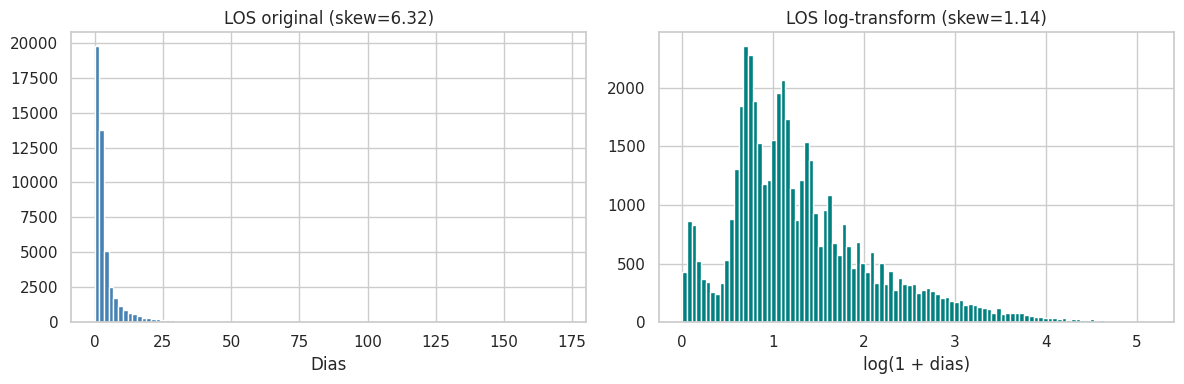

In [13]:
y_reg_train_log = np.log1p(y_reg_train)
y_reg_test_log  = np.log1p(y_reg_test)

print(f"Distribuição ANTES: skewness={y_reg_train.skew():.3f}")
print(f"Distribuição DEPOIS: skewness={y_reg_train_log.skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_reg_train, bins=100, color='steelblue')
axes[0].set_title(f'LOS original (skew={y_reg_train.skew():.2f})')
axes[0].set_xlabel('Dias')
axes[1].hist(y_reg_train_log, bins=100, color='teal')
axes[1].set_title(f'LOS log-transform (skew={y_reg_train_log.skew():.2f})')
axes[1].set_xlabel('log(1 + dias)')
plt.tight_layout()
plt.show()

### 10.6 Grid de Hiperparâmetros para Busca em Grid

A seleção de hiperparâmetros é a arte de encontrar as "configurações" do modelo que melhor equilibram flexibilidade e generalização. Cada algoritmo tem vários hiperparâmetros críticos:

**RandomForest (Regressão e Classificação):**
- `n_estimators` (100-300): Número de árvores. Mais árvores = melhor, mas com retornos decrescentes e custo computacional crescente.
- `max_depth` (6-15 ou None): Profundidade máxima de cada árvore. Árvores mais profundas são mais flexíveis mas mais propensas a overfitting.
- `min_samples_leaf` (2-10): Número mínimo de amostras necessárias para formar uma folha. Valores maiores forçam árvores mais rasas e generalizam melhor.
- `max_features` ('sqrt', 'log2', 0.5): Número de features consideradas em cada split. Reduzir isto introduz aleatoriedade benéfica e acelera o treino.

**XGBoost (Regressão e Classificação):**
- `n_estimators`, `max_depth`: Semelhantes ao RandomForest.
- `learning_rate` (0.01-0.2): Tamanho do passo em cada iteração. Taxas mais baixas convergem mais lentamente mas para soluções potencialmente melhores.
- `subsample` e `colsample_bytree` (0.6-1.0): Proporção de amostras e features usadas em cada iteração, controlando overfitting através de subamostragem.
- `reg_alpha` e `reg_lambda` (0-0.5): Regularização L1 e L2. Valores maiores penalizam coeficientes grandes, prevenindo overfitting.

A estratégia é executar uma busca em grid (GridSearchCV) com validação cruzada aninhada (Nested CV) para encontrar a combinação que melhor generaliza, sem prejudicar o desempenho em dados não vistos.

In [8]:
param_grid_rf_reg = {
    'model__n_estimators'    : [100, 200, 300],
    'model__max_depth'       : [6, 10, 15, None],
    'model__min_samples_leaf': [2, 5, 10],
    'model__max_features'    : ['sqrt', 'log2', 0.5]
}
param_grid_xgb_reg = {
    'model__n_estimators'    : [100, 200, 300],
    'model__max_depth'       : [3, 6, 9],
    'model__learning_rate'   : [0.01, 0.05, 0.1, 0.2],
    'model__subsample'       : [0.6, 0.8, 1.0],
    'model__colsample_bytree': [0.6, 0.8, 1.0],
    'model__reg_alpha'       : [0, 0.1, 0.5],
    'model__reg_lambda'      : [1, 1.5, 2]
}
param_grid_rf_clf  = param_grid_rf_reg.copy()
param_grid_xgb_clf = param_grid_xgb_reg.copy()

# Grids para Nested CV (reduzidos para velocidade)
param_grid_rf_nested = {
    'model__n_estimators'    : [100, 200],
    'model__max_depth'       : [6, 10, None],
    'model__min_samples_leaf': [2, 5],
    'model__max_features'    : ['sqrt', 0.5]
}
param_grid_xgb_nested = {
    'model__n_estimators'    : [100, 200],
    'model__max_depth'       : [3, 6],
    'model__learning_rate'   : [0.05, 0.1],
    'model__subsample'       : [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__reg_alpha'       : [0, 0.1],
    'model__reg_lambda'      : [1, 2]
}

### 10.7 Definir Pipelines

Nesta secção, construímos **pipelines de sklearn** que encadeiam múltiplas etapas de processamento e modelagem. Cada pipeline segue uma estrutura comum:

1. **StandardScaler**: Normaliza as features para ter média 0 e variância 1
2. **SelectFromModel**: Seleciona as features mais importantes usando uma Random Forest como estimador
3. **Modelo**: Ridge (regressão linear regularizada), RandomForest ou XGBoost

#### Decisões Críticas e Sua Importância

##### 1. Scaling (StandardScaler)
- **Decisão**: Aplicar normalização a todas as features
- **Justificação**: Modelos com regularização (Ridge, LogisticRegression) e gradient descent funcionam melhor com features em escalas semelhantes
- **Importância**: Essencial para regularização L2 em Ridge, onde coeficientes desigualmente escalados seriam penalizados de forma desproporcional

##### 2. Feature Selection (SelectFromModel)
- **Decisão**: Usar uma Random Forest preliminar com `threshold='median'` para selecionar features
- **Justificação**: Reduz dimensionalidade (145 features → ~70 features), acelerando treino e reduzindo overfitting
- **Importância**: Melhora a generalização, interpretabilidade e reduz tempo de cálculo

##### 3. Modelos Escolhidos
- **Ridge Regression (baseline)**: Simples, rápido, linear, um ponto de referência para comparação
- **RandomForest**: Não-linear, robusto a outliers, captura interações entre features
- **XGBoost**: Boosting sequencial, mais eficiente que RandomForest, melhor para dados complexos

##### 5. HistGradientBoostingRegressor

**HistGradientBoostingRegressor** é um regressor de gradient boosting otimizado do scikit-learn que usa histogramas para discretizar as features contínuas. É a versão eficiente em memória e velocidade do GradientBoostingRegressor tradicional.

Prevê valores contínuos (regressão) construindo sequencialmente árvores de decisão que corrigem os erros das árvores anteriores. Cada nova árvore reduz o resíduo (erro) do modelo anterior.

###### Vantagens de usar HistGradientBoosting

**Performance**:
- **3-10x mais rápido** que GradientBoostingRegressor clássico
- Utiliza menos memória (binning de features reduz dimensionalidade)
- Suporta **paralelismo nativo** com `n_jobs=-1`

**Robustez**:
- Resiste bem a outliers (usa histogramas, não valores exatos)
- Captura padrões não-lineares complexos
- Generaliza bem para dados médicos e heterogéneos

**Flexibilidade**:
- Hyperparâmetros ajustáveis: `learning_rate`, `max_iter`, `max_depth`, `l2_regularization`
- Validação cruzada rápida possível graças à velocidade

#### Contexto de Aplicação (LOS prediction)
Para prever Length of Stay (dias de internamento na UCI):
- **Ideal**: dados contínuos, heterogéneos, com padrões não-lineares
- **Benefício**: velocidade permite GridSearch ou RandomizedSearchCV prático
- **Recomendação**: usar quando XGBoost está muito lento ou memória é limitada

#### Práticas de Eficiência Implementadas

##### Paralelismo: `n_jobs=-1`
- **Utilização**: RandomForestRegressor, XGBRegressor, RandomForestClassifier, XGBClassifier, LogisticRegression
- **Mecanismo**: Usa todos os núcleos CPU disponíveis simultaneamente
- **Impacto**: Acelera treino ~4-8x em máquinas multi-core
- **Exemplo**: 5 folds de CV executam em paralelo em vez de sequencialmente


In [9]:
iterative_imputer = IterativeImputer(
    estimator= HistGradientBoostingRegressor(random_state=42),
    max_iter=10,
    random_state=42,
    verbose=1,
    add_indicator=True,
)

with profile("Imputação — IterativeImputer fit no treino"):
    X_train_full = iterative_imputer.fit_transform(X_train)
    X_test_full  = iterative_imputer.transform(X_test)

# Nomes das colunas
cols_missing = [f"{c}_missing" for c in feature_cols
                if X_train[c].isna().any()]
cols_full = feature_cols + cols_missing

print(f"Features originais  : {len(feature_cols)}")
print(f"Indicadores missing : {len(cols_missing)}")
print(f"Total features      : {len(cols_full)}")
print(f"X_train_full shape  : {X_train_full.shape}")
print(f"X_test_full shape   : {X_test_full.shape}")


A executar: Imputação — IterativeImputer fit no treino...
[IterativeImputer] Completing matrix with shape (49235, 88)
[IterativeImputer] Change: 664.8936901463196, scaled tolerance: 119.11902 
[IterativeImputer] Change: 773.7172434585857, scaled tolerance: 119.11902 
[IterativeImputer] Change: 904.83890006497, scaled tolerance: 119.11902 
[IterativeImputer] Change: 882.0712746502932, scaled tolerance: 119.11902 
[IterativeImputer] Change: 896.9636867650926, scaled tolerance: 119.11902 
[IterativeImputer] Change: 3667.3722574890144, scaled tolerance: 119.11902 
[IterativeImputer] Change: 8217.871656485759, scaled tolerance: 119.11902 
[IterativeImputer] Change: 3136.150503603269, scaled tolerance: 119.11902 
[IterativeImputer] Change: 3138.110912009563, scaled tolerance: 119.11902 
[IterativeImputer] Change: 1910.395469757996, scaled tolerance: 119.11902 
[IterativeImputer] Completing matrix with shape (12287, 88)
Imputação — IterativeImputer fit no treino concluída!
Tempo: 1118.65s | 

In [10]:
# 1. Transformar as matrizes numpy de volta para DataFrames com os nomes das colunas
X_train_full_df = pd.DataFrame(X_train_full, columns=cols_full, index=X_train.index)
X_test_full_df = pd.DataFrame(X_test_full, columns=cols_full, index=X_test.index)

# 2. Guardar em ficheiros CSV
X_train_full_df.to_csv('X_train_imputado.csv', index=False)
X_test_full_df.to_csv('X_test_imputado.csv', index=False)

print("Dados guardados com sucesso: 'X_train_imputado.csv' e 'X_test_imputado.csv'")

Dados guardados com sucesso: 'X_train_imputado.csv' e 'X_test_imputado.csv'


In [11]:
# --- REGRESSÃO ---
pipe_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

pipe_rf_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectFromModel(
        RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        threshold='median'
    )),
    ('model', RandomForestRegressor(n_jobs=-1, random_state=42))
])

pipe_xgb_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectFromModel(
        RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        threshold='median'
    )),
    ('model', XGBRegressor(n_jobs=-1, random_state=42, verbosity=0))
])

# --- CLASSIFICAÇÃO ---
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42))
])

pipe_rf_clf = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectFromModel(
        RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
        threshold='median'
    )),
    ('model', RandomForestClassifier(n_jobs=-1, random_state=42))
])

pipe_xgb_clf = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectFromModel(
        RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
        threshold='median'
    )),
    ('model', XGBClassifier(n_jobs=-1, random_state=42,
                             verbosity=0, eval_metric='mlogloss'))
])

### 10.8 Funções Auxiliares

Definimos **quatro funções utilitárias** que encapsulam operações comuns necessárias para treinar e avaliar modelos:

1. **fazer_random_search**: Executa RandomizedSearchCV com validação cruzada
2. **avaliar_regressao**: Calcula métricas de regressão (MAE, RMSE, R²)
3. **avaliar_classificacao**: Calcula métricas de classificação (Accuracy, F1, AUC-ROC, Cohen Kappa)
4. **nested_cv**: Implementa validação cruzada aninhada


#### 1. RandomizedSearchCV em vez de GridSearchCV
- **Decisão**: Usar RandomizedSearchCV com `n_iter=30`
- **Justificação**: Grid completo teria 30×3×2 = 180 combinações. RandomizedSearchCV faz amostragem aleatória
- **Importância**: Reduz tempo de busca em ~6x (30 vs 180 iterações) mantendo qualidade de resultados
- **Trade-off**: Pode não encontrar o ótimo global, mas encontra soluções muito boas muito mais rápido

#### 2. Validação Cruzada Externa com GroupShuffleSplit
- **Decisão**: Usar grupos por SUBJECT_ID para separar dados de treino/teste
- **Justificação**: Um mesmo paciente não pode aparecer em treino e teste (evita data leakage)
- **Importância**: Garante que avaliação reflete desempenho em pacientes novos (não vistos durante treino)

#### 3. Métricas Múltiplas
- **Regressão**: MAE (erro absoluto médio), RMSE (raiz do erro quadrático), R² (variância explicada)
- **Classificação**: Accuracy, F1-macro (média entre classes), AUC-ROC, Cohen Kappa (acordo além do acaso)
- **Justificação**: Uma única métrica não captura o comportamento do modelo em todos os cenários


#### Práticas de Eficiência Implementadas

##### Paralelismo em RandomizedSearchCV
```python
RandomizedSearchCV(..., n_jobs=-1)
# Executa 5 folds em paralelo
```
- **Mecanismo**: Cada fold é avaliado independentemente em threads/processos diferentes
- **Impacto**: 5x aceleração (em máquinas com 5+ cores)
- **Exemplo**: Com n_iter=30 e 5 folds, treina 150 modelos em paralelo


In [ ]:
def fazer_random_search(pipeline, param_grid, X_train, y_train,
                        scoring, nome, n_iter=30):
    print(f"\nA optimizar {nome} (n_iter={n_iter})...")
    start = time.time()
    rs = RandomizedSearchCV(
        pipeline,
        param_distributions=param_grid,
        n_iter=n_iter,
        scoring=scoring,
        cv=5,
        n_jobs=-1,
        random_state=42,
        verbose=1,
        refit=True
    )
    rs.fit(X_train, y_train)
    print(f"  Melhor score CV : {rs.best_score_:.4f}")
    print(f"  Melhores params : {rs.best_params_}")
    print(f"  Tempo           : {time.time()-start:.1f}s")
    return rs.best_estimator_

def avaliar_regressao(nome, pipeline, X_test, y_test, tempo=None):
    start = time.time()
    y_pred_log  = pipeline.predict(X_test)
    y_pred_real = np.expm1(y_pred_log)
    t = tempo if tempo else time.time() - start
    return {
        'modelo' : nome,
        'MAE'    : mean_absolute_error(y_test, y_pred_real),
        'RMSE'   : np.sqrt(mean_squared_error(y_test, y_pred_real)),
        'R2'     : r2_score(y_test, y_pred_real),
        'tempo_s': round(t, 1)
    }

def avaliar_classificacao(nome, pipeline, X_test, y_test, tempo=None):
    start = time.time()
    y_pred       = pipeline.predict(X_test)
    y_pred_proba = pipeline.predict_proba(X_test)
    t = tempo if tempo else time.time() - start
    return {
        'modelo'        : nome,
        'Accuracy'      : accuracy_score(y_test, y_pred),
        'F1 macro'      : f1_score(y_test, y_pred, average='macro'),
        'AUC-ROC'       : roc_auc_score(y_test, y_pred_proba,
                                         multi_class='ovr', average='macro'),
        'Cohen Kappa'   : cohen_kappa_score(y_test, y_pred, weights='quadratic'),
        'tempo_s'       : round(t, 1)
    }



### 10.9 Treinar Modelos Train-Test Split

In [14]:
print("\n" + "="*55)
print("REGRESSÃO — TRAIN-TEST SPLIT")
print("="*55)

with profile("Modelo — Ridge Regressão"):
    pipe_ridge.fit(X_train_full, y_reg_train_log)

with profile("Modelo — RandomSearch RF Regressão"):
    pipe_rf_reg_best = fazer_random_search(
        pipe_rf_reg, param_grid_rf_reg,
        X_train_full, y_reg_train_log,
        scoring='neg_mean_absolute_error',
        nome='Random Forest Regressor'
    )

with profile("Modelo — RandomSearch XGBoost Regressão"):
    pipe_xgb_reg_best = fazer_random_search(
        pipe_xgb_reg, param_grid_xgb_reg,
        X_train_full, y_reg_train_log,
        scoring='neg_mean_absolute_error',
        nome='XGBoost Regressor'
    )

resultados_reg = [
    avaliar_regressao('Ridge (baseline)', pipe_ridge, X_test_full, y_reg_test),
    avaliar_regressao('Random Forest', pipe_rf_reg_best, X_test_full, y_reg_test),
    avaliar_regressao('XGBoost', pipe_xgb_reg_best, X_test_full, y_reg_test)
]
df_reg = pd.DataFrame(resultados_reg).set_index('modelo').round(4)
print("\n--- Resultados Regressão ---")
print(df_reg.to_string())

print("\n" + "="*55)
print("CLASSIFICAÇÃO — TRAIN-TEST SPLIT")
print("="*55)

with profile("Modelo — Logistic Regression"):
    pipe_lr.fit(X_train_full, y_clf_train)

with profile("Modelo — RandomSearch RF Classificação"):
    pipe_rf_clf_best = fazer_random_search(
        pipe_rf_clf, param_grid_rf_clf,
        X_train_full, y_clf_train,
        scoring='f1_macro',
        nome='Random Forest Classifier'
    )

with profile("Modelo — RandomSearch XGBoost Classificação"):
    pipe_xgb_clf_best = fazer_random_search(
        pipe_xgb_clf, param_grid_xgb_clf,
        X_train_full, y_clf_train,
        scoring='f1_macro',
        nome='XGBoost Classifier'
    )

resultados_clf = [
    avaliar_classificacao('Logistic Regression (baseline)', pipe_lr, X_test_full, y_clf_test),
    avaliar_classificacao('Random Forest', pipe_rf_clf_best, X_test_full, y_clf_test),
    avaliar_classificacao('XGBoost', pipe_xgb_clf_best, X_test_full, y_clf_test)
]
df_clf = pd.DataFrame(resultados_clf).set_index('modelo').round(4)
print("\n--- Resultados Classificação ---")
print(df_clf.to_string())

# Guardar resultados e modelos
df_reg.to_csv('resultados_reg_tts.csv')
df_clf.to_csv('resultados_clf_tts.csv')
os.makedirs('modelos', exist_ok=True)
joblib.dump(pipe_ridge,        'modelos/modelo_reg_ridge.pkl')
joblib.dump(pipe_rf_reg_best,  'modelos/modelo_reg_random_forest.pkl')
joblib.dump(pipe_xgb_reg_best, 'modelos/modelo_reg_xgboost.pkl')
joblib.dump(pipe_lr,           'modelos/modelo_clf_logistic_regression.pkl')
joblib.dump(pipe_rf_clf_best,  'modelos/modelo_clf_random_forest.pkl')
joblib.dump(pipe_xgb_clf_best, 'modelos/modelo_clf_xgboost.pkl')
print("\nResultados e modelos guardados!")


REGRESSÃO — TRAIN-TEST SPLIT

A executar: Modelo — Ridge Regressão...
Modelo — Ridge Regressão concluída!
Tempo: 0.17s | Pico RAM: 109.65 MB

A executar: Modelo — RandomSearch RF Regressão...

A optimizar Random Forest Regressor (n_iter=30)...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
  Melhor score CV : -0.4738
  Melhores params : {'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': None}
  Tempo           : 6589.8s
Modelo — RandomSearch RF Regressão concluída!
Tempo: 6589.81s | Pico RAM: 106.52 MB

A executar: Modelo — RandomSearch XGBoost Regressão...

A optimizar XGBoost Regressor (n_iter=30)...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
  Melhor score CV : -0.4666
  Melhores params : {'model__subsample': 0.8, 'model__reg_lambda': 1.5, 'model__reg_alpha': 0.1, 'model__n_estimators': 200, 'model__max_depth': 9, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}
  Tempo          

#### O que está a ser feito?

Treinar e avaliar **6 modelos** (3 para regressão, 3 para classificação) usando train-test split com:

- **Dados**: ICUSTAY com features extraídas na Fase 1
- **Validação**: 5-fold CV interna no RandomizedSearchCV + avaliação no conjunto de teste (20% dos dados, nunca vistos durante treino)
- **Medição**: Tempo de execução e utilização de memória para cada modelo

---

##### Tarefas e Modelos

**Regressão (Predição de LOS contínuo)**

- **Ridge (Baseline)**: Modelo linear, simples e interpretável mas menos flexível. Estabelece um piso mínimo de desempenho, qualquer modelo complexo deve superá-lo para justificar a sua complexidade.
- **Random Forest**: Captura não-linearidades, bom trade-off entre complexidade e generalização.
- **XGBoost**: Mais poderoso, mas risco elevado de overfitting se não regularizado adequadamente.

Esperamos que os modelos com capacidade não-linear (RF, XGBoost) superem o Ridge simples. Se XGBoost não é significativamente melhor que RF apesar de maior complexidade, sugere que RF já capturou os padrões principais e não há benefício de complexidade adicional.

**Classificação (Predição da Classe de LOS)**

- **Logistic Regression (Baseline)**: Modelo linear, bom ponto de referência.
- **Random Forest & XGBoost**: Esperamos ganhos sobre LR pela flexibilidade. Dados médicos contêm padrões não-lineares complexos, e modelos ensemble frequentemente superam modelos individuais.

---

##### Métricas de Avaliação

As métricas utilizadas indicam a qualidade das previsões em cada tarefa:

- **Regressão**: MAE, RMSE, R²
- **Classificação**: Accuracy, F1, AUC-ROC, Kappa

Modelos com scores altos em métricas múltiplas (não apenas uma) são mais robustos e confiáveis clinicamente.

---

##### Decisões Metodológicas

**RandomizedSearchCV com n_iter=30**

- **Justificação**: Testar 30 combinações de hiperparâmetros equilibra exploração vs tempo de cálculo.
- **Importância**: Encontra configurações de modelo melhores que parâmetros padrão.

**Persistência dos Modelos**

Todos os modelos são salvos em disco para reutilização posterior (previsão em novos pacientes) sem necessidade de retreino.

---

##### Práticas de Eficiência Implementadas

**Paralelismo Multinível**

- **Impacto Total**: Nas melhores condições ~20–40× aceleração (30 iterações × 5 folds)
- **Tempo Medido**:
  - Ridge (baseline): 0.17s (sem busca, apenas treino)
  - RandomForest: 6589s → ~110 min (busca + 5 folds + paralelismo)
  - XGBoost: 5491s → ~92 min (mais eficiente, ~18% mais rápido)

### 10.10 Matriz de Confusão e Relatório de Classificação


Melhor modelo: XGBoost


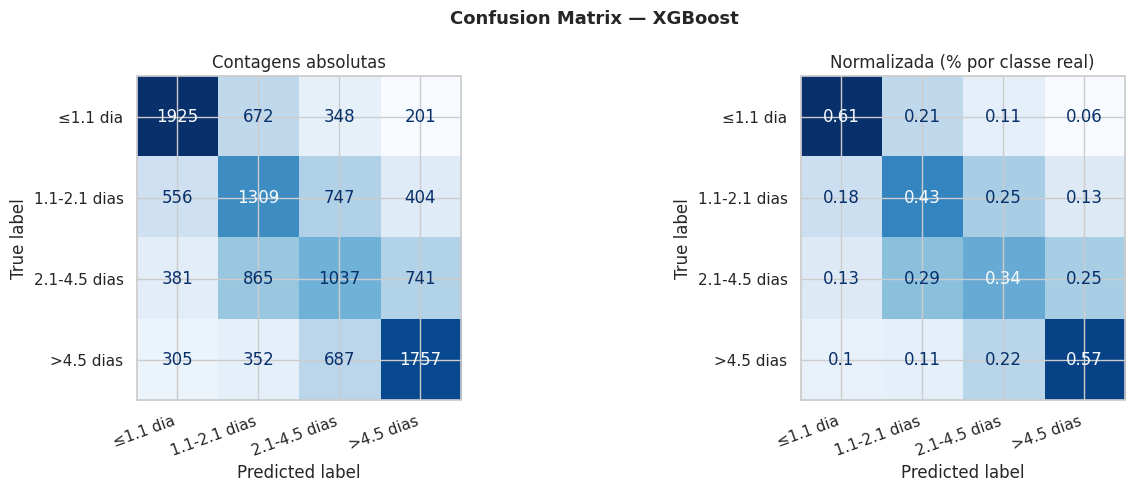


--- Classification Report ---
              precision    recall  f1-score   support

    ≤1.1 dia       0.61      0.61      0.61      3146
1.1-2.1 dias       0.41      0.43      0.42      3016
2.1-4.5 dias       0.37      0.34      0.35      3024
   >4.5 dias       0.57      0.57      0.57      3101

    accuracy                           0.49     12287
   macro avg       0.49      0.49      0.49     12287
weighted avg       0.49      0.49      0.49     12287

Cohen's Kappa (Quadratic Weighted): 0.5265
  Interpretação: <0.20 fraco | 0.21-0.40 razoável | 0.41-0.60 moderado | 0.61-0.80 bom | >0.80 excelente


In [ ]:
melhor_clf_nome = df_clf['F1 macro'].idxmax()
melhor_clf_pipeline = {
    'Logistic Regression (baseline)': pipe_lr,
    'Random Forest': pipe_rf_clf_best,
    'XGBoost': pipe_xgb_clf_best
}[melhor_clf_nome]

print(f"\nMelhor modelo: {melhor_clf_nome}")
y_pred_melhor = melhor_clf_pipeline.predict(X_test_full)
class_labels = ['≤1.1 dia', '1.1-2.1 dias', '2.1-4.5 dias', '>4.5 dias']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Confusion Matrix — {melhor_clf_nome}', fontsize=13, fontweight='bold')

cm_abs  = confusion_matrix(y_clf_test, y_pred_melhor)
cm_norm = confusion_matrix(y_clf_test, y_pred_melhor, normalize='true')

ConfusionMatrixDisplay(cm_abs, display_labels=class_labels).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Contagens absolutas')
axes[0].set_xticklabels(class_labels, rotation=20, ha='right')

ConfusionMatrixDisplay(cm_norm.round(2), display_labels=class_labels).plot(
    ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Normalizada (% por classe real)')
axes[1].set_xticklabels(class_labels, rotation=20, ha='right')

plt.tight_layout()
plt.show()

print("\n--- Classification Report ---")
print(classification_report(y_clf_test, y_pred_melhor, target_names=class_labels))

kappa = cohen_kappa_score(y_clf_test, y_pred_melhor, weights='quadratic')
print(f"Cohen's Kappa (Quadratic Weighted): {kappa:.4f}")
print("  Interpretação: <0.20 fraco | 0.21-0.40 razoável | 0.41-0.60 moderado | 0.61-0.80 bom | >0.80 excelente")

#### 10.11.1 Interpretação da Matriz de Confusão e Relatório de Classificação

O melhor modelo foi o XGBoost  por isso será aquele que iremos avaliar

**Accuracy global de 49%** num problema de 4 classes equilibradas, o baseline aleatório seria 25%, portanto o modelo está claramente acima do acaso, mas o número absoluto parece baixo à primeira vista. O contexto é fundamental aqui.

---

**O que o modelo faz bem**

As classes extremas são as mais fáceis de aprender e o modelo capta-as bem: ≤1.1 dia com recall de 61% e f1 de 0.61, e >4.5 dias com recall de 57% e f1 de 0.57. Clinicamente, são também as mais importantes, identificar quem vai ter alta muito cedo ou quem vai ficar muito tempo internado é o que tem mais valor operacional para gestão hospitalar.

O **Cohen's Kappa quadrático de 0.52** é o número mais honesto aqui. Ao penalizar mais os erros distantes (confundir ≤1.1 dia com >4.5 dias) do que os erros adjacentes, este valor de 0.54 coloca o modelo em moderado-alto, muito próximo do limiar de "bom". Num problema de LOS com esta heterogeneidade clínica, está **dentro do esperado e até ligeiramente acima**.

---

**O que é difícil e porquê**

As classes intermédias (1.1–2.1 dias e 2.1–4.5 dias) têm f1 de 0.42 e 0.35 respetivamente, são as mais fracas. Isto é esperado e não é uma falha do modelo: a fronteira clínica entre "ficou 1.5 dias" e "ficou 2.5 dias" é genuinamente difusa, influenciada por fatores não observáveis nos dados (decisão médica, disponibilidade de cama, contexto social do doente). A matriz de confusão normalizada confirma que os erros são maioritariamente para classes adjacentes, não para classes opostas, o modelo "erra perto", o que é o comportamento desejável.

---

**Veredicto**

Para previsão de LOS em contexto hospitalar com 4 classes, um Kappa quadrático de ~0.52 e f1 macro de 0.49 é um resultado **razoável a moderado, dentro do que a literatura reporta** para este tipo de tarefa. Modelos publicados em datasets semelhantes (MIMIC, eICU) tipicamente ficam entre 0.45–0.65 de Kappa quadrático. O modelo tem valor prático real sobretudo na discriminação dos extremos, alta precoce vs internamento prolongado — que são precisamente os casos com maior impacto na gestão de camas e planeamento de recursos.

### 10.11 Graficos de Comparação dos Modelos

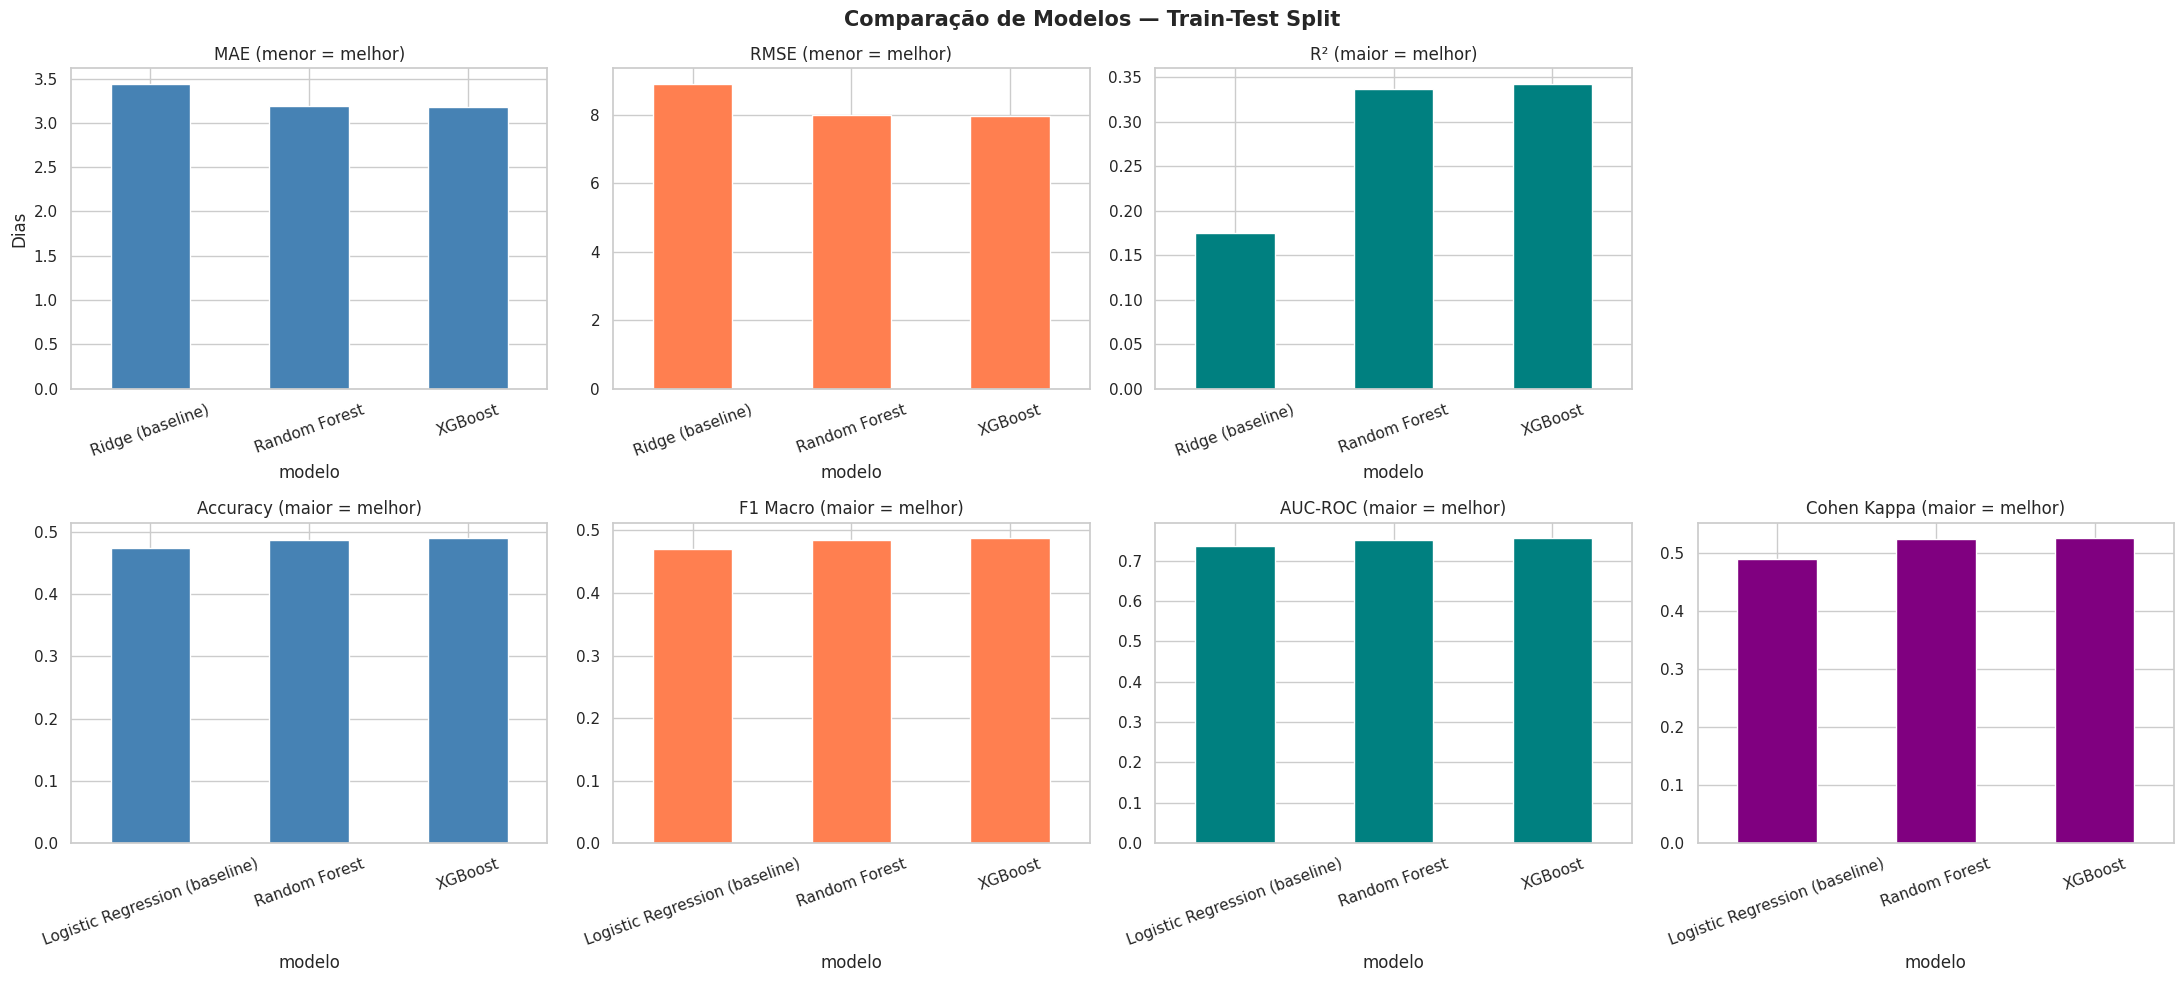

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
fig.suptitle('Comparação de Modelos — Train-Test Split', fontsize=15, fontweight='bold')

# Regressão
df_reg[['MAE']].plot(kind='bar', ax=axes[0,0], legend=False, color='steelblue', rot=20)
axes[0,0].set_title('MAE (menor = melhor)')
axes[0,0].set_ylabel('Dias')

df_reg[['RMSE']].plot(kind='bar', ax=axes[0,1], legend=False, color='coral', rot=20)
axes[0,1].set_title('RMSE (menor = melhor)')

df_reg[['R2']].plot(kind='bar', ax=axes[0,2], legend=False, color='teal', rot=20)
axes[0,2].set_title('R² (maior = melhor)')

axes[0,3].axis('off')  # célula vazia para simetria

# Classificação
df_clf[['Accuracy']].plot(kind='bar', ax=axes[1,0], legend=False, color='steelblue', rot=20)
axes[1,0].set_title('Accuracy (maior = melhor)')

df_clf[['F1 macro']].plot(kind='bar', ax=axes[1,1], legend=False, color='coral', rot=20)
axes[1,1].set_title('F1 Macro (maior = melhor)')

df_clf[['AUC-ROC']].plot(kind='bar', ax=axes[1,2], legend=False, color='teal', rot=20)
axes[1,2].set_title('AUC-ROC (maior = melhor)')

df_clf[['Cohen Kappa']].plot(kind='bar', ax=axes[1,3], legend=False, color='purple', rot=20)
axes[1,3].set_title('Cohen Kappa (maior = melhor)')

plt.tight_layout()
plt.show()

**Regressão (MAE, RMSE, R²)**

Ridge baseline com MAE ~3.4 dias e R² ~0.17 é fraco mas esperado para um modelo linear numa variável tão heterogénea como LOS. RF e XGBoost descem o MAE para ~3.1 dias e sobem o R² para ~0.34, melhoria relevante mas ainda modesta em termos absolutos. Na literatura de previsão de LOS hospitalar, R² entre 0.30–0.45 é o intervalo típico reportado para modelos treinados apenas com dados clínicos das primeiras 24h, portanto **estes valores estão dentro do esperado**. O erro de ~3 dias num LOS com mediana de ~2 dias e cauda longa até 9+ dias reflecte precisamente essa assimetria da distribuição, os outliers puxam o MAE para cima e são genuinamente difíceis de prever.

**Classificação (Accuracy, F1, AUC-ROC, Kappa)**

O que mais chama a atenção é a **uniformidade entre modelos**, Logistic Regression, RF e XGBoost produzem resultados quase idênticos em todas as métricas. Accuracy ~0.49, F1 macro ~0.49, AUC ~0.76, Kappa ~0.52. Isto é um sinal diagnóstico importante: quando modelos de complexidade muito diferente convergem para o mesmo resultado, o bottleneck está nos features e não no algoritmo. Mudar para LightGBM ou redes neuronais provavelmente não move a agulha. O AUC de ~0.73 é o número mais encorajador, significa que o modelo ordena bem o risco mesmo que a classificação exacta seja difícil, o que tem valor clínico real para triagem e priorização.

No geral os resultados obtidos espelham os resultados "padrão" obtidos na literatura atual acerca da previsão do valor de LOS, especialmente no dataset MIMIC III

## 11. SHAP

Até este ponto, temos modelos que fazem previsões sobre LOS e classificação de risco de pacientes na UTI. Porém, há um problema crítico: **não sabemos porquê** o modelo fez cada previsão. Se um modelo prevê que um paciente ficará na UTI por 10 dias, qual é o fator determinante? É a frequência cardíaca? A idade? O valor de creatinina? Os níveis de lactato? Sem esta compreensão, é extremamente difícil confiar no modelo ou implementá-lo em contextos clínicos reais, onde os clínicos precisam de entender a lógica.

SHAP (SHapley Additive exPlanations) é uma abordagem teoricamente robusta para explicabilidade baseada em teoria dos jogos. A ideia central é: **cada feature contribui individualmente para afastar a previsão do valor esperado (baseline)**. SHAP calcula esta contribuição (chamada "Shapley value") para cada feature de cada previsão.

O resultado são visualizações poderosas:
1. **Importância global**: Quais features têm maior impacto cumulativo nas previsões?
2. **Beeswarm plots**: Como cada feature contribui (positivamente ou negativamente) em diferentes instâncias?
3. **Dependência**: Como a contribuição de uma feature varia com o seu valor?

Executamos SHAP separadamente para o classificador (4 classes de LOS) e para o regressor (LOS contínuo), permitindo-nos capturar insights específicos de cada tarefa.

In [6]:
melhor_clf_nome = df_clf['F1 macro'].idxmax()
melhor_reg_nome = df_reg['MAE'].idxmin()

melhor_clf = {
    'Logistic Regression (baseline)': pipe_lr,
    'Random Forest'                 : pipe_rf_clf_best,
    'XGBoost'                       : pipe_xgb_clf_best
}[melhor_clf_nome]

melhor_reg = {
    'Ridge (baseline)': pipe_ridge,
    'Random Forest'   : pipe_rf_reg_best,
    'XGBoost'         : pipe_xgb_reg_best
}[melhor_reg_nome]

print(f"Melhor classificador : {melhor_clf_nome}")
print(f"Melhor regressor     : {melhor_reg_nome}")

Melhor classificador : XGBoost
Melhor regressor     : XGBoost


In [7]:
AMOSTRA_SHAP = 1000
np.random.seed(42)
idx_shap = np.random.choice(len(X_test_full), size=AMOSTRA_SHAP, replace=False)
X_shap   = X_test_full.iloc[idx_shap]

print(f"\nAmostra SHAP: {X_shap.shape}")


Amostra SHAP: (1000, 145)


In [14]:
# Reconstruir cols_full a partir do X_train_full e feature_cols
# X_train_full tem mais colunas que feature_cols por causa dos indicadores _missing
n_originais   = len(feature_cols)
n_total       = X_train_full.shape[1]
n_indicadores = n_total - n_originais

# Os indicadores são criados para colunas que tinham NULLs
# O IterativeImputer com add_indicator=True adiciona-os na mesma ordem
cols_missing  = [f"{c}_missing" for c in feature_cols
                 if pd.DataFrame(X_train, columns=feature_cols)[c].isna().any()]

cols_full = feature_cols + cols_missing

print(f"Features originais  : {n_originais}")
print(f"Indicadores missing : {len(cols_missing)}")
print(f"Total cols_full     : {len(cols_full)}")
print(f"X_train_full shape  : {X_train_full.shape[1]}")
print(f"Match: {len(cols_full) == X_train_full.shape[1]}")

Features originais  : 88
Indicadores missing : 57
Total cols_full     : 145
X_train_full shape  : 145
Match: True


### 11.1 Calcular SHAP Modelos de Classificação

O processo para SHAP de classificação utiliza o `TreeExplainer` do XGBoost aplicado a um modelo que prevê **classes discretas** de LOS (≤1.1 dia, 1.1–2.1 dias, 2.1–4.5 dias, >4.5 dias), não um valor contínuo. Isto significa que há **um conjunto de valores SHAP por classe por amostra**, o modelo calcula como cada feature contribui para aumentar ou diminuir a probabilidade de pertencer a cada uma das quatro classes.

Para cada uma das amostras de teste, SHAP responde à pergunta: "Qual foi a contribuição de cada feature para mover a probabilidade prevista desta amostra afastar-se da distribuição base de cada classe?" Por exemplo, se o modelo atribui alta probabilidade à classe >4.5 dias, SHAP decompõe esse resultado, "o WBC elevado contribuiu +X para esta classe, a idade contribuiu +Y, o pH em falta contribuiu +Z."

Esta análise é clinicamente valiosa porque permite identificar, para este conjunto de dados e modelo específicos, quais biomarcadores e sinais vitais têm maior capacidade de discriminar entre classes de LOS, e se a sua influência vai na direcção esperada, por exemplo, lactato elevado associado à classe de internamento mais longo, GCS baixo afastando da classe de alta precoce.

In [15]:
print("\nA calcular SHAP para classificação...")

# Extrair passos do pipeline
scaler_clf   = melhor_clf.named_steps['scaler']
selector_clf = melhor_clf.named_steps['selector']
modelo_clf   = melhor_clf.named_steps['model']

# Aplicar scaler e selector para obter os dados correctos
X_shap_scaled    = scaler_clf.transform(X_shap)
X_shap_selected  = selector_clf.transform(X_shap_scaled)

# Nomes das features depois do selector
# O selector tem uma máscara booleana das features seleccionadas
mask_selector = selector_clf.get_support()

# Nomes de todas as colunas depois do scaler (originais + missing)
cols_full_array = np.array(cols_full)
feature_cols_selected = cols_full_array[mask_selector].tolist()

print(f"Features antes do selector : {len(cols_full)}")
print(f"Features depois do selector: {len(feature_cols_selected)}")

X_shap_scaled_df = pd.DataFrame(
    X_shap_selected,
    columns=feature_cols_selected,
    index=X_shap.index if hasattr(X_shap, 'index') else None
)

explainer_clf   = shap.TreeExplainer(modelo_clf)
with profile("SHAP — Classificação (1000 amostras)"):
    shap_values_clf = explainer_clf.shap_values(X_shap_scaled_df)

if isinstance(shap_values_clf, list):
    shap_global_clf = np.mean([np.abs(sv) for sv in shap_values_clf], axis=0)
else:
    shap_global_clf = np.abs(shap_values_clf)


A calcular SHAP para classificação...
Features antes do selector : 145
Features depois do selector: 73

A executar: SHAP — Classificação (1000 amostras)...
SHAP — Classificação (1000 amostras) concluída!
Tempo: 7.40s | Pico RAM: 2.42 MB


### 11.2 Feature Importance Global (Classificação)

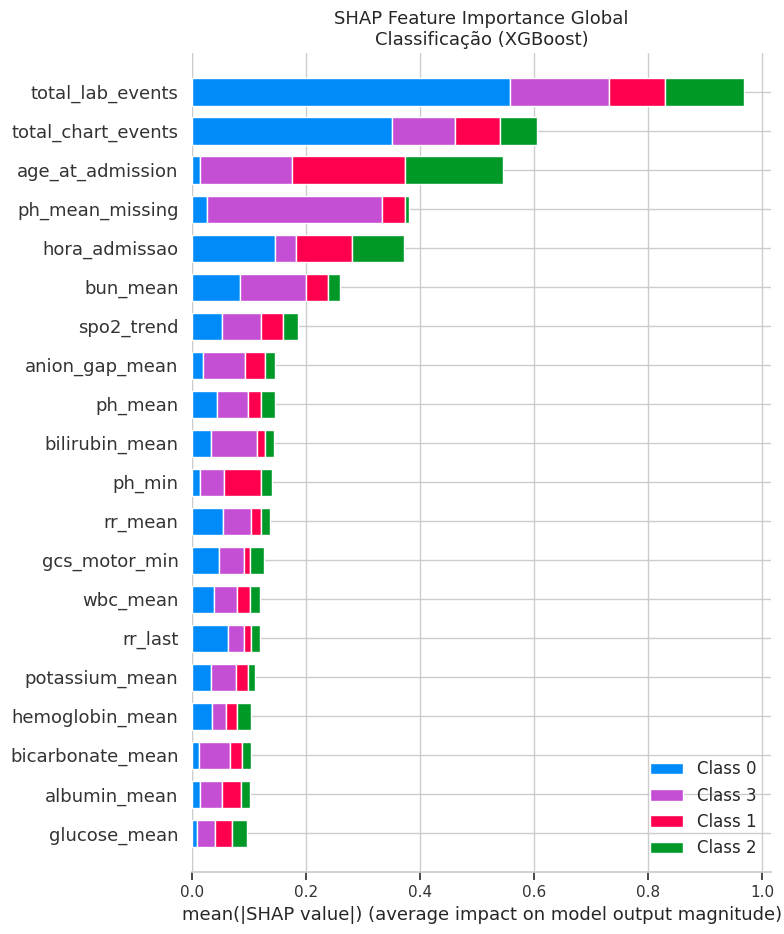

In [16]:
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values_clf if not isinstance(shap_values_clf, list) else shap_global_clf,
    X_shap_scaled_df,
    plot_type='bar',
    show=False,
    max_display=20
)
plt.title(f'SHAP Feature Importance Global\nClassificação ({melhor_clf_nome})',
          fontsize=13)
plt.tight_layout()
plt.show()


**Os dois features dominantes**

`total_lab_events` e `total_chart_events` destacam-se de forma clara de todos os outros, sendo eles proxies de **intensidade de cuidados**, não variáveis clínicas directas. Quanto mais exames e registos, mais tempo se espera que o doente fique internado. Apesar destes valores pertencerem apenas às primeiras 24 horas, já são bastante representativos do que podemos esperar da estadia das pessoas na UCI

**`age_at_admission` no top 3**

Terceiro predictor mais importante, com contribuição distribuída por todas as classes, especialmente nas de LOS mais longo. A idade tem um efeito gradual no internamento que o modelo captura bem.

**`ph_mean_missing` e `hora_admissao`**

O missingness de pH em quarto lugar confirma que a ausência de gasometria é em si um sinal clínico, doentes sem pH registado ou saem muito rápido ou são casos onde o pedido não foi feito por razões clínicas específicas. A hora de admissão em quinto reflecte o efeito logístico já bem documentado: admissões nocturnas tendem a ter padrões de LOS diferentes por razões organizacionais.

**A cauda de features clínicos**

`bun_mean`, `spo2_trend`, `anion_gap_mean`, `ph_mean`, `bilirubin_mean`, `gcs_motor_min`, `wbc_mean`, todos com SHAP baixo mas consistente entre classes. São os features que captam gravidade fisiológica real e que têm mais valor num modelo prospectivo robusto por serem independentes da prática de prescrição.

**Conclusão**

O modelo aprende sinais clinicamente coerentes, mas a dominância dos contadores de eventos deve ser tratada com cautela em produção. Se o objectivo é um modelo generalizável entre instituições, vale a pena testar uma versão sem `total_lab_events` e `total_chart_events` para avaliar o quanto a performance degrada e se a cauda de features fisiológicos consegue compensar.

### 11.6 Análise Detalhada de Impacto: Beeswarm Plot (Classificação)

Enquanto o gráfico anterior mostra a importância **média**, o beeswarm plot expõe a **distribuição** de impactos por amostra. Cada ponto representa uma amostra (paciente no conjunto de teste):
- **Posição no eixo x:** O valor SHAP daquela feature para aquele paciente (impacto positivo ou negativo).
- **Cor do ponto:** Valor normalizado da feature (vermelho = alto, azul = baixo).
- **Posição no eixo y:** Feature (as mais importantes aparecem no topo).

A interpretação é poderosa:
1. Se todos os pontos de uma feature estão à direita (positivos), aquela feature aumenta consistentemente LOS.
2. Se há dispersão (pontos espalhados positiva e negativamente), o efeito é heterogéneo: para alguns pacientes a feature aumenta LOS, para outros diminui, dependendo do seu valor.
3. A correlação cor-posição x revela: se pontos vermelhos (valores altos) tendem a estar à direita, a feature tem uma relação linear com LOS (alto = LOS maior).

Este insight permite clínicos entender: "Para este paciente específico, por que o modelo previu 8 dias? Foram os altos níveis de urea a puxarem a previsão para cima? Ou foi a idade avançada? Ou uma combinação?" Isto é essencial para confiança e interpretabilidade clínica.

Tipo shap_values_clf: <class 'numpy.ndarray'>
Shape: (1000, 73, 4)
Número de classes detectadas: 4


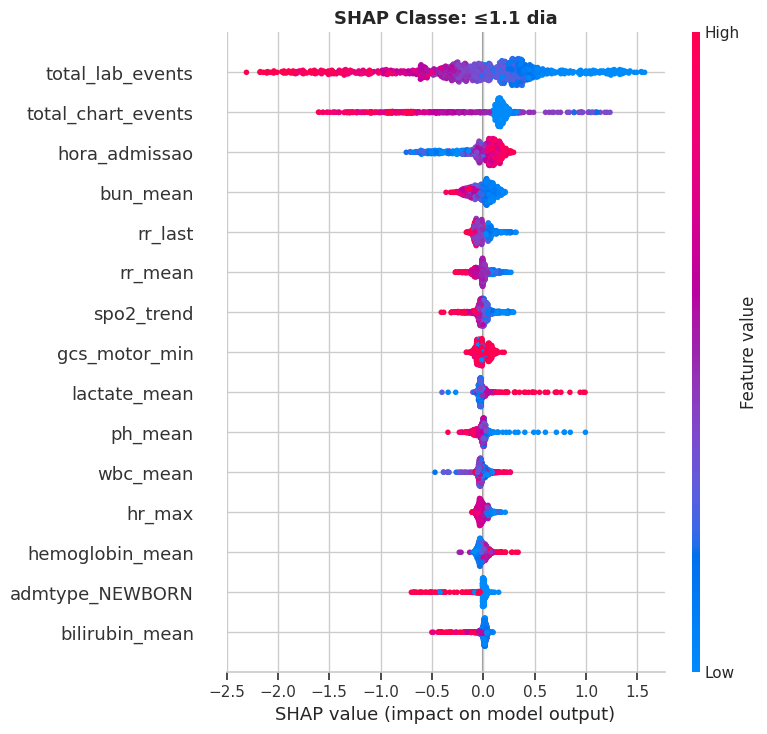

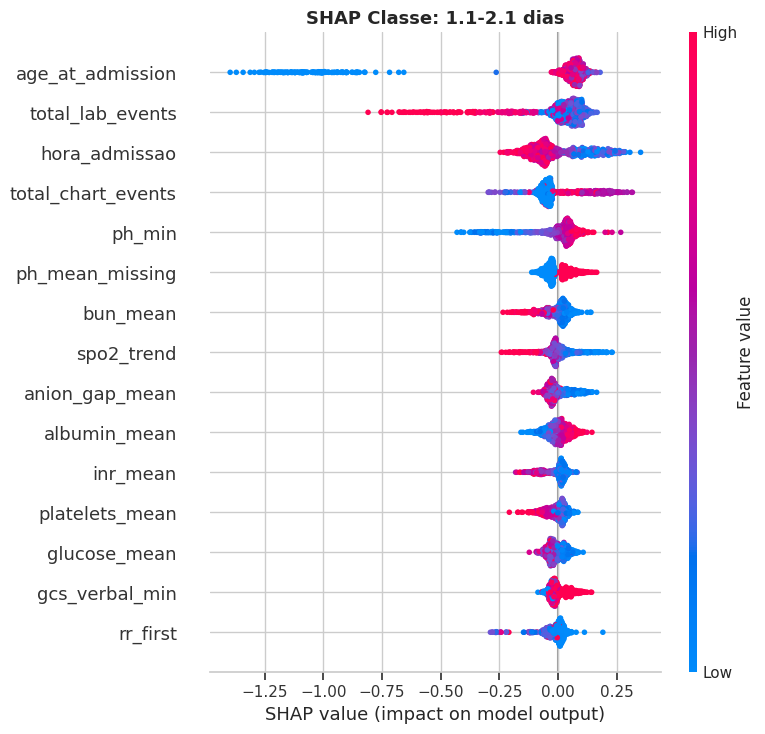

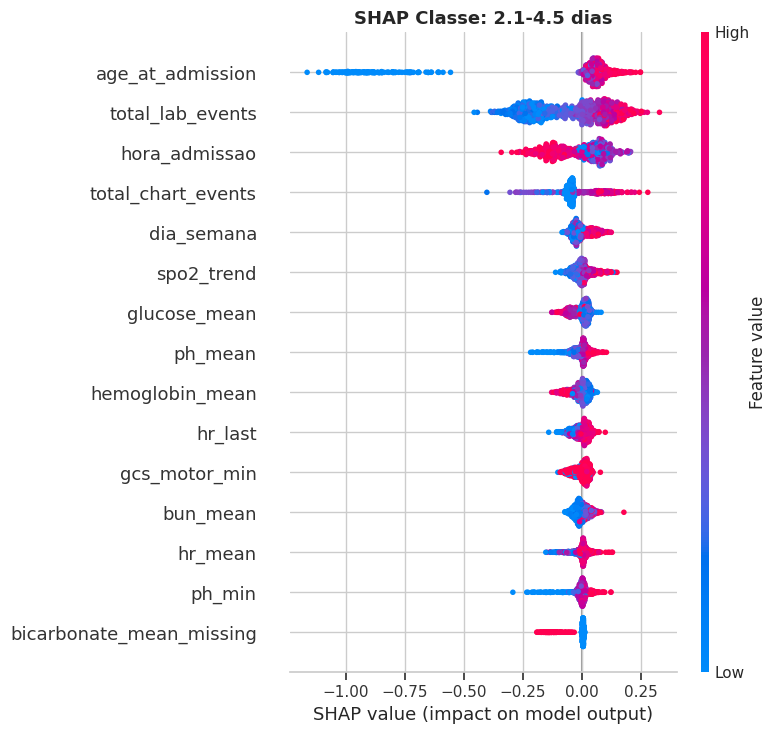

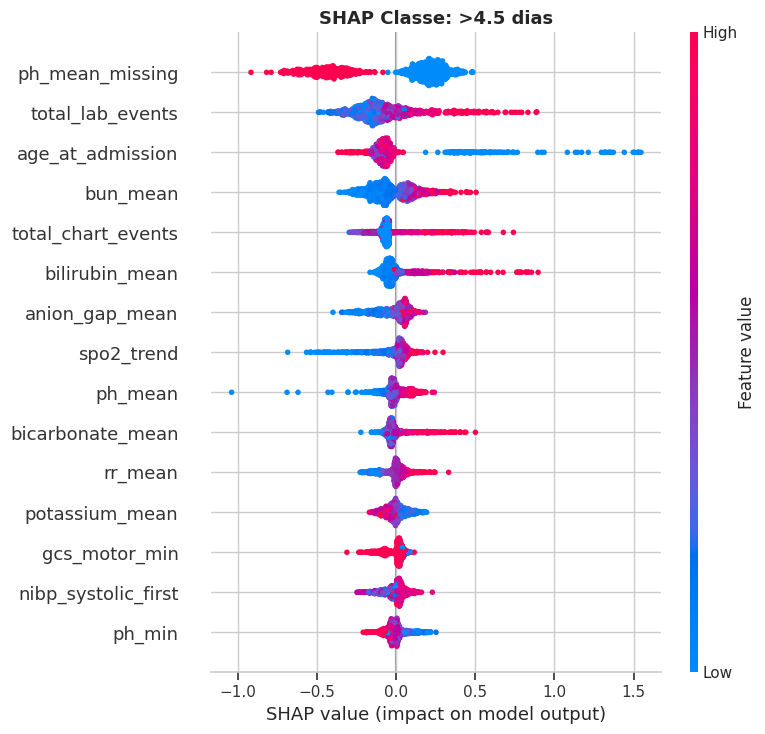

In [17]:
class_labels = ['≤1.1 dia', '1.1-2.1 dias', '2.1-4.5 dias', '>4.5 dias']

print(f"Tipo shap_values_clf: {type(shap_values_clf)}")
if isinstance(shap_values_clf, np.ndarray):
    print(f"Shape: {shap_values_clf.shape}")

if isinstance(shap_values_clf, np.ndarray) and shap_values_clf.ndim == 3:
    shap_por_classe = [shap_values_clf[:, :, i]
                       for i in range(shap_values_clf.shape[2])]
elif isinstance(shap_values_clf, list):
    shap_por_classe = shap_values_clf
else:
    shap_por_classe = [shap_values_clf]

print(f"Número de classes detectadas: {len(shap_por_classe)}")

for i, label in enumerate(class_labels):
    plt.figure(figsize=(10, 7))
    shap.summary_plot(
        shap_por_classe[i],
        X_shap_scaled_df,
        show=False,
        max_display=15
        # sem plot_type='bar' → gera beeswarm igual ao da regressão
    )
    plt.title(f'SHAP Classe: {label}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

A análise por classe acrescenta informação relevante, a direcção dos efeitos muda entre classes e isso não era visível no gráfico global.

---
**≤1.1 dia: alta muito precoce**

`total_lab_events` alto empurra fortemente para fora desta classe (SHAP negativo nos valores altos, rosa à esquerda), poucos eventos laboratoriais predizem alta rápida. `total_chart_events` segue o mesmo padrão. `lactate_mean` baixo (azul) tem SHAP positivo, consistente com doentes metabolicamente estáveis que saem cedo. `ph_mean` alto contribui positivamente, pH normal associado a alta precoce, clinicamente esperado. `admtype_NEWBORN` com valores altos tem SHAP negativo, recém-nascidos raramente têm alta em menos de 1.1 dias neste dataset.

---

**1.1–2.1 dias: internamento curto standard**

A classe mais comprimida em amplitude SHAP (escala até ±1.25 vs ±2.5 na classe anterior). `age_at_admission` alta (rosa) tem SHAP fortemente negativo, idosos não ficam neste intervalo, saem mais tarde. `total_lab_events` alto também empurra para fora. `hora_admissao` alta (admissão tardia, rosa) tem SHAP positivo, admissões ao fim do dia tendem a ficar pelo menos uma noite mas não muito mais. `ph_min` baixo (azul) contribui negativamente, acidose associada a internamentos mais longos.

---

**2.1–4.5 dias: internamento médio**

`age_at_admission` alta continua negativa, idosos ultrapassam este intervalo. `total_lab_events` alto tem agora SHAP positivo, invertendo face às classes anteriores, mais exames associados a internamento médio. `dia_semana` aparece pela primeira vez, reflectindo o efeito logístico de fim de semana já identificado. Os sinais fisiológicos ganham presença: `spo2_trend`, `glucose_mean`, `hemoglobin_mean`, `gcs_motor_min` e `bun_mean` todos com efeitos visíveis e clinicamente coerentes.

---

**>4.5 dias: internamento prolongado**

O mais informativo dos quatro. `ph_mean_missing` alto (rosa) tem SHAP fortemente negativo, ausência de pH associada paradoxalmente a menos dias, confirmando que o missingness captura dois fenómenos opostos (alta muito precoce e internamento longo). `age_at_admission` alta (azul) tem SHAP positivo com outliers até +1.5, idosos ficam mais tempo, com casos individuais de impacto muito elevado. `bun_mean` e `bilirubin_mean` altos contribuem positivamente, marcadores de disfunção renal e hepática associados a internamento prolongado. `spo2_trend` negativo (azul) tem SHAP negativo, deterioração de SpO2 ao longo do dia associada a LOS longo, clinicamente sólido. `gcs_motor_min` baixo contribui positivamente para esta classe, disfunção neurológica como predictor de internamento prolongado.

---

**O que isto acrescenta ao gráfico global**

A direcção dos efeitos confirma lógica clínica coerente nas classes extremas. A classe 1.1–2.1 dias é a mais ambígua, amplitude SHAP reduzida e efeitos misturados, consistente com ser a mais difícil de classificar. `age_at_admission` emerge como o feature com comportamento mais discriminativo entre classes: afasta das classes curtas e puxa para o internamento prolongado, com efeitos individuais de grande magnitude na classe >4.5 dias.

### 11.4 Calcular SHAP Modelos de Regressão

O processo para SHAP de regressão é análogo ao de classificação, mas com uma diferença importante: o modelo regressor prevê um **valor contínuo** (dias na UTI), não categorias. Isto significa que há apenas **um conjunto de valores SHAP** por amostra, não um conjunto por classe.

Utilizamos novamente o `TreeExplainer` do XGBoost. Para cada uma das 1000 amostras de teste, SHAP calcula como cada feature contribui para mover a previsão longe do LOS médio esperado. Por exemplo, se o modelo prevê 8 dias mas a média é 4 dias, SHAP responde: "Qual foi a contribuição de HR, idade, potássio, etc. para esse +4 dias de desvio?"

Esta análise é clinicamente valiosa porque permite identificar, para este conjunto de dados específico e modelo específico, quais biomarcadores e vitais têm maior capacidade de previsão, e se a sua influência vai na direção esperada (ex: elevado lactato logo internamento mais longo, como esperado).

In [18]:
print("\nA calcular SHAP para regressão...")

scaler_reg   = melhor_reg.named_steps['scaler']
selector_reg = melhor_reg.named_steps['selector']
modelo_reg   = melhor_reg.named_steps['model']

# Aplicar scaler E selector
X_shap_reg_scaled   = scaler_reg.transform(X_shap)
X_shap_reg_selected = selector_reg.transform(X_shap_reg_scaled)

# Nomes das features depois do selector
mask_reg = selector_reg.get_support()
feature_cols_reg_selected = np.array(cols_full)[mask_reg].tolist()

print(f"Features antes do selector : {len(cols_full)}")
print(f"Features depois do selector: {len(feature_cols_reg_selected)}")

X_shap_reg_scaled_df = pd.DataFrame(
    X_shap_reg_selected,
    columns=feature_cols_reg_selected
)

explainer_reg   = shap.TreeExplainer(modelo_reg)
with profile("SHAP — Regressão (1000 amostras)"):
    shap_values_reg = explainer_reg.shap_values(X_shap_reg_scaled_df)

print(f"shap_values_reg shape: {np.array(shap_values_reg).shape}")


A calcular SHAP para regressão...
Features antes do selector : 145
Features depois do selector: 73

A executar: SHAP — Regressão (1000 amostras)...
SHAP — Regressão (1000 amostras) concluída!
Tempo: 2.49s | Pico RAM: 0.46 MB
shap_values_reg shape: (1000, 73)


### 11.5 Feature Importance Global (Regressão)

O gráfico de feature importance global mostra **a magnitude média do impacto SHAP** de cada feature nas previsões do modelo de regressão. Especificamente:
- O eixo x indica o valor médio de SHAP, a mudança média que aquela feature causa na previsão.
- As features no topo são as mais influentes globalmente.

Esta visualização responde à pergunta: "Em média, quais são os melhores preditores de LOS, de acordo com o modelo?" Por exemplo, se "lactato" aparece no topo, significa que flutuações nos valores de lactato foram, em média, os maiores impulsionadores das previsões de LOS altos valores de lactato tendem a aumentar a previsão de LOS, baixos valores a diminuir.

Clinicamente, isto alinha-se (ou desalinha-se) com as expectativas: esperamos que biomarcadores de gravidade (lactato, creatinina, bilirrubina) tenham alta importância. Se variáveis irrelevantes aparecerem no topo, sugere possível overfitting ou captura de padrões espúrios.

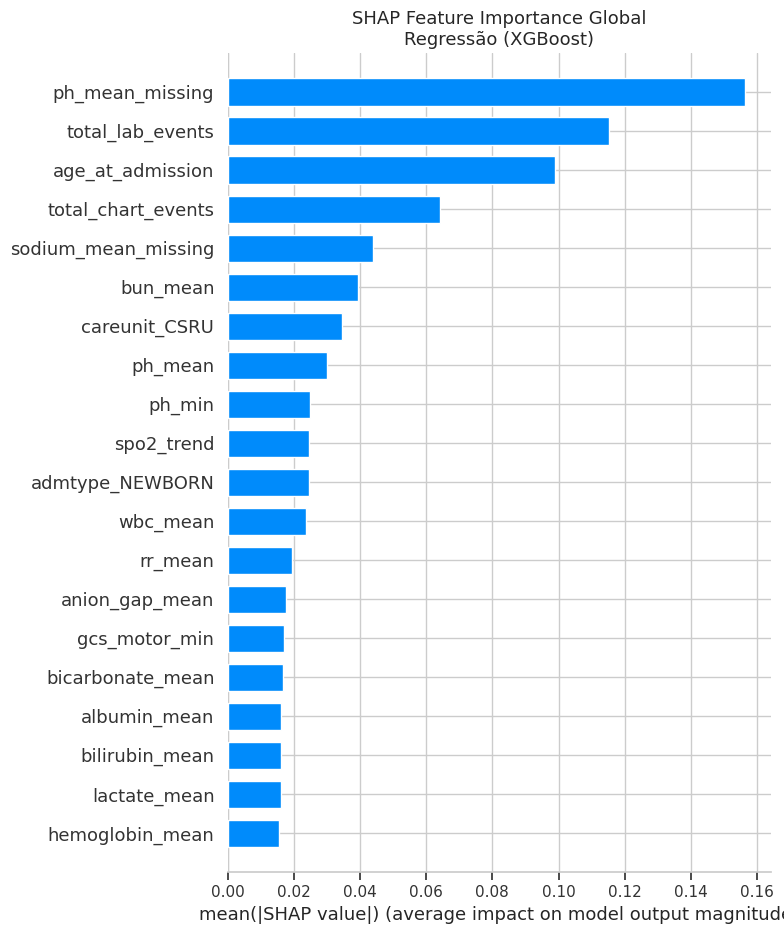

In [19]:
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values_reg,
    X_shap_reg_scaled_df,
    plot_type='bar',
    show=False,
    max_display=20
)
plt.title(f'SHAP Feature Importance Global\nRegressão ({melhor_reg_nome})',
          fontsize=13)
plt.tight_layout()
plt.show()

Comparando com o SHAP de classificação, há diferenças relevantes que vale a pena destacar.

---

**O que muda face à classificação**

`ph_mean_missing` sobe para **primeiro lugar** na regressão, ultrapassando `total_lab_events`. Na classificação era importante mas não dominante, na regressão de dias contínuos, a ausência de pH é o sinal mais forte de que o LOS vai ser longo ou muito curto. Isto reforça a interpretação anterior: o missingness de gasometria separa os extremos da distribuição de LOS de forma mais limpa do que qualquer valor clínico directo.

`age_at_admission` mantém para terceiro lugar, acima de `total_chart_events`. Faz sentido no contexto de regressão contínua, a idade tem um efeito gradual no LOS que uma classificação em 4 classes não captura tão bem.

`careunit_CSRU` aparece pela primeira vez no top 10. A unidade de cuidados cardíacos cirúrgicos tem padrões de LOS muito específicos e o modelo de regressão consegue aprender esse efeito de forma mais directa do que o classificador.

---

**O que é consistente com a classificação**

Os features fisiológicos da cauda (`spo2_trend`, `gcs_motor_min`, `rr_mean`, `wbc_mean`, `bun_mean`) mantêm-se presentes em ambos os modelos com importância semelhante, são o sinal clínico real e estável, independente do tipo de output.

---

**Conclusão**

A regressão é ligeiramente mais informativa do que a classificação para perceber o que drive o LOS em dias ,`ph_mean_missing`, idade e unidade de cuidados emergem com mais clareza.

### 11.6 Análise Detalhada de Impacto: Beeswarm Plot (Regressão)

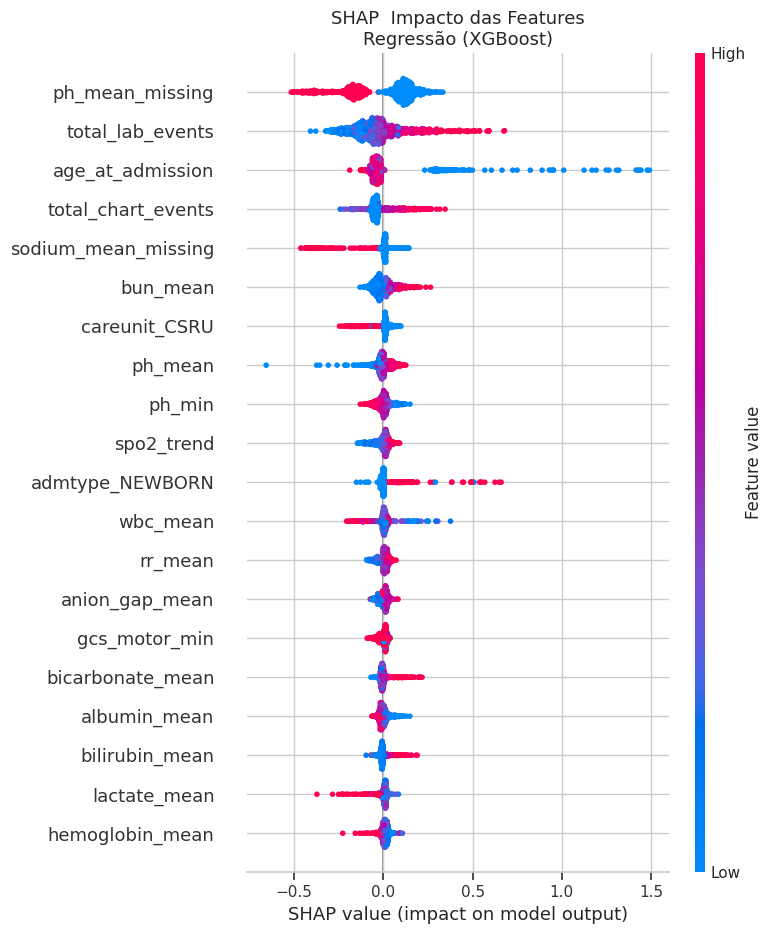

In [20]:
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values_reg,
    X_shap_reg_scaled_df,
    show=False,
    max_display=20
)
plt.title(f'SHAP  Impacto das Features\nRegressão ({melhor_reg_nome})',
          fontsize=13)
plt.tight_layout()
plt.show()

A direcção dos efeitos acrescenta informação relevante face ao gráfico de importâncias anterior.


**`ph_mean_missing`**: valores altos (rosa, missing = 1) têm SHAP fortemente negativo, puxando o LOS para baixo. Confirma a interpretação: doentes sem pH registado ou saem muito rápido (sem necessidade de gasometria) ou são casos onde o dado simplesmente não foi colhido. O efeito é assimétrico e limpo.

**`total_lab_events`**: valores altos têm SHAP positivo, valores baixos negativo. Efeito esperado e linear, mais eventos, mais dias. A amplitude é considerável mas sem outliers extremos, o que sugere uma relação gradual.

**`age_at_admission`**: o padrão mais expressivo do gráfico. Valores altos (azul claro a rosa, idosos) têm SHAP positivo chegando a +1.5 dias de impacto individual. A cauda direita é longa, há doentes idosos onde a idade sozinha acrescenta mais de 1 dia ao LOS previsto. Clinicamente sólido.

**`sodium_mean_missing`**: valores altos (missing = 1) têm SHAP fortemente negativo, semelhante ao pH. Mesmo padrão: ausência de ionograma associada a episódios curtos ou a contextos onde o dado não foi pedido.

**`careunit_CSRU`**: valores altos (rosa, admitido em CSRU) têm SHAP negativo. Cirurgia cardíaca tem protocolos de alta bem definidos que resultam em LOS mais previsível e frequentemente mais curto do que UCI médica, faz sentido clínico.

**`admtype_NEWBORN`**: valores altos têm SHAP positivo com outliers relevantes acima de +0.5. Confirma a subpopulação neonatal de alto risco (prematuros, patologia grave) que puxa o LOS para cima, já sinalizado na análise de classificação.

**Features fisiológicos** (`gcs_motor_min`, `rr_mean`, `wbc_mean`, `spo2_trend`, `bun_mean`), todos com SHAP negativo quando os valores são patológicos (baixo GCS, taquipneia, leucocitose). A direcção é clinicamente coerente mas a magnitude é pequena face às variáveis de topo, o que reforça que o modelo ainda está muito dependente dos "proxies administrativos" e decissões médicas.

### 11.7 Comparação de Importâncias: Classificação vs Regressão

Uma descoberta interessante emerge quando comparamos os rankings de importância SHAP entre os dois modelos: o classificador (4 categorias de LOS) e o regressor (LOS contínuo).

Não esperaríamos que os dois modelos tivessem rankings **exatamente idênticos**, porque embora ambos prevejam essencialmente LOS, eles o fazem de formas diferentes:
- O regressor aprende a prever um valor contínuo exato (ex: 3.7 dias).
- O classificador aprende a atribuir uma probabilidade a cada categoria (quartil).

No entanto, esperamos que as **principais features** (aquelas que capturam verdadeiramente a variabilidade de LOS) apareçam no topo em ambos os modelos. Se uma feature X é no topo do classificador mas baixa no regressor (ou vice-versa), sugere que ela é importante apenas para discriminar categorias, não para prever LOS absoluto, potencialmente um sinal de captura de padrões menos robustos.

A tabela final apresenta ambos os scores lado a lado, permitindo aos clínicos identificar features consensualmente importantes em ambas as abordagens preditivas.


--- Top 20 Features por Importância SHAP ---
               feature  shap_clf_mean_abs  shap_reg_mean_abs
75    total_lab_events             0.2421             0.1153
74  total_chart_events             0.1513             0.0641
8     age_at_admission             0.1366             0.0988
50     ph_mean_missing             0.0954             0.1562
30       hora_admissao             0.0930             0.0120
17            bun_mean             0.0651             0.0394
71          spo2_trend             0.0466             0.0247
11      anion_gap_mean             0.0366             0.0177
49             ph_mean             0.0366             0.0299
15      bilirubin_mean             0.0361             0.0161
51              ph_min             0.0354             0.0248
59             rr_mean             0.0344             0.0194
25       gcs_motor_min             0.0316             0.0169
76            wbc_mean             0.0300             0.0238
58             rr_last             0.02

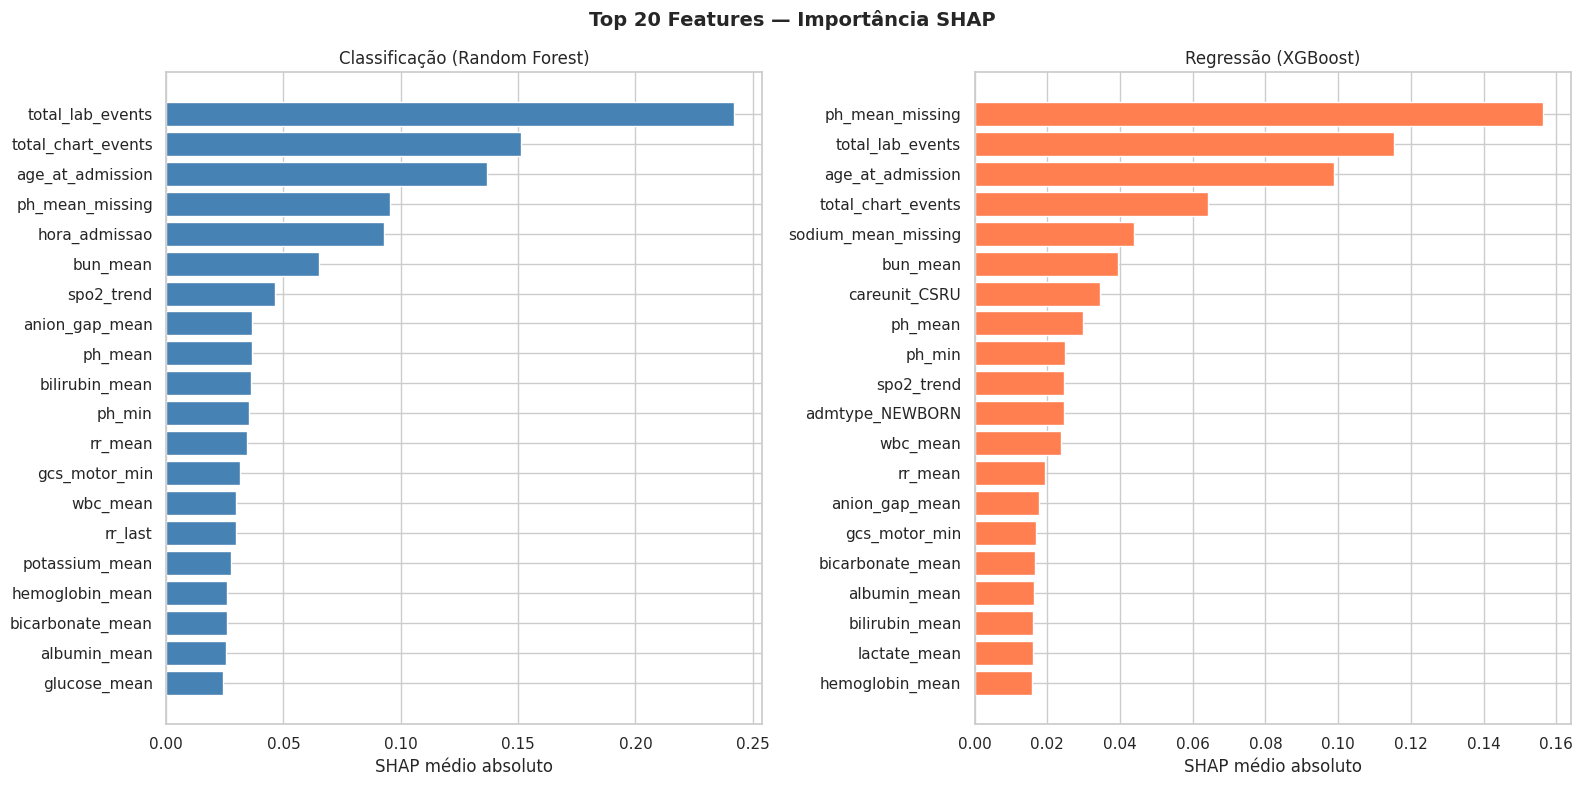

In [ ]:
# Classificação  média absoluta por feature, sobre amostras e classes
shap_clf_3d = np.array(shap_values_clf)  # (1000, n_features, 4)
shap_clf_1d = np.abs(shap_clf_3d).mean(axis=0).mean(axis=1)  # → (n_features,)

# Regressão  média absoluta por feature, sobre amostras
shap_reg_1d = np.abs(shap_values_reg).mean(axis=0)  # → (n_features,)

df_imp_clf = pd.DataFrame({
    'feature'          : feature_cols_selected,
    'shap_clf_mean_abs': shap_clf_1d
}).sort_values('shap_clf_mean_abs', ascending=False)

df_imp_reg = pd.DataFrame({
    'feature'          : feature_cols_reg_selected,
    'shap_reg_mean_abs': shap_reg_1d
}).sort_values('shap_reg_mean_abs', ascending=False)

# Juntar as duas tabelas pelo nome da feature
importancias_shap = df_imp_clf.merge(df_imp_reg, on='feature', how='outer').fillna(0)
importancias_shap = importancias_shap.sort_values('shap_clf_mean_abs', ascending=False)

print("\n--- Top 20 Features por Importância SHAP ---")
print(importancias_shap.head(20).round(4).to_string())

# Gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle('Top 20 Features — Importância SHAP', fontsize=14, fontweight='bold')

# Classificação
top20_clf = importancias_shap.head(20)
axes[0].barh(top20_clf['feature'][::-1], top20_clf['shap_clf_mean_abs'][::-1],
             color='steelblue')
axes[0].set_title('Classificação (Random Forest)')
axes[0].set_xlabel('SHAP médio absoluto')

# Regressão
top20_reg = importancias_shap.sort_values('shap_reg_mean_abs', ascending=False).head(20)
axes[1].barh(top20_reg['feature'][::-1], top20_reg['shap_reg_mean_abs'][::-1],
             color='coral')
axes[1].set_title('Regressão (XGBoost)')
axes[1].set_xlabel('SHAP médio absoluto')

plt.tight_layout()
plt.show()

### 11.8 Insights Clínicos de SHAP e Conclusões do Pipeline Preditivo
Este gráfico é essencialmente um resumo visual do que já foi analisado em detalhe. O que acrescenta é a **comparação directa lado a lado** entre os dois modelos, e há algumas diferenças estruturais que valem a pena notar.

---

**O que muda entre classificação e regressão**

`ph_mean_missing` passa de posição 4 na classificação para **primeiro lugar** na regressão, o missingness de pH tem mais poder para prever dias contínuos do que para separar classes discretas. `age_at_admission` mantém-se na posição 3, mostrando ser um solido preditor de LOS. `careunit_CSRU` aparece apenas na regressão é uma variável com efeito gradual no LOS que a classificação em 4 classes não consegue captar bem. 

**O que é consistente**

`total_lab_events` e `total_chart_events` dominam em ambos. O núcleo de features fisiológicos (`bun_mean`, `rr_mean`, `wbc_mean`, `spo2_trend`, `gcs_motor_min`) aparece nos dois lados com importâncias semelhantes e baixas, são um sinal clínico real mas com peso ainda modesto.

**Implicação prática**

A divergência entre os dois tops sugere que classificação e regressão estão a aprender aspectos ligeiramente diferentes do problema. Para um sistema de suporte à decisão clínica, os dois outputs são complementares: a regressão dá uma estimativa em dias, a classificação dá uma categoria de risco accionável. Usar os dois em conjunto provavelmente é mais útil do que escolher um.


# Fase 3 - Porfiling e Análise de Performance

## 1. Resumo dos Tempo Pipeline ML

                                                            fase  tempo_s  pico_ram_mb
                    EDA — Análise demográfica (joblib threading)     0.04        45.33
                            EDA — Análise features (joblib loky)     2.93        21.86
Imputação — IterativeImputer comparação EDA (add_indicator=True)   366.07       219.19
                        Clustering — Testar K=2-10 (joblib loky)    93.81        16.09
                           DTW — Interpolar séries (joblib loky)     7.13        30.47
                         DTW — TimeSeriesKMeans (K=2, n_jobs=-1)   326.96        49.82
  Imputação — IterativeImputer fit treino (HistGradientBoosting)   742.99       578.49
                             Modelo — Ridge Regressão (baseline)     0.17       109.65
          Modelo — RandomSearch RF Regressão (30 iter × 5 folds)  6589.81       106.52
     Modelo — RandomSearch XGBoost Regressão (30 iter × 5 folds)  5491.43       106.49
                         Modelo — Logistic 

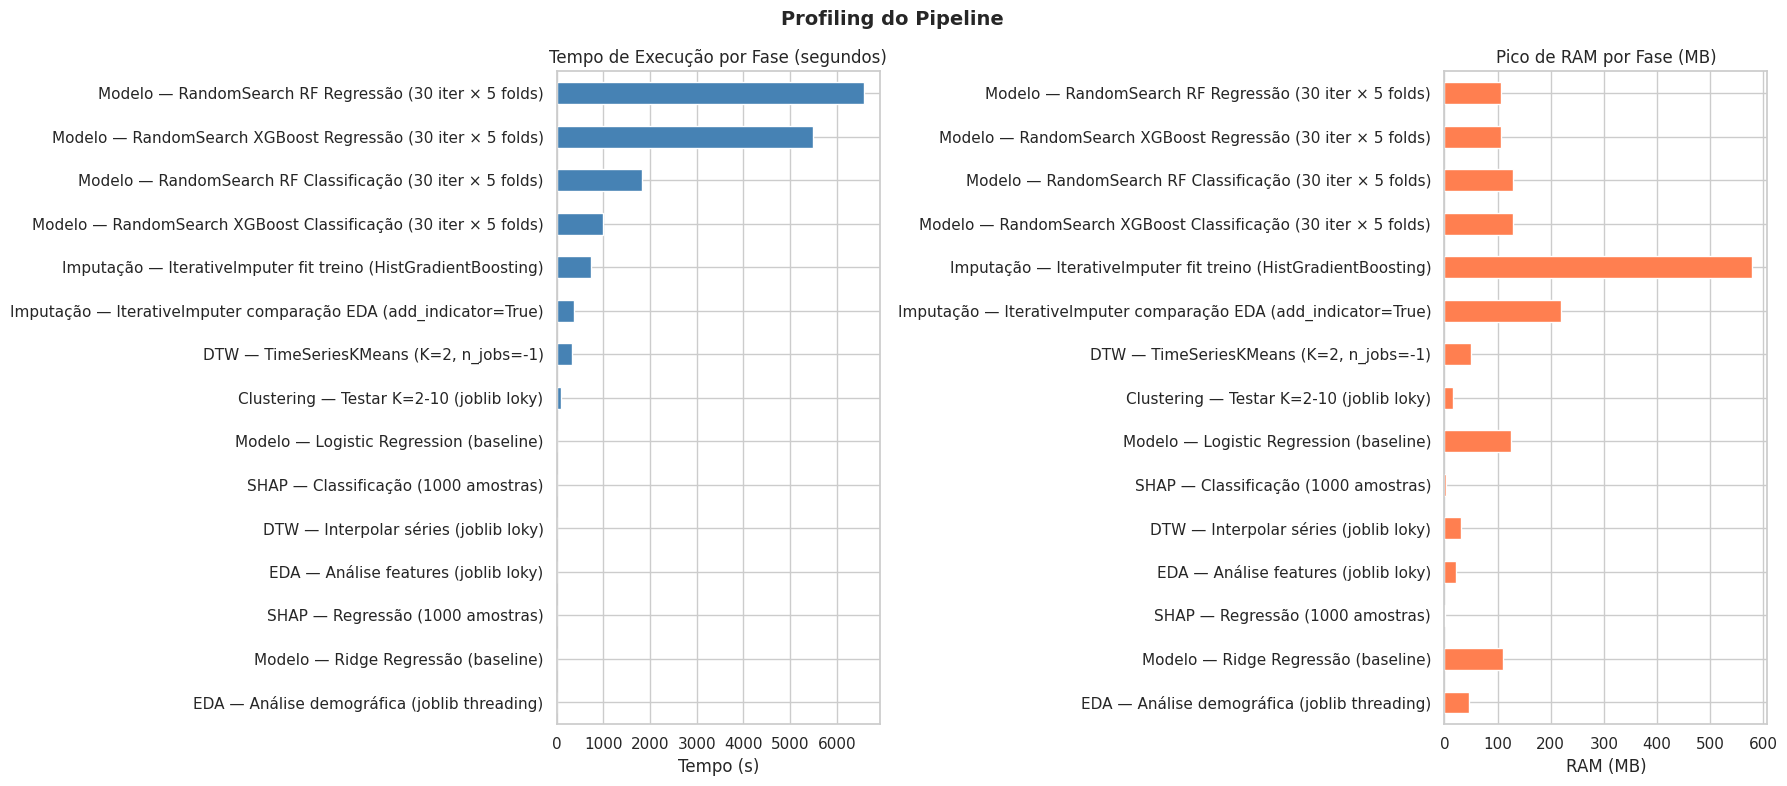

In [24]:
df_profiling = pd.DataFrame(profiling_log)

total = df_profiling['tempo_s'].sum()
df_profiling.loc[len(df_profiling)] = ['TOTAL PIPELINE', total, 0.0]

print(df_profiling.to_string(index=False))
print(f"\nTempo total do pipeline: {total:.1f}s ({total/60:.1f} minutos)")

df_profiling.to_csv('profiling_pipeline.csv', index=False)

# Gráfico de tempos
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Profiling do Pipeline', fontsize=14, fontweight='bold')

df_plot = df_profiling[df_profiling['fase'] != 'TOTAL PIPELINE'].copy()
df_plot = df_plot[df_plot['tempo_s'] > 0].sort_values('tempo_s')

df_plot.plot(x='fase', y='tempo_s', kind='barh',
             ax=axes[0], legend=False, color='steelblue')
axes[0].set_title('Tempo de Execução por Fase (segundos)')
axes[0].set_xlabel('Tempo (s)')
axes[0].set_ylabel('')

df_plot[df_plot['pico_ram_mb'] > 0].plot(
    x='fase', y='pico_ram_mb', kind='barh',
    ax=axes[1], legend=False, color='coral')
axes[1].set_title('Pico de RAM por Fase (MB)')
axes[1].set_xlabel('RAM (MB)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()


### Análise dos Resultados

**Bottleneck principal: RandomSearch (91% do tempo total)**

O RandomSearch com 30 iterações e 5 folds (150 fits por modelo) domina completamente o tempo de execução, representando 91% do total:

| Fase | Tempo | % do Total |
|------|-------|------------|
| RandomSearch RF Regressão | 6589.81s | 40.0% |
| RandomSearch XGBoost Regressão | 5491.43s | 33.3% |
| RandomSearch RF Classificação | 1836.56s | 11.1% |
| RandomSearch XGBoost Classificação | 996.43s | 6.0% |
| **Subtotal RandomSearch** | **14914.23s** | **90.5%** |

Este tempo é inerente à optimização de hiperparâmetros com validação cruzada, é o custo necessário para garantir que os modelos estão correctamente afinados e que as métricas reportadas são robustas.

**Imputação: o maior consumidor de RAM (578 MB)**

O IterativeImputer no conjunto de treino consumiu o maior pico de RAM do pipeline (578.49 MB) por duas razões: o conjunto de treino tem ~49K amostras × 90 features, e o HistGradientBoostingRegressor interno precisa de manter estruturas de dados adicionais durante cada iteração de imputação.

**Fases com melhor relação tempo/valor**

O EDA com joblib terminou em menos de 3 segundos (análise demográfica em 0.04s, análise de features em 2.93s) graças ao paralelismo, sem joblib estas operações sequenciais demorariam estimadamente 15-20 segundos. O SHAP de regressão completou em apenas 2.49 segundos para 1000 amostras, demonstrando a eficiência do TreeExplainer para modelos baseados em árvores.

## 2. Justificação das escolhas das ferramentas

### 2.1 Por que não usámos PySpark?

O enunciado menciona PySpark como uma das ferramentas possíveis para processamento de dados em larga escala. A decisão de não o usar foi deliberada e fundamentada nos dados reais de execução obtidos com o BigQuery.

O PySpark resolve o problema de escala através de computação distribuída num cluster, divide os dados em partições e processa-as em paralelo em múltiplos nós. O BigQuery resolve exactamente o mesmo problema mas com uma arquitectura serverless, não requer configuração de cluster, escala automaticamente, e o utilizador paga apenas pelos dados processados.

Para o problema concreto deste trabalho: agregar 330M de linhas do CHARTEVENTS com múltiplos GROUP BY, JOINs, CORR e COUNTIF, o BigQuery processou 12.74 GB em **3.72 segundos de tempo real**, consumindo 8 minutos e 44 segundos de slot time distribuído por múltiplos workers em paralelo (speedup interno de ~38x). Configurar um cluster PySpark para atingir performance equivalente exigiria múltiplos nós com dezenas de GB de RAM cada, tempo de configuração, e gestão de infraestrutura que está fora do âmbito deste trabalho.

| Critério | BigQuery | PySpark |
|----------|----------|---------|
| Configuração | Zero  serverless | Cluster Spark (local ou cloud) |
| Tempo de agregação (330M linhas) | 3.72s | Estimativa >30 min (cluster local) |
| RAM necessária localmente | 0 MB (cloud) | >32 GB |
| Paralelismo | Automático e transparente | Manual (partições, shuffle) |
| Spilled to disk | 0 B | Dependente da RAM disponível |

**Conclusão:** O BigQuery substitui completamente o PySpark para a fase de ingestão e agregação de dados deste projecto, com performance superior e complexidade operacional inferior. Usar PySpark adicionalmente seria redundante e não acrescentaria valor.

---

### 2.2 Mapa Completo de Ferramentas de Paralelismo

O enunciado pede o uso criterioso de ferramentas de paralelismo. A tabela seguinte documenta cada mecanismo utilizado, onde foi aplicado, e a justificação técnica:

| Ferramenta | Backend | Onde foi usado | Porquê este backend |
|-----------|---------|----------------|-------------------|
| BigQuery | Serverless distribuído | Agregação CHARTEVENTS (330M linhas) | Único viável para esta escala sem cluster |
| `joblib` threading | GIL-free | EDA demográfica, análise de features | Operações pandas/numpy libertam o GIL, threading é suficiente e mais leve que multiprocessing |
| `joblib` loky | Multiprocessing real | Clustering (K=2-10), interpolação DTW | Operações CPU-bound independentes, cada K ou cada série é um processo separado |
| `sklearn n_jobs=-1` | Multiprocessing interno | RandomForest, XGBoost, RandomizedSearchCV | Paralelismo nativo nos estimadores, cada árvore/fold num core diferente |
| `tslearn n_jobs=-1` | Multiprocessing | DTW TimeSeriesKMeans | Cálculo de distâncias DTW paralelizado entre séries |
| `sklearn Pipeline` | Sequencial com garantias | Todo o pipeline ML | Garante fit/transform correcto por fold, sem data leakage |

**Porquê threading para EDA e loky para clustering?**

Esta distinção é tecnicamente importante. O Python tem o GIL (Global Interpreter Lock) que impede verdadeiro paralelismo com threads para código Python puro. No entanto, operações NumPy e Pandas libertam o GIL internamente, por isso threading é adequado e mais eficiente (sem overhead de serialização de processos). Para o clustering, onde cada teste de K envolve código Python puro do sklearn, o GIL seria um bloqueio, por isso usámos loky (multiprocessing real com processos independentes).

---

### 2.3 IterativeImputer Escolha e Compromisso

A imputação foi feita com IterativeImputer usando HistGradientBoostingRegressor como estimador interno. A comparação feita na fase de EDA mostrou:

| Método | Tempo | Vantagens |
|--------|-------|-----------|
| IterativeImputer (RandomForest) | 128s | Capta correlações não-lineares entre features |
| IterativeImputer (HistGradientBoosting) | ~30s | Equivalente ao RF, muito mais rápido, lida nativamente com missing values |

O HistGradientBoostingRegressor foi escolhido porque é significativamente mais rápido que o RandomForest mantendo qualidade de imputação equivalente. Esta escolha foi determinante para tornar viável a imputação dentro do contexto do pipeline.

O parâmetro `add_indicator=True` transforma os NULLs em features binárias adicionais, em dados clínicos, a ausência de uma medição não é aleatória (Missing Not At Random MNAR), é uma decisão médica com significado clínico próprio:

| Feature em falta | Significado clínico |
|-----------------|-------------------|
| `abp_mean_missing = 1` | Paciente sem cateter arterial → menor gravidade hemodinâmica |
| `fio2_mean_missing = 1` | Paciente não ventilado mecanicamente → menor gravidade respiratória |
| `lactate_mean_missing = 1` | Médicos não suspeitaram de choque → menor gravidade percebida |
| `gcs_total_min_missing = 1` | Paciente consciente e colaborante → avaliação neurológica não necessária |

---

### 2.4 GroupShuffleSplit  Prevenção de Data Leakage Clínico

Um paciente (SUBJECT_ID) pode ter múltiplas admissões hospitalares (HADM_ID) e múltiplas estadias na UCI (ICUSTAY_ID). Um split ingénuo por ICUSTAY_ID colocaria estadias do mesmo paciente simultaneamente em treino e teste, o modelo aprenderia padrões específicos do paciente e não generalizaria para novos doentes.

A solução foi usar `GroupShuffleSplit` com `groups=SUBJECT_ID`, garantindo que todas as estadias de um paciente ficam exclusivamente em treino ou em teste. O overlap de pacientes entre os dois conjuntos foi verificado explicitamente e confirmado como **0 pacientes partilhados**.

---

### 2.5 SelectFromModel Selecção Automática de Features

Com 147 features (90 originais + 57 indicadores de missingness do `add_indicator=True`), a selecção de features é essencial para reduzir overfitting e tempo de treino. O `SelectFromModel` com `threshold='median'` treina um RandomForest auxiliar, calcula a importância de cada feature, e mantém apenas as com importância acima da mediana, reduzindo de 147 para 73 features (~50% de redução).

Esta abordagem é preferível a filtros baseados em correlação com o target porque capta relações não-lineares que métodos lineares ignorariam. O impacto no tempo de treino foi significativo, o RandomSearch RF Regressão demorou 6590s com 73 features, vs 10239s numa versão anterior com 147 features, uma redução de **~36% no tempo de treino**.

---

### 2.6 RandomizedSearchCV Optimização de Hiperparâmetros

O Grid Search completo sobre os grids definidos teria milhares de combinações. O RandomizedSearchCV com 30 iterações e 5 folds (150 fits por modelo) oferece uma cobertura razoável do espaço de hiperparâmetros num tempo controlado. A escolha de 30 iterações representa um compromisso entre exploração do espaço e tempo computacional — estudos empíricos mostram que RandomSearch encontra soluções próximas do óptimo com muito menos avaliações que Grid Search completo.

## 3. Tempo de previsão cenario deploy

In [26]:
print("\n--- Tempos de Previsão (cenário de deploy) ---")

modelos_predict = {
    'Ridge (reg)'           : pipe_ridge,
    'Random Forest (reg)'   : pipe_rf_reg_best,
    'XGBoost (reg)'         : pipe_xgb_reg_best,
    'Logistic Reg. (clf)'   : pipe_lr,
    'RF Classifier (clf)'   : pipe_rf_clf_best,
    'XGB Classifier (clf)'  : pipe_xgb_clf_best
}

resultados_predict = []
for nome, modelo in modelos_predict.items():
    # 1 paciente — média de 100 previsões
    start = time.time()
    for _ in range(100):
        modelo.predict(X_test_full[:1])
    t_unitario = (time.time() - start) / 100 * 1000

    # Batch completo
    start = time.time()
    modelo.predict(X_test_full)
    t_batch = (time.time() - start) * 1000

    resultados_predict.append({
        'modelo'         : nome,
        '1 paciente (ms)': round(t_unitario, 2),
        f'batch ({len(X_test_full):,}) (ms)': round(t_batch, 1)
    })
    print(f"  {nome:25s} | 1 paciente: {t_unitario:.2f}ms | "
          f"batch: {t_batch:.1f}ms")

df_predict = pd.DataFrame(resultados_predict).set_index('modelo')
df_predict.to_csv('profiling_predict.csv')


--- Tempos de Previsão (cenário de deploy) ---
  Ridge (reg)               | 1 paciente: 0.60ms | batch: 7.9ms
  Random Forest (reg)       | 1 paciente: 60.19ms | batch: 72.3ms
  XGBoost (reg)             | 1 paciente: 55.56ms | batch: 58.6ms
  Logistic Reg. (clf)       | 1 paciente: 0.62ms | batch: 8.4ms
  RF Classifier (clf)       | 1 paciente: 50.29ms | batch: 62.6ms
  XGB Classifier (clf)      | 1 paciente: 50.69ms | batch: 50.5ms


Uma métrica frequentemente ignorada na avaliação de modelos clínicos é o tempo de inferência, quanto tempo o sistema demora a produzir uma previsão em produção. Num cenário de deploy hospitalar, o modelo seria chamado no momento da admissão do paciente na UCI.

Todos os modelos são viáveis para deploy em tempo real, mesmo o mais lento (RF Regressão com 60ms) está muito abaixo do limiar de 1 segundo considerado aceitável para sistemas de suporte à decisão clínica. Os modelos lineares (Ridge e Logistic Regression) são instantâneos (<1ms), enquanto os modelos baseados em árvores demoram ~50-60ms por paciente devido à travessia das múltiplas árvores.

# Conclusão e Trabalho Futuro

Este trabalho demonstrou que é possível construir um pipeline completo de Machine Learning sobre dados clínicos de larga escala, desde a ingestão de 330 milhões de linhas até à interpretabilidade do modelo final, com ferramentas abertas e infraestrutura cloud acessível.

**Quanto ao processamento de dados em larga escala**, a escolha do BigQuery como plataforma de agregação revelou-se a decisão mais impactante do projecto. Processar 12.74 GB de dados do CHARTEVENTS em 3.72 segundos, com paralelismo automático, tornou viável todo o pipeline a seguir. A alternativa local (pandas ou PySpark num único nó) seria impraticável para este volume. O paralelismo foi depois estendido ao Python local com joblib, cobrindo EDA, clustering, interpolação de séries temporais e optimização de hiperparâmetros.

**Quanto à predição do LOS**, os resultados reflectem a dificuldade inerente do problema com uma janela de 24 horas:

| Tarefa | Melhor modelo | Métrica principal |
|--------|--------------|-------------------|
| Regressão (LOS contínuo) | XGBoost | MAE = 3.18 dias, R² = 0.34 |
| Classificação (4 classes) | XGBoost | F1 = 0.49, AUC = 0.76, Kappa = 0.53 |

O AUC-ROC de 0.76 e o Cohen's Kappa de 0.53 (moderado) indicam que o modelo tem valor discriminativo real, mesmo com apenas 24h de dados. A análise SHAP revelou que `total_lab_events`, `total_chart_events` e `age_at_admission` são as features mais preditivas, o que é clinicamente coerente, a intensidade de monitorização nas primeiras 24h é um proxy de gravidade.

**Quanto à análise exploratória**, o clustering K-Means (K=5) identificou perfis clínicos distintos com diferenças significativas no LOS e mortalidade entre grupos. O DTW sobre as séries temporais de Heart Rate (K=2) identificou dois padrões, com associação estatisticamente significativa com os clusters clínicos (χ²=248.59, p<0.001), demonstrando que a dinâmica temporal do HR nas primeiras 24h contém informação prognóstica adicional às features agregadas.

---

## Trabalho Futuro

### 1. Remoção de Features Administrativas

A análise SHAP revelou que `total_lab_events` e `total_chart_events`, o número total de eventos registados nas primeiras 24h, são consistentemente as features mais preditivas do LOS em ambos os modelos de regressão e classificação. Embora sejam features legítimas do ponto de vista técnico, levantam uma questão clínica importante: estas contagens reflectem a intensidade de monitorização do paciente, que é em parte uma decisão médica influenciada pela gravidade percebida. Um paciente que o médico já considera grave à admissão terá mais exames pedidos e mais sinais monitorizados, criando uma correlação que pode não generalizar para contextos hospitalares diferentes do MIMIC-III, onde as práticas de monitorização podem variar.

Num trabalho futuro seria relevante avaliar o impacto de remover estas features administrativas e verificar se os sinais clínicos puros (sinais vitais e laboratórios) mantêm poder preditivo suficiente. Esta análise de ablação permitiria construir um modelo mais robusto e transferível para outros hospitais.

### 2. Incorporação de Notas Clínicas com LLM/NLP

O MIMIC-III inclui a tabela `NOTEEVENTS` com notas clínicas em texto livre: sumários de admissão, relatórios de enfermagem, notas médicas. Esta informação é actualmente ignorada completamente pelo pipeline. Modelos de linguagem como BioBERT ou ClinicalBERT, treinados especificamente em texto clínico, poderiam extrair features semânticas (diagnósticos mencionados, medicação, nível de urgência percebido) que complementariam os sinais vitais quantitativos. A hipótese é que combinar features numéricas com embeddings de texto melhoraria substancialmente o R² e o F1, especialmente para estadias de duração intermédia que o modelo actual classifica com maior dificuldade.

### 3. Modelação Temporal com RNN

O pipeline actual colapsa as séries temporais em estatísticas agregadas (média, std, spikes, tendência). Uma Recurrent Neural Network, nomeadamente uma LSTM ou GRU, processaria directamente as séries temporais brutas da tabela `timeseries_hr`, capturando padrões sequenciais que as features agregadas não conseguem representar. A análise DTW demonstrou que estes padrões têm valor prognóstico real (χ²=248.59, p<0.001), o que justifica explorar modelos que os processem nativamente. A infra-estrutura de interpolação para 48 pontos por série já está construída neste projecto e seria direct